# DR-VERGE Enhanced — Supplementary Analysis v2 (inference-only)

**Spec:** `DRVERGE_Enhanced_Supplementary_Master_Prompt_v2.md` · **Frozen source run:** `artifacts_enhanced_v1_20260811`
· **Builds on:** supplementary v1 (its validated inference cache is re-used, read-only).

The notebook answers five questions with stronger evidence, **without training, tuning, re-quantising, changing thresholds
or re-selecting any model**:
1. How strongly does CSD improve mechanism fidelity relative to the three baselines? (**P1**)
2. Does the pattern persist under external domain shift (DeepDRiD Set-C)? (**P2**, exploratory)
3. Why can mechanism fidelity improve without improving QWK? (**P3**, exact decomposition)
4. Which grades remain difficult and where do their errors go? (**P4**)
5. Are the conclusions robust to Pearson vs Spearman, and how do the ordinal threshold scores calibrate? (**P5**)

| Phase | Content | On failure |
|---|---|---|
| P0 | preflight, SHA-256, strict state-dict loads, locked config, smoke reproduction | **stop** (`BLOCKED.md`) |
| P1 | 20-student cache → full reproduction gate → 9 paired contrasts + sensitivity | **stop** |
| P2 | Set-C integrity → external reproduction → patient-clustered statistics | P2 reported as blocked; rest continues |
| P3 | decomposition identity, teacher-correctness subgroups, teacher-shift bins | identity failure stops |
| P4 | per-grade precision/recall/F1, Grade-1 error direction | non-blocking |
| P5 | Pearson vs Spearman, ordinal calibration reproduced from the source definition | P5 reported as blocked; rest continues |
| P6 | original deployment benchmark summary (read-only, never re-timed) | skipped if unavailable |

**Run:** `Runtime → Run all` (GPU recommended). Outputs go to `artifacts_enhanced_supplementary_v2_20261029/`; the
paper-ready package is in `paper_ready/`.

In [1]:
# ---- 0. Runtime: Drive + the packages the source notebook pinned ----
import os, sys, subprocess
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")      # same as the source notebook
os.environ.setdefault("NO_ALBUMENTATIONS_UPDATE", "1")
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "albumentations==1.4.21",
                    "openpyxl>=3.1"], check=False)
print("Colab:", IN_COLAB)

Mounted at /content/drive
Colab: True


## 1 — Configuration
Only the `EDIT ONLY THESE` block is meant to be edited. Everything below it is locked from the source run and verified
against the original artifact tree at runtime.

In [2]:
import json, glob, time, math, hashlib, gc, copy, warnings, platform, shutil
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
torch.set_grad_enabled(False)          # inference-only notebook: autograd is OFF globally

# ---------------- EDIT ONLY THESE ----------------
DRIVE_BASE     = os.environ.get("DRVERGE_DRIVE_BASE", "/content/drive/MyDrive/DR-VERGE")
ORIG_RUN_TAG   = "enhanced_v1_20260811"                  # frozen Enhanced run (read-only)
SUPP_TAG       = "enhanced_supplementary_v2_20261029"    # NEW output tree of this notebook
V1_SUPP_TAG    = "enhanced_supplementary_v1_20261029"    # supplementary v1 (read-only cache source)
REUSE_V1_CACHE = True        # import v1 inference only if checkpoint/data/file hashes all match
INFER_DEVICE   = "auto"      # "auto" | "cuda" | "cpu"
RUN_EXTERNAL   = True        # P2 (DeepDRiD Set-C)
RUN_P5         = True        # Pearson/Spearman + ordinal calibration
RUN_P6         = True        # original deployment benchmark summary (no re-timing)
FORCE_REINFER  = False       # True ignores every cache (original files are never touched)
STAT_MODE      = "final"     # "final" (B = 10,000, paper-ready) | "debug" (B = 500, NEVER reported)
RNG_SEED       = 20261029    # every bootstrap/permutation draw derives from this
# -------------------------------------------------
if STAT_MODE not in ("final", "debug"):
    raise ValueError("STAT_MODE must be 'final' or 'debug'")
B_FINAL, P_PERM, B_PILOT = (10000, 10000, 1000) if STAT_MODE == "final" else (500, 500, 200)

# ================= LOCKED (verified against the original artifacts below) =================
CORE_CONDITIONS = ["dual_no_distill", "dual_logitkd", "dual_featkd", "dual_csd"]
BASELINES = ["dual_no_distill", "dual_logitkd", "dual_featkd"]
CSD = "dual_csd"
LABEL = {"teacher": "Teacher", "dual_no_distill": "NoDistill", "dual_logitkd": "Logit-KD",
         "dual_featkd": "Feature-KD", "dual_csd": "CSD"}
SEEDS_CORE = [42, 123, 2026, 3407, 8888]
IMG_SIZE, SAMPLING = 384, "standard"
NUM_CLASSES = 5
NUM_THRESHOLDS = NUM_CLASSES - 1
STUDENT_CHANNELS = (32, 64, 96, 128, 160, 192, 224)
DRTID_MEAN, DRTID_STD = [0.372487, 0.217266, 0.119367], [0.281526, 0.179457, 0.109162]
LOCKED_THRESHOLDS = {"dual_no_distill": 0.40, "dual_logitkd": 0.50, "dual_featkd": 0.50, "dual_csd": 0.50}
TEACHER_THRESHOLD = 0.5      # source thr_for("teacher") falls through to 0.5 (teacher is never calibrated)
LOCKED_HPARAMS = {"logitkd": {"alpha": 0.5, "tau_kd": 2.0}, "featkd": {"gamma_feat": 2.0},
                  "csd_variant": "smoothl1_norm", "csd_beta": 0.1}
SELECTED_METHOD = "dual_csd"           # M*, validation-only; NOT re-selected here
INTERNAL_BATCH, EXTERNAL_BATCH = 8, 16  # same loaders as the source (eval-mode BN: batch-invariant)
N_INTERNAL, N_EXT_EYES, N_EXT_PATIENTS = 550, 200, 100
DEEPDRID_PRIMARY_ORDER = "_1=macula"   # pre-registered field order of the source run
METRICS = ["ShiftL1", "CosAgree", "BenefitCorr"]
BETTER = {"ShiftL1": "lower", "CosAgree": "higher", "BenefitCorr": "higher", "BenefitCorrSpearman": "higher"}
EXPECTED_SPLIT_SHA256 = {
    "train": "4384272e5455d75ef1e5e49dc6ba8a700de4ce97efd0c8809622ed649e87c5fa",
    "val":   "66609c6786621311a56e1207b11176c59dc7108e0f52b9a6c2361fb35bca3529",
    "test":  "6191ea9808fac2133e0efc9052dfa62309ceabf5293cd079a3a20e2cbcd12124"}
REPO_SOURCE_NOTEBOOK_SHA256 = "72398b3377ae195796b9a359aeee97b4884c51c6bd19246cc0a1277a2b95f1cb"
# Published 4-decimal values (paper). A SECOND reproduction reference; the primary reference is the full-precision
# per-seed file of the source run (results/metrics/all_conditions_raw.csv).
PAPER_REFERENCE = {
    "teacher_QWK": 0.7364,
    "QWK":         {"dual_no_distill": 0.6042, "dual_logitkd": 0.5942, "dual_featkd": 0.6161, "dual_csd": 0.6018},
    "ShiftL1":     {"dual_no_distill": 0.3759, "dual_logitkd": 0.3840, "dual_featkd": 0.3718, "dual_csd": 0.3509},
    "CosAgree":    {"dual_no_distill": 0.3509, "dual_logitkd": 0.2858, "dual_featkd": 0.3815, "dual_csd": 0.4361},
    "BenefitCorr": {"dual_no_distill": 0.2193, "dual_logitkd": 0.1795, "dual_featkd": 0.1943, "dual_csd": 0.3075},
    "ext_teacher_QWK": 0.7923, "ext_csd_QWK": 0.6688,
    "dQWK":        {"dual_no_distill": -0.0024, "dual_logitkd": 0.0077, "dual_featkd": -0.0143}}
# Reproduction tolerances (absolute). A real preprocessing/model error moves probabilities by >= 1e-2 on average and is
# always caught. A QWK gap is accepted ONLY when every changed grade is a near-threshold tie (saved probability within
# `flip_margin` of the frozen threshold, at most 2% of records) AND the saved-prediction QWK equals the reference.
TOL = {"prob_max": 1e-2, "prob_mean": 5e-4, "grade_agree_min": 0.995, "flip_margin": 5e-3, "flip_max_frac": 0.02,
       "mech_seed": 2e-3, "mech_mean": 5e-4, "qwk_seed": 5e-3, "qwk_mean": 1e-3,
       "paper_round": 5e-4, "impl_crosscheck": 5e-5,
       "ext_grade_agree_min": 0.99, "ext_qwk_seed": 1e-2, "ext_qwk_mean": 2e-3,
       "calib_brier": 2e-4, "calib_ece": 3e-3}
SCHEMA_VERSION, V1_SCHEMA = "drverge-supp-cache-v2", "drverge-supp-cache-v1"
PREPROCESSING = {"input_size": [IMG_SIZE, IMG_SIZE], "resize": "albumentations.Resize (cv2 INTER_LINEAR)",
                 "normalize_mean": DRTID_MEAN, "normalize_std": DRTID_STD, "max_pixel_value": 255.0,
                 "horizontal_flip": False, "augmentation": None, "albumentations_pin": "1.4.21",
                 "drtid_views": {"macula": "macula_filename", "disc": "disc_filename"},
                 "deepdrid_field_order": DEEPDRID_PRIMARY_ORDER}
PREP_FP = hashlib.sha256(json.dumps(PREPROCESSING, sort_keys=True).encode()).hexdigest()
# ==========================================================================================

def _find_drtid(root):
    for c in (f"{root}/DRTiD/DRTiD", f"{root}/DRTiD"):
        if os.path.exists(f"{c}/Ground Truths/DR_grade/a. DR_grade_Training.csv"):
            return c
    return None

def _find_deepdrid(root):
    for c in (f"{root}/DeepDRiD-master/regular_fundus_images", f"{root}/DeepDRiD/regular_fundus_images",
              f"{root}/DeepDRiD-master", f"{root}/DeepDRiD"):
        if os.path.exists(f"{c}/regular-fundus-validation/regular-fundus-validation.csv"):
            return c
    return None

def discover_original_artifacts():
    """The source tree is DRIVE_BASE/artifacts_<RUN_TAG>. Verified on disk, never assumed."""
    want = f"{DRIVE_BASE}/artifacts_{ORIG_RUN_TAG}"
    if os.path.isdir(want):
        return want, []
    roots = {os.path.dirname(DRIVE_BASE.rstrip("/")), DRIVE_BASE}
    cands = sorted({p for r in roots for p in
                    glob.glob(f"{r}/artifacts_{ORIG_RUN_TAG}") + glob.glob(f"{r}/*/artifacts_{ORIG_RUN_TAG}")
                    if os.path.isdir(p)})
    others = sorted(glob.glob(f"{DRIVE_BASE}/artifacts_*"))
    return (cands[0] if len(cands) == 1 else None), (cands if len(cands) != 1 else []) + others

ORIG_ART, _alts = discover_original_artifacts()
if ORIG_ART is None:
    raise RuntimeError(f"Original artifact tree artifacts_{ORIG_RUN_TAG} NOT found under {DRIVE_BASE}. "
                       f"Candidates seen: {_alts}. Set DRIVE_BASE correctly -- nothing will be retrained.")
if os.path.abspath(os.path.dirname(ORIG_ART)) != os.path.abspath(DRIVE_BASE):
    print(f"NOTE: original run found at {ORIG_ART} (not directly under DRIVE_BASE); using its parent.")
    DRIVE_BASE = os.path.dirname(ORIG_ART)
SUPP_ART = f"{DRIVE_BASE}/artifacts_{SUPP_TAG}"
V1_ART = f"{DRIVE_BASE}/artifacts_{V1_SUPP_TAG}"
for _p, _n in ((ORIG_ART, "original"), (V1_ART, "v1 supplementary")):
    if os.path.abspath(SUPP_ART) == os.path.abspath(_p) or os.path.abspath(SUPP_ART).startswith(os.path.abspath(_p) + os.sep):
        raise RuntimeError(f"SUPP_ART must not be (inside) the {_n} tree")
DATASET_ROOT = f"{DRIVE_BASE}/dataset"
DRTID_ROOT = _find_drtid(DATASET_ROOT)
DRTID_IMAGE_ROOT = f"{DRTID_ROOT}/Original Images" if DRTID_ROOT else None
DEEPDRID_ROOT = _find_deepdrid(DATASET_ROOT)

O_CKPT, O_CFG, O_SPLIT = f"{ORIG_ART}/checkpoints", f"{ORIG_ART}/configs", f"{ORIG_ART}/splits"
O_RES = f"{ORIG_ART}/results"
O_MET, O_TAB, O_PRED = f"{O_RES}/metrics", f"{O_RES}/tables", f"{O_RES}/predictions"
TEACHER_CKPT = f"{O_CKPT}/teacher_{IMG_SIZE}_{SAMPLING}.pt"
def student_ckpt(cond, seed): return f"{O_CKPT}/student/{cond}/seed{seed}.pt"

LOGS, CACHE, TABLES = f"{SUPP_ART}/logs", f"{SUPP_ART}/cache", f"{SUPP_ART}/tables"
FIGS, REPORTS, PAPER = f"{SUPP_ART}/figures", f"{SUPP_ART}/reports", f"{SUPP_ART}/paper_ready"
for _d in (SUPP_ART, LOGS, CACHE, TABLES, FIGS, REPORTS, PAPER, f"{CACHE}/internal", f"{CACHE}/external",
           f"{LOGS}/pilot"):
    os.makedirs(_d, exist_ok=True)

print("original (read-only):", ORIG_ART)
print("v1 cache (read-only):", V1_ART, "| exists:", os.path.isdir(V1_ART))
print("v2 outputs          :", SUPP_ART)
print("DRTiD               :", DRTID_ROOT)
print("DeepDRiD            :", DEEPDRID_ROOT)
print("statistics mode     :", STAT_MODE, f"(B={B_FINAL}, permutations={P_PERM})")

original (read-only): /content/drive/MyDrive/DR-VERGE/artifacts_enhanced_v1_20260811
v1 cache (read-only): /content/drive/MyDrive/DR-VERGE/artifacts_enhanced_supplementary_v1_20261029 | exists: True
v2 outputs          : /content/drive/MyDrive/DR-VERGE/artifacts_enhanced_supplementary_v2_20261029
DRTiD               : /content/drive/MyDrive/DR-VERGE/dataset/DRTiD
DeepDRiD            : /content/drive/MyDrive/DR-VERGE/dataset/DeepDRiD-master/regular_fundus_images
statistics mode     : final (B=10000, permutations=10000)


## 2 — Guarded I/O, runtime profile, gates
Every writer refuses paths outside the v2 tree (so the original run and the v1 supplementary tree are read-only) and
writes atomically. Every gate carries the number of the Master-Prompt-v2 §16 gate it implements.

In [3]:
class SupplementaryBlocked(RuntimeError):
    pass

_SUPP_ABS = os.path.abspath(SUPP_ART)
_READONLY_ABS = [os.path.abspath(ORIG_ART), os.path.abspath(V1_ART)]

def _guard(path):
    ap = os.path.abspath(path)
    for ro in _READONLY_ABS:
        if ap == ro or ap.startswith(ro + os.sep):
            raise SupplementaryBlocked(f"REFUSED: write inside a read-only tree: {path}")
    if not ap.startswith(_SUPP_ABS + os.sep):
        raise SupplementaryBlocked(f"REFUSED: write outside the v2 supplementary tree: {path}")
    os.makedirs(os.path.dirname(ap), exist_ok=True)
    return ap

def _atomic(path, writer):
    ap = _guard(path)
    tmp = ap + ".tmp"
    for i in range(4):                    # Drive's FUSE mount occasionally rejects a write
        try:
            writer(tmp); os.replace(tmp, ap); return ap
        except OSError as e:
            if i == 3: raise
            print(f"  write retry {i+1}: {e}"); time.sleep(1.5 * (i + 1))

def _jsonable(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

def write_text(path, text):
    def w(p):
        with open(p, "w", encoding="utf-8") as f: f.write(text)
    return _atomic(path, w)

def write_json(obj, path):
    return write_text(path, json.dumps(obj, indent=2, default=_jsonable))

def write_csv(df, path, **kw):
    return _atomic(path, lambda p: df.to_csv(p, index=False, **kw))

def copy_into(src, dst):
    return _atomic(dst, lambda p: shutil.copyfile(src, p))

try:
    import pyarrow  # noqa: F401
    HAVE_PARQUET = True
except ImportError:
    HAVE_PARQUET = False

def write_table(df, base):
    if HAVE_PARQUET:
        return _atomic(base + ".parquet", lambda p: df.to_parquet(p, index=False))
    return _atomic(base + ".csv", lambda p: df.to_csv(p, index=False, float_format="%.9g"))

def read_table(base):
    if os.path.exists(base + ".parquet") and HAVE_PARQUET: return pd.read_parquet(base + ".parquet")
    if os.path.exists(base + ".csv"): return pd.read_csv(base + ".csv", dtype={"sample_id": str})
    raise FileNotFoundError(base)

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

def sha256_lf(path):
    with open(path, "rb") as f: data = f.read()
    return hashlib.sha256(data.replace(b"\r\n", b"\n")).hexdigest()

def sha256_bytes(b): return hashlib.sha256(b).hexdigest()

def remove_stale(paths):
    """Delete earlier outputs of THIS v2 tree only (guarded)."""
    for p in paths:
        if os.path.exists(p):
            os.remove(_guard(p))

# ---- runtime profile (spec §5.3) ----
RUNTIME = []
def tic(phase, stage):
    return {"phase": phase, "stage": stage, "t0": time.time()}
def toc(t, note=""):
    RUNTIME.append({"phase": t["phase"], "stage": t["stage"], "seconds": round(time.time() - t["t0"], 2), "note": note})
    write_csv(pd.DataFrame(RUNTIME), f"{LOGS}/runtime_profile.csv")

# ---- gates (spec §16) ----
SPEC_GATES = {
    "G01": "required checkpoints present and hashed", "G02": "no optimizer/backward/training executed",
    "G03": "original artifact directory unmodified", "G04": "DRTiD test = 550 records",
    "G05": "Set-C = 100 patients / 200 eyes", "G06": "field order preserved", "G07": "frozen thresholds preserved",
    "G08": "cumulative outputs finite and in range", "G09": "CORAL monotonicity as original",
    "G10": "teacher output identical across comparisons", "G11": "QWK reproduced", "G12": "ShiftL1 reproduced",
    "G13": "CosAgree reproduced", "G14": "BenefitCorr reproduced", "G15": "BenefitCorr spot-check",
    "G16": "paired ID joins preserve matching", "G17": "Set-C patient clusters never split",
    "G18": "identical-method zero effect", "G19": "contrast reversal negates effect/CI",
    "G20": "row shuffle leaves results unchanged", "G21": "fixed RNG reproducible",
    "G22": "NaN/constant replicates counted", "G23": "cache hash/schema blocks stale reuse",
    "G24": "figures generated from saved tables", "G25": "paper claims trace to result files"}
REPRO_SPECS = {"G11", "G12", "G13", "G14"}
GATES = []
PHASE_STATUS = {p: "NOT_RUN" for p in ("P0", "P1", "P2", "P3", "P4", "P5", "P6", "FINAL")}

def gate(name, passed, detail="", blocking=True, phase="P0", spec=""):
    GATES.append({"phase": phase, "spec_gate": spec, "gate": name, "passed": bool(passed), "blocking": bool(blocking),
                  "detail": str(detail), "time": time.strftime("%Y-%m-%dT%H:%M:%S")})
    print(f"{'PASS' if passed else ('FAIL' if blocking else 'WARN')} | {phase} | {spec or '   '} | {name}"
          + (f" | {detail}" if detail else ""))
    write_csv(pd.DataFrame(GATES), f"{LOGS}/gate_report.csv")
    if blocking and not passed:
        note = (f"# BLOCKED at {phase} / {name} ({spec})\n\n{detail}\n\nNothing was retrained, tuned or re-selected. "
                "Trace the mismatch in logs/reproduction_checks.csv before changing anything.\n")
        write_text(f"{REPORTS}/BLOCKED_{phase}_{name}.md", note)
        if phase in ("P0", "P1", "P3"):              # essential phases: spec §6 BLOCKED.md
            write_text(f"{SUPP_ART}/BLOCKED.md", note)
        if spec in REPRO_SPECS or "Reproduction" in name or "Smoke" in name:
            write_text(f"{REPORTS}/REPRODUCTION_FAILURE_REPORT.md", note +
                       "\nChecked items: preprocessing, field order, sample order, checkpoint mapping, threshold, "
                       "eval mode, architecture. Metric definitions were NOT altered.\n")
        raise SupplementaryBlocked(f"{phase}/{name}: {detail}")
    return bool(passed)

RUN_LOG = []
def stage_report(phase, title, lines):
    RUN_LOG.append({"phase": phase, "title": title, "lines": list(lines)})
    md = "\n\n".join(f"## {s['phase']} — {s['title']}\n\n" + "\n".join(f"- {l}" for l in s["lines"]) for s in RUN_LOG)
    rt = pd.DataFrame(RUNTIME)
    rt_md = rt.to_string(index=False) if len(rt) else "(no timings yet)"
    write_text(f"{REPORTS}/RUN_LOG.md", "# Run log\n\n" + md + "\n\n## Runtime profile (seconds)\n\n```\n" + rt_md + "\n```\n")

# per-run markers and blocker notes are cleared so a re-run never leaves a stale marker next to fresh results
remove_stale(glob.glob(f"{LOGS}/SUPPLEMENTARY_RUN_*.txt") + glob.glob(f"{REPORTS}/BLOCKED_*.md")
             + [f"{SUPP_ART}/BLOCKED.md", f"{REPORTS}/REPRODUCTION_FAILURE_REPORT.md",
                f"{LOGS}/DEBUG_MODE_RESULTS_NOT_FOR_PAPER.txt"])
print("guarded I/O ready | parquet:", HAVE_PARQUET)

guarded I/O ready | parquet: True


## 3 — Frozen definitions (copied verbatim from the source notebook, training code excluded)
Sources: §6 (data), §7 (models), §9 (metrics, `calibration`, `all_metrics`), evaluation helpers (`_nll`, `delta`,
`shift_fidelity`). One deliberate difference: `tv.resnet50(weights=None)` — every teacher parameter/buffer is overwritten by
`load_state_dict(strict=True)`, so no ImageNet download is needed.

In [4]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import torchvision, torchvision.models as tv
from sklearn.metrics import (confusion_matrix, f1_score, precision_recall_fscore_support,
                             balanced_accuracy_score, cohen_kappa_score)
from scipy import stats as sps

# ---- models (source §7) ----
class CORALHead(nn.Module):
    def __init__(self, in_dim, num_classes=NUM_CLASSES, init=None):
        super().__init__()
        self.k = num_classes - 1
        self.fc = nn.Linear(in_dim, 1, bias=False)
        t = torch.tensor(list(init if init is not None else [-0.7 * i for i in range(self.k)]),
                         dtype=torch.float32)
        gaps = (t[:-1] - t[1:]).clamp_min(1e-4)
        self.base_bias = nn.Parameter(t[0].clone())
        self.bias_steps = nn.Parameter(torch.log(torch.expm1(gaps)).clone())
    def biases(self):
        steps = F.softplus(self.bias_steps)
        return self.base_bias - torch.cat([torch.zeros(1, device=steps.device), torch.cumsum(steps, 0)])
    def forward(self, z):
        logits = self.fc(z) + self.biases().unsqueeze(0)
        return logits, torch.sigmoid(logits)

class InteractionFusion(nn.Module):
    def __init__(self, feat_dim, hidden=None):
        super().__init__()
        hidden = hidden or feat_dim
        self.norm_in  = nn.LayerNorm(feat_dim * 4)
        self.proj     = nn.Linear(feat_dim * 4, hidden)
        self.act      = nn.ReLU(inplace=True)
        self.norm_out = nn.LayerNorm(hidden)
        self.out_dim  = hidden
    def forward(self, zm, zd):
        return self.norm_out(self.act(self.proj(
            self.norm_in(torch.cat([zm, zd, torch.abs(zm - zd), zm * zd], dim=1)))))

class DWSepBlock(nn.Module):
    def __init__(self, i, o, stride=1):
        super().__init__()
        self.dw, self.bn1, self.act1 = nn.Conv2d(i, i, 3, stride, 1, groups=i, bias=False), nn.BatchNorm2d(i), nn.ReLU(inplace=True)
        self.pw, self.bn2, self.act2 = nn.Conv2d(i, o, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)
    def forward(self, x): return self.act2(self.bn2(self.pw(self.act1(self.bn1(self.dw(x))))))

class LightBackbone(nn.Module):
    def __init__(self, channels=STUDENT_CHANNELS):
        super().__init__()
        ch = tuple(channels)
        self.stem_conv = nn.Conv2d(3, ch[0], 3, 2, 1, bias=False)
        self.stem_bn, self.stem_act = nn.BatchNorm2d(ch[0]), nn.ReLU(inplace=True)
        strides = [2 if i % 2 == 0 else 1 for i in range(len(ch) - 1)]
        self.blocks = nn.ModuleList([DWSepBlock(ch[i], ch[i + 1], strides[i]) for i in range(len(ch) - 1)])
        self.gap, self.out_dim = nn.AdaptiveAvgPool2d(1), ch[-1]
    def forward(self, x):
        x = self.stem_act(self.stem_bn(self.stem_conv(x)))
        for b in self.blocks: x = b(x)
        return self.gap(x).flatten(1)

class DualViewBase(nn.Module):
    def forward(self, macula, disc):
        zm, zd = self.backbone(macula), self.backbone(disc)
        zf = self.fusion(zm, zd)
        ld, pd_ = self.main_head(zf)
        lm, pm = self.macula_head(zm)
        ldd, pdd = self.disc_head(zd)
        return {"p_dual": pd_, "logit_dual": ld, "p_macula": pm, "logit_macula": lm,
                "p_disc": pdd, "logit_disc": ldd, "z_fused": zf}

class Teacher(DualViewBase):
    def __init__(self, feat_dim=2048, init=None):
        super().__init__()
        bb = tv.resnet50(weights=None); bb.fc = nn.Identity()   # weights come from the checkpoint
        self.backbone = bb
        self.fusion = InteractionFusion(feat_dim)
        self.main_head = CORALHead(self.fusion.out_dim, NUM_CLASSES, init)
        self.macula_head = CORALHead(feat_dim, NUM_CLASSES, init)
        self.disc_head = CORALHead(feat_dim, NUM_CLASSES, init)

class Student(DualViewBase):
    def __init__(self, backbone=None, init=None):
        super().__init__()
        self.backbone = backbone or LightBackbone()
        fd = self.backbone.out_dim
        self.fusion = InteractionFusion(fd)
        self.main_head = CORALHead(self.fusion.out_dim, NUM_CLASSES, init)
        self.macula_head = CORALHead(fd, NUM_CLASSES, init)
        self.disc_head = CORALHead(fd, NUM_CLASSES, init)

def param_count(m): return int(sum(p.numel() for p in m.parameters()))

# ---- data (source §6, evaluation path only) ----
IMAGE_CACHE, _RESIZERS = {}, {}
def load_img(path, size=None):
    size = size or IMG_SIZE
    key = (path, size)
    a = IMAGE_CACHE.get(key)
    if a is None:
        r = _RESIZERS.get(size)
        if r is None: r = _RESIZERS[size] = A.Resize(size, size)
        a = r(image=np.array(Image.open(path).convert("RGB")))["image"]
        IMAGE_CACHE[key] = a
    return a

def prefill_cache(paths, label, workers=8, chunk=32):
    """Parallel JPEG decode (Drive I/O bound); resizing stays in the main thread exactly as load_img does it."""
    size = IMG_SIZE
    r = _RESIZERS.get(size)
    if r is None: r = _RESIZERS[size] = A.Resize(size, size)
    todo = [p for p in dict.fromkeys(paths) if (p, size) not in IMAGE_CACHE]
    dec = lambda p: np.array(Image.open(p).convert("RGB"))
    with ThreadPoolExecutor(workers) as ex:
        for i in tqdm(range(0, len(todo), chunk), desc=f"decoding {label}", leave=False):
            part = todo[i:i + chunk]
            for p, arr in zip(part, ex.map(dec, part)):
                IMAGE_CACHE[(p, size)] = r(image=arr)["image"]
    print(f"  {label}: {len(todo)} decoded, cache {len(IMAGE_CACHE)} arrays")

def build_tf(train, mean, std, size=None):
    assert not train, "this notebook never builds a training transform"
    return A.Compose([A.Resize(size or IMG_SIZE, size or IMG_SIZE), A.Normalize(mean=mean, std=std), ToTensorV2()])

eval_tf = build_tf(False, DRTID_MEAN, DRTID_STD)

class DualViewDataset(Dataset):
    def __init__(self, csv, transform=None, image_root=None, size=None):
        self.size = size or IMG_SIZE
        self.df = pd.read_csv(csv)
        root = image_root or DRTID_IMAGE_ROOT
        self.df["macula_path"] = self.df["macula_filename"].apply(lambda f: f"{root}/{f}")
        self.df["disc_path"]   = self.df["disc_filename"].apply(lambda f: f"{root}/{f}")
        self.transform = transform or eval_tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        m, d = load_img(r["macula_path"], self.size), load_img(r["disc_path"], self.size)
        a, b = self.transform(image=m)["image"], self.transform(image=d)["image"]
        return {"macula": a, "disc": b, "label": torch.tensor(int(r["grade"]), dtype=torch.long),
                "cluster_id": int(r["record_id"]), "sample_id": str(r["record_id"])}

class SetCDataset(Dataset):
    """Verbatim from source §19: one label row per IMAGE; patient/eye/field parsed from image_id."""
    SUB = "Online-Challenge1&2-Evaluation"
    def __init__(self, root, transform=None, order=DEEPDRID_PRIMARY_ORDER):
        self.tf, self.order = transform or eval_tf, order
        base = f"{root}/{self.SUB}"; lab = f"{base}/Challenge1_labels.xlsx"
        self.available = os.path.exists(lab)
        recs, excl = [], []
        if not self.available:
            self.df, self.excl = pd.DataFrame(), pd.DataFrame(); return
        df = pd.read_excel(lab)
        gcol = "DR_Levels" if "DR_Levels" in df.columns else df.columns[-1]
        df["image_id"] = df["image_id"].astype(str)
        df["pid"]   = df["image_id"].str.split("_").str[0]
        df["eye"]   = df["image_id"].str.extract(r"_([lr])")[0]
        df["field"] = df["image_id"].str.extract(r"_[lr](\d+)$")[0]
        disk = {}
        for dp, _, fns in os.walk(f"{base}/Images"):
            for fn in fns:
                if fn.lower().endswith((".jpg", ".jpeg", ".png")):
                    disk.setdefault(os.path.splitext(fn)[0], os.path.join(dp, fn))
        for (pid, eye), g in df.groupby(["pid", "eye"]):
            def drop(reason, grade=None):
                excl.append({"patient_id": pid, "eye": eye, "reason": reason,
                             "n_views": len(g), "image_ids": ",".join(g["image_id"]), "grade": grade})
            fields = sorted(g["field"].dropna().astype(str))
            if set(fields) != {"1", "2"}:
                drop("MISSING_FIELD" if len(fields) < 2 else "UNEXPECTED_FIELD_COUNT"); continue
            lv = g[gcol].dropna()
            if lv.empty: drop("MISSING_GRADE"); continue
            if lv.nunique() > 1: drop("INCONSISTENT_GRADE", ";".join(map(str, lv.unique()))); continue
            grade = int(lv.iloc[0])
            if not 0 <= grade < NUM_CLASSES: drop("INVALID_GRADE", grade); continue
            ids = g.sort_values("field")["image_id"].tolist()
            paths = [disk.get(i) for i in ids]
            if any(p is None for p in paths): drop("PATH_NOT_FOUND", grade); continue
            recs.append({"patient_id": int(pid), "eye": eye, "f1": paths[0], "f2": paths[1],
                         "grade": grade})
        self.df, self.excl = pd.DataFrame(recs), pd.DataFrame(excl)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        a, b = (r["f1"], r["f2"]) if self.order == "_1=macula" else (r["f2"], r["f1"])
        return {"macula": self.tf(image=load_img(a))["image"],
                "disc": self.tf(image=load_img(b))["image"],
                "label": torch.tensor(int(r["grade"]), dtype=torch.long),
                "cluster_id": int(r["patient_id"]), "sample_id": f"{int(r['patient_id'])}_{r['eye']}"}

def _ids(batch):
    v = batch.get("sample_id")
    if v is None: return [str(c) for c in batch["cluster_id"].tolist()]
    return [str(x) for x in (v.tolist() if torch.is_tensor(v) else v)]

# ---- metrics (source §9, verbatim) ----
def grade_from(p_cum, t):
    """CORAL rule: grade = COUNT of cumulative outputs strictly above the frozen threshold t."""
    p = p_cum.numpy() if torch.is_tensor(p_cum) else np.asarray(p_cum)
    return (p > t).sum(1)

def fast_qwk(y_true, y_pred, K=NUM_CLASSES):
    y_true, y_pred = np.asarray(y_true, int), np.asarray(y_pred, int)
    O = np.zeros((K, K)); np.add.at(O, (y_true, y_pred), 1)
    w = (np.arange(K)[:, None] - np.arange(K)[None, :]) ** 2 / (K - 1) ** 2
    E = np.outer(np.bincount(y_true, minlength=K), np.bincount(y_pred, minlength=K)) / max(len(y_true), 1)
    den = (w * E).sum()
    return 1.0 - (w * O).sum() / den if den > 0 else 0.0

def calibration(p_cum, y_true, n_bins=10):
    """Pooled over the K-1 cumulative thresholds -- NOT conventional multiclass ECE, hence the name.
    Weighted-BCE training distorts these sigmoids, so they are ordinal threshold SCORES, not
    calibrated probabilities."""
    p = p_cum.detach().cpu().float()
    y = torch.as_tensor(np.asarray(y_true, int)).long()
    t = (y.unsqueeze(1) > torch.arange(p.shape[1]).unsqueeze(0)).float()
    pf, tf = p.flatten(), t.flatten()
    brier = float(((pf - tf) ** 2).mean())
    edges = torch.linspace(0, 1, n_bins + 1); ece = 0.0
    for i in range(n_bins):
        msk = (pf > edges[i]) & (pf <= edges[i + 1]) if i else (pf >= edges[i]) & (pf <= edges[i + 1])
        if msk.sum(): ece += float(msk.sum()) / pf.numel() * abs(float(pf[msk].mean()) - float(tf[msk].mean()))
    out = {"OrdinalThreshold_Brier": brier, "OrdinalThreshold_ECE": ece}
    for k in range(p.shape[1]):
        pk, tk = p[:, k], t[:, k]
        out[f"Threshold{k}_MAEProb"] = float((pk - tk).abs().mean())
    return out

def ordinal_violation_rate(p): return float((p[:, 1:] - p[:, :-1] > 0).float().mean())

def all_metrics(y_true, y_pred, p_cum=None, K=NUM_CLASSES):
    y_true, y_pred = np.asarray(y_true, int), np.asarray(y_pred, int)
    labels = list(range(K))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    pr, rc, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    m = {"QWK": fast_qwk(y_true, y_pred),
         "Accuracy": float((y_true == y_pred).mean()),
         "BalancedAccuracy": float(balanced_accuracy_score(y_true, y_pred)),
         "MacroPrecision": float(pr.mean()), "MacroRecall": float(rc.mean()),
         "MacroF1": float(f1_score(y_true, y_pred, average="macro", labels=labels, zero_division=0)),
         "WeightedPrecision": float(precision_recall_fscore_support(
             y_true, y_pred, labels=labels, average="weighted", zero_division=0)[0]),
         "WeightedRecall": float(precision_recall_fscore_support(
             y_true, y_pred, labels=labels, average="weighted", zero_division=0)[1]),
         "WeightedF1": float(f1_score(y_true, y_pred, average="weighted", labels=labels, zero_division=0)),
         "MAE": float(np.mean(np.abs(y_true - y_pred))),
         "SevereErrorRate": float(np.mean(np.abs(y_true - y_pred) >= 2)),
         "ExactAccuracy": float(np.mean(y_true == y_pred)),
         "AdjacentErrorRate": float(np.mean(np.abs(y_true - y_pred) == 1)),
         "AdjacentAccuracy": float(np.mean(np.abs(y_true - y_pred) <= 1))}
    for g in labels:
        tp = cm[g, g]; fp = cm[:, g].sum() - tp; fn = cm[g, :].sum() - tp
        tn = cm.sum() - tp - fp - fn
        m[f"Precision_Grade{g}"] = float(pr[g]); m[f"Recall_Grade{g}"] = float(rc[g])
        m[f"F1_Grade{g}"] = float(f1[g]); m[f"Support_Grade{g}"] = int(sup[g])
        m[f"Specificity_Grade{g}"] = float(tn / (tn + fp)) if (tn + fp) else float("nan")
    if p_cum is not None:
        m["OrdinalViolationRate"] = ordinal_violation_rate(p_cum)
        m.update(calibration(p_cum, y_true))
    return m

# ---- mechanism definitions (source _nll / delta / shift_fidelity) ----
def delta(p_dual, p_m, p_d): return p_dual - (p_m + p_d) / 2

def _nll(p_cum, y):
    levels = torch.arange(NUM_THRESHOLDS, device=p_cum.device).unsqueeze(0)
    y_k = (y.unsqueeze(1) > levels).float()
    p = p_cum.clamp(1e-6, 1 - 1e-6)
    return -(y_k * torch.log(p) + (1 - y_k) * torch.log(1 - p)).sum(1)

def shift_fidelity_from_heads(T, S, y):
    """The source shift_fidelity(), applied to cached float32 head outputs instead of a loader."""
    dt, ds = delta(T["p_dual"], T["p_macula"], T["p_disc"]), delta(S["p_dual"], S["p_macula"], S["p_disc"])
    smae = (ds - dt).abs().sum(1)
    cos = F.cosine_similarity(ds, dt, dim=1, eps=1e-6)
    bt = _nll((T["p_macula"] + T["p_disc"]) / 2, y) - _nll(T["p_dual"], y)
    bs = _nll((S["p_macula"] + S["p_disc"]) / 2, y) - _nll(S["p_dual"], y)
    a, b_ = bt.numpy(), bs.numpy()
    ok = a.std() > 1e-8 and b_.std() > 1e-8
    pear = float(sps.pearsonr(a, b_)[0]) if ok else float("nan")
    spear = float(sps.spearmanr(a, b_)[0]) if ok else float("nan")
    return {"ShiftL1": float(smae.mean()), "ShiftMAE": float(smae.mean() / NUM_THRESHOLDS),
            "CosAgree": float(cos.mean()), "BenefitCorr": pear, "BenefitCorrSpearman": spear}

print("definitions loaded | torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| albumentations", A.__version__)

definitions loaded | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | albumentations 1.4.21


## 4 — P0 · Preflight: environment, inventory, SHA-256 manifest, strict loads, locked configuration, splits

In [5]:
_t = tic("P0", "environment + preflight")
def _ver(pkg):
    try:
        import importlib.metadata as md
        return md.version(pkg)
    except Exception:
        return None

if INFER_DEVICE == "cpu" or (INFER_DEVICE == "auto" and not torch.cuda.is_available()):
    DEVICE = torch.device("cpu")
else:
    if not torch.cuda.is_available():
        raise RuntimeError("INFER_DEVICE='cuda' but no GPU is available")
    DEVICE = torch.device("cuda")
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
try:
    torch.use_deterministic_algorithms(True, warn_only=True)
except Exception as e:
    print("deterministic algorithms unavailable:", e)

ENVIRONMENT = {
    "python": sys.version, "platform": platform.platform(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": _ver("scipy"), "sklearn": _ver("scikit-learn"), "albumentations": A.__version__,
    "opencv": _ver("opencv-python-headless") or _ver("opencv-python"), "matplotlib": _ver("matplotlib"),
    "pyarrow": _ver("pyarrow"), "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None, "device_used": str(DEVICE),
    "cudnn_allow_tf32": bool(torch.backends.cudnn.allow_tf32),
    "matmul_allow_tf32": bool(torch.backends.cuda.matmul.allow_tf32),
    "in_colab": IN_COLAB, "started_at": time.strftime("%Y-%m-%dT%H:%M:%S"), "stat_mode": STAT_MODE,
    "orig_art": ORIG_ART, "v1_art": V1_ART, "supp_art": SUPP_ART}
_orig_env_p = f"{O_CFG}/environment.json"
ORIG_ENV = json.load(open(_orig_env_p)) if os.path.exists(_orig_env_p) else {}
ENVIRONMENT["original_run_environment"] = {k: ORIG_ENV.get(k) for k in ("torch", "torchvision", "albumentations", "gpu", "cuda")}
write_json(ENVIRONMENT, f"{LOGS}/environment.json")
try:
    _fr = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True, timeout=180)
    write_text(f"{LOGS}/requirements_supplementary.txt", _fr.stdout)
except Exception as e:
    print("pip freeze unavailable:", e)
gate("G00_Environment", DEVICE.type == "cuda",
     f"device={DEVICE} gpu={ENVIRONMENT['gpu']} torch={torch.__version__} "
     f"(source run: {ENVIRONMENT['original_run_environment']}); CPU is valid, only slower", blocking=False)
gate("G00b_AlbumentationsPin", A.__version__ == "1.4.21",
     f"albumentations {A.__version__} (source pinned 1.4.21)", blocking=False)

# ---- inventory ----
INVENTORY = [("teacher_checkpoint", TEACHER_CKPT, "essential")]
INVENTORY += [(f"student_{c}_s{s}", student_ckpt(c, s), "essential") for c in CORE_CONDITIONS for s in SEEDS_CORE]
INVENTORY += [(f"config_{n}", f"{O_CFG}/{n}.json", "essential") for n in
              ("config", "threshold_calibration", "model_selection", "selected_hyperparameters", "split_manifest", "csd_scale")]
INVENTORY += [(f"split_{k}", f"{O_SPLIT}/drtid_{k}.csv", "essential") for k in ("train", "val", "test")]
INVENTORY += [("ref_all_conditions_raw", f"{O_MET}/all_conditions_raw.csv", "reference"),
              ("ref_external_table", f"{O_TAB}/table_external_deepdrid.csv", "reference"),
              ("ref_pred_teacher_test", f"{O_PRED}/test/DRTiD_test_teacher_seed-_FP32.csv", "reference")]
INVENTORY += [(f"ref_pred_{c}_s{s}", f"{O_PRED}/test/DRTiD_test_{c}_seed{s}_FP32.csv", "reference")
              for c in CORE_CONDITIONS for s in SEEDS_CORE]
INVENTORY += [("ref_ext_pred_teacher", f"{O_PRED}/deepdrid/DeepDRiD_setC__1macula_teacher_seed-_FP32.csv", "reference")]
INVENTORY += [(f"ref_ext_pred_csd_s{s}", f"{O_PRED}/deepdrid/DeepDRiD_setC__1macula_csd_fp32_seed{s}_FP32.csv",
               "reference") for s in SEEDS_CORE]
INVENTORY += [(f"ref_confusion_{c}_s{s}", f"{O_MET}/confusion_{c}_seed{s}_FP32.csv", "optional")
              for c in CORE_CONDITIONS for s in SEEDS_CORE]
INVENTORY += [("ref_efficiency_table", f"{O_TAB}/table_efficiency.csv", "optional"),
              ("data_drtid_root", DRTID_ROOT or "<missing>", "essential"),
              ("data_deepdrid_root", DEEPDRID_ROOT or "<missing>", "external"),
              ("v1_supplementary_cache", f"{V1_ART}/cache", "optional")]
_inv_rows = []
for key, p, cat in INVENTORY:
    ex = bool(p) and os.path.exists(p)
    _inv_rows.append({"key": key, "category": cat, "path": p, "exists": ex,
                      "bytes": os.path.getsize(p) if ex and os.path.isfile(p) else None,
                      "modified": time.strftime("%Y-%m-%dT%H:%M:%S", time.gmtime(os.path.getmtime(p))) if ex else None})
INV_DF = pd.DataFrame(_inv_rows)
write_csv(INV_DF, f"{LOGS}/preflight_inventory.csv")
print(INV_DF.groupby(["category", "exists"]).size().to_string())
_miss_ess = INV_DF[(INV_DF.category == "essential") & ~INV_DF.exists]
gate("G01a_OriginalArtifactsFound", _miss_ess.empty,
     "all 21 checkpoints, 6 locked configs, 3 splits and DRTiD present" if _miss_ess.empty
     else f"MISSING essential: {_miss_ess.key.tolist()[:8]} -- will NOT retrain", spec="G01")
_miss_ref = INV_DF[(INV_DF.category == "reference") & ~INV_DF.exists]
gate("G01b_ReferenceFilesFound", _miss_ref.empty,
     "all reference outputs of the source run present" if _miss_ref.empty
     else f"missing reference files (published 4-decimal values used instead): {_miss_ref.key.tolist()[:8]}",
     blocking=False)
HAVE = dict(zip(INV_DF.key, INV_DF.exists))

# ---- locked configuration must match the source run's own files ----
_cfg = json.load(open(f"{O_CFG}/config.json"))
_thr = json.load(open(f"{O_CFG}/threshold_calibration.json"))["selected_per_condition"]
_sel = json.load(open(f"{O_CFG}/model_selection.json"))
_hp  = json.load(open(f"{O_CFG}/selected_hyperparameters.json"))
_problems = []
if int(_cfg.get("img_size", -1)) != IMG_SIZE: _problems.append(f"img_size {_cfg.get('img_size')}")
if _cfg.get("sampling") != SAMPLING: _problems.append(f"sampling {_cfg.get('sampling')}")
if list(_cfg.get("seeds_core", [])) != SEEDS_CORE: _problems.append(f"seeds {_cfg.get('seeds_core')}")
if tuple(_cfg.get("student_channels", [])) != STUDENT_CHANNELS: _problems.append("student_channels")
if _cfg.get("deepdrid_order") != DEEPDRID_PRIMARY_ORDER: _problems.append("deepdrid_order")
for c, t in LOCKED_THRESHOLDS.items():
    if abs(float(_thr.get(c, -1)) - t) > 1e-12: _problems.append(f"threshold {c}={_thr.get(c)}")
if _sel.get("method") != SELECTED_METHOD: _problems.append(f"M*={_sel.get('method')}")
if _hp.get("logitkd") != LOCKED_HPARAMS["logitkd"] or _hp.get("featkd") != LOCKED_HPARAMS["featkd"] \
        or _hp.get("csd_variant") != LOCKED_HPARAMS["csd_variant"] \
        or abs(float(_hp.get("csd_beta", -1)) - LOCKED_HPARAMS["csd_beta"]) > 1e-12:
    _problems.append(f"hyperparameters {_hp}")
gate("G07a_LockedConfigAndThresholds", not _problems,
     f"384/standard, seeds {SEEDS_CORE}, thresholds {LOCKED_THRESHOLDS}, M*={SELECTED_METHOD}, hparams {LOCKED_HPARAMS} "
     "-- read from the source run, never re-tuned" if not _problems else f"MISMATCH {_problems}", spec="G07")
THRESHOLDS = {c: float(_thr[c]) for c in CORE_CONDITIONS}

# ---- split integrity ----
_man = json.load(open(f"{O_CFG}/split_manifest.json"))
_sp_rows, _sp_prob = [], []
for k in ("train", "val", "test"):
    p = f"{O_SPLIT}/drtid_{k}.csv"
    raw, lf = sha256_file(p), sha256_lf(p)
    ok = EXPECTED_SPLIT_SHA256[k] in (raw, lf) and _man[k]["sha256"] in (raw, lf)
    _sp_rows.append({"split": k, "sha256_raw": raw, "sha256_lf": lf, "manifest": _man[k]["sha256"],
                     "expected": EXPECTED_SPLIT_SHA256[k], "match": ok})
    if not ok: _sp_prob.append(f"{k} sha mismatch")
TEST_CSV = f"{O_SPLIT}/drtid_test.csv"
TEST_DF = pd.read_csv(TEST_CSV)
if len(TEST_DF) != N_INTERNAL: _sp_prob.append(f"test has {len(TEST_DF)} rows")
if TEST_DF.record_id.duplicated().any(): _sp_prob.append("duplicate record_id")
if not set(TEST_DF.grade.unique()) <= set(range(NUM_CLASSES)): _sp_prob.append("grade outside 0-4")
_missing_img = [f for c in ("macula_filename", "disc_filename") for f in TEST_DF[c]
                if not os.path.exists(f"{DRTID_IMAGE_ROOT}/{f}")]
if _missing_img: _sp_prob.append(f"{len(_missing_img)} test images missing e.g. {_missing_img[:2]}")
write_csv(pd.DataFrame(_sp_rows), f"{LOGS}/split_integrity.csv")
gate("G04_DRTiDTest550", not _sp_prob,
     "550 unique examined-eye records, grades 0-4, 1100 images on disk, SHA-256 equals the source manifest"
     if not _sp_prob else " | ".join(_sp_prob), spec="G04")
INTERNAL_FP = EXPECTED_SPLIT_SHA256["test"]

# ---- checkpoint manifest: hash, metadata, STRICT load into the frozen architecture ----
def load_raw_ckpt(path):
    return torch.load(path, map_location="cpu", weights_only=False)

def config_fingerprint(cfg):
    return sha256_bytes(json.dumps(cfg, sort_keys=True, default=str).encode()) if isinstance(cfg, dict) else None

EXPECT_CFG = {"dual_no_distill": {"alpha": 0.0, "beta": 0.0, "gamma_feat": 0.0},
              "dual_logitkd": {"alpha": 0.5, "tau_kd": 2.0, "beta": 0.0, "gamma_feat": 0.0},
              "dual_featkd": {"alpha": 0.5, "tau_kd": 2.0, "beta": 0.0, "gamma_feat": 2.0},
              "dual_csd": {"alpha": 0.5, "tau_kd": 2.0, "beta": 0.1, "gamma_feat": 0.0,
                           "csd_variant": "smoothl1_norm", "counterfactual": False}}
CKPT_SHA, _mf_rows, _mf_prob = {}, [], []
for key, path, cond, seed in ([("teacher", TEACHER_CKPT, "teacher", "-")] +
                              [(f"{c}_s{s}", student_ckpt(c, s), c, s) for c in CORE_CONDITIONS for s in SEEDS_CORE]):
    sha = sha256_file(path); CKPT_SHA[key] = sha
    raw = load_raw_ckpt(path)
    cfg = raw.get("config") if isinstance(raw, dict) else None
    state = raw["model_state"] if isinstance(raw, dict) and "model_state" in raw else raw
    arch = Teacher() if cond == "teacher" else Student()
    try:
        res = arch.load_state_dict(state, strict=True)
        load_ok, load_msg = True, f"strict ok ({param_count(arch):,} params)"
    except Exception as e:
        load_ok, load_msg = False, f"strict load FAILED: {str(e)[:200]}"
    row = {"key": key, "condition": cond, "seed": seed, "path": path, "bytes": os.path.getsize(path),
           "modified_utc": time.strftime("%Y-%m-%dT%H:%M:%S", time.gmtime(os.path.getmtime(path))),
           "sha256": sha, "strict_load": load_ok, "load_detail": load_msg, "param_count": param_count(arch),
           "stored_condition": raw.get("condition") if isinstance(raw, dict) else None,
           "stored_seed": raw.get("seed") if isinstance(raw, dict) else None,
           "best_epoch": raw.get("best_epoch") if isinstance(raw, dict) else None,
           "best_val_qwk": raw.get("best_val_qwk") if isinstance(raw, dict) else None,
           "stored_run_tag": raw.get("run_tag") if isinstance(raw, dict) else None,
           "config_fingerprint": config_fingerprint(cfg)}
    if not load_ok: _mf_prob.append(f"{key}: {load_msg}")
    if row["stored_condition"] != cond: _mf_prob.append(f"{key}: stored condition {row['stored_condition']}")
    if cond != "teacher":
        if str(row["stored_seed"]) != str(seed): _mf_prob.append(f"{key}: stored seed {row['stored_seed']}")
        for k, v in EXPECT_CFG[cond].items():
            got = (cfg or {}).get(k)
            if isinstance(v, float) and (got is None or abs(float(got) - v) > 1e-12): _mf_prob.append(f"{key}: {k}={got}")
            elif not isinstance(v, float) and got != v: _mf_prob.append(f"{key}: {k}={got}")
    else:
        if (cfg or {}).get("img_size") != IMG_SIZE or (cfg or {}).get("sampling") != SAMPLING:
            _mf_prob.append(f"teacher recipe {(cfg or {}).get('img_size')}/{(cfg or {}).get('sampling')}")
    if row["stored_run_tag"] not in (None, ORIG_RUN_TAG): _mf_prob.append(f"{key}: run_tag {row['stored_run_tag']}")
    _mf_rows.append(row); del raw, state, arch
CKPT_MANIFEST = pd.DataFrame(_mf_rows)
write_csv(CKPT_MANIFEST, f"{LOGS}/checkpoint_manifest.csv")
gate("G01_CheckpointsHashedAndLoadable", not _mf_prob,
     f"21 checkpoints hashed; strict state-dict load into the frozen architecture OK; teacher "
     f"{int(CKPT_MANIFEST.param_count.iloc[0]):,} / student {int(CKPT_MANIFEST.param_count.iloc[1]):,} parameters; "
     "stored condition/seed/config match the locked protocol" if not _mf_prob else " | ".join(_mf_prob[:6]), spec="G01")

REF_SHA = {r.key: sha256_file(r.path) for r in INV_DF.itertuples()
           if r.exists and r.category in ("reference", "essential", "optional") and os.path.isfile(r.path)
           and not r.key.startswith(("teacher_checkpoint", "student_"))}

_FORBIDDEN = ["train_teacher", "train_student", "pretrain_backbone", "run_grid", "prepare_qat",
              "calibrate_threshold", "select_method", "select_checkpoint", "combined_loss", "coral_loss"]
_present = [n for n in _FORBIDDEN if n in globals()]
gate("G02a_NoTrainingCode", not _present and not torch.is_grad_enabled(),
     "no training/selection/threshold-search function defined; autograd globally disabled" if not _present
     else f"forbidden names present: {_present}", spec="G02")

_nb_cands = [p for p in (f"{DRIVE_BASE}/full_pipeline_notebook_enhanced.ipynb",
                         f"{DRIVE_BASE}/notebooks/full_pipeline_notebook_enhanced.ipynb",
                         "/content/drive/MyDrive/Colab Notebooks/full_pipeline_notebook_enhanced.ipynb")
             if os.path.exists(p)]
SOURCE_NB = {"repo_copy_sha256": REPO_SOURCE_NOTEBOOK_SHA256, "drive_copy": _nb_cands[0] if _nb_cands else None,
             "drive_copy_sha256": sha256_file(_nb_cands[0]) if _nb_cands else None}
write_json({"preprocessing": PREPROCESSING, "preprocessing_fingerprint": PREP_FP, "img_size": IMG_SIZE,
            "sampling": SAMPLING, "seeds": SEEDS_CORE, "conditions": CORE_CONDITIONS, "thresholds": THRESHOLDS,
            "teacher_threshold": TEACHER_THRESHOLD, "hyperparameters": LOCKED_HPARAMS, "selected_method": SELECTED_METHOD,
            "config_file_sha256": {k.replace("config_", ""): REF_SHA.get(k) for k in INV_DF.key if k.startswith("config_")},
            "cache_schema": SCHEMA_VERSION, "source_notebook": SOURCE_NB, "tolerances": TOL},
           f"{LOGS}/config_fingerprint.json")
write_text(f"{REPORTS}/preflight_report.md", "# Preflight report\n\n"
           f"- Original run: `{ORIG_ART}` (read-only)\n- Device: {DEVICE} ({ENVIRONMENT['gpu']}), torch {torch.__version__}, "
           f"albumentations {A.__version__}\n- Checkpoints: {len(CKPT_MANIFEST)} hashed, all strict-loadable\n"
           f"- DRTiD test: {len(TEST_DF)} records; split SHA-256 equals the source manifest\n"
           f"- Locked thresholds: {THRESHOLDS}; teacher {TEACHER_THRESHOLD}\n"
           f"- Reference files present: {int(INV_DF[INV_DF.category == 'reference'].exists.sum())}/"
           f"{int((INV_DF.category == 'reference').sum())}\n- v1 cache available: {bool(HAVE.get('v1_supplementary_cache'))}\n"
           f"- Preprocessing fingerprint: `{PREP_FP[:16]}`\n")
toc(_t, f"{len(CKPT_MANIFEST)} checkpoints hashed + strict-loaded")

PASS | P0 |     | G00_Environment | device=cuda gpu=NVIDIA A100-SXM4-80GB torch=2.11.0+cu130 (source run: {'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'albumentations': '1.4.21', 'gpu': 'NVIDIA A100-SXM4-80GB', 'cuda': '12.8'}); CPU is valid, only slower
PASS | P0 |     | G00b_AlbumentationsPin | albumentations 1.4.21 (source pinned 1.4.21)
category   exists
essential  True      31
external   True       1
optional   True      22
reference  True      29
PASS | P0 | G01 | G01a_OriginalArtifactsFound | all 21 checkpoints, 6 locked configs, 3 splits and DRTiD present
PASS | P0 |     | G01b_ReferenceFilesFound | all reference outputs of the source run present
PASS | P0 | G07 | G07a_LockedConfigAndThresholds | 384/standard, seeds [42, 123, 2026, 3407, 8888], thresholds {'dual_no_distill': 0.4, 'dual_logitkd': 0.5, 'dual_featkd': 0.5, 'dual_csd': 0.5}, M*=dual_csd, hparams {'logitkd': {'alpha': 0.5, 'tau_kd': 2.0}, 'featkd': {'gamma_feat': 2.0}, 'csd_variant': 'smoothl1_norm', 'cs

## 5 — Inference engine with a checksummed v2 cache (v1 cache imported only after validation)
Order of preference per (dataset, model): valid v2 cache → validated v1 cache (same checkpoint SHA-256, data fingerprint,
image size, row count and file SHA-256) → fresh inference. Images are decoded only if a model actually needs inference.

In [6]:
def _freeze(m):
    for p in m.parameters(): p.requires_grad_(False)
    return m.eval()

def load_state(path):
    raw = load_raw_ckpt(path)
    return raw["model_state"] if isinstance(raw, dict) and "model_state" in raw else raw

def build_teacher():
    m = Teacher(); m.load_state_dict(load_state(TEACHER_CKPT), strict=True)
    return _freeze(m).to(DEVICE)

def build_student(cond, seed):
    m = Student(); m.load_state_dict(load_state(student_ckpt(cond, seed)), strict=True)
    return _freeze(m).to(DEVICE)

HEADS = ("p_dual", "p_macula", "p_disc")
def head_cols(h): return [f"{h}_{k}" for k in range(NUM_THRESHOLDS)]
CACHE_COLS = ["sample_id", "cluster_id", "true_grade"] + [c for h in HEADS for c in head_cols(h)]

@torch.inference_mode()
def infer_three_heads(model, ds, batch_size):
    model.eval()
    ld = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    acc = {h: [] for h in HEADS}; y, cid, sid = [], [], []
    for b in ld:
        o = model(b["macula"].to(DEVICE), b["disc"].to(DEVICE))
        for h in HEADS: acc[h].append(o[h].float().cpu())
        y.extend(b["label"].tolist()); cid.extend(b["cluster_id"].tolist()); sid.extend(_ids(b))
    df = pd.DataFrame({"sample_id": sid, "cluster_id": cid, "true_grade": y})
    for h in HEADS:
        arr = torch.cat(acc[h]).numpy().astype(np.float32)
        for k in range(NUM_THRESHOLDS): df[f"{h}_{k}"] = arr[:, k]
    return df

def cache_meta_valid(meta, want, fpath):
    """THE cache validator (also exercised by gate G23): every expected field equal + file hash equal."""
    return (isinstance(meta, dict) and all(meta.get(k) == v for k, v in want.items())
            and os.path.exists(fpath) and sha256_file(fpath) == meta.get("file_sha256"))

def validate_cache_df(df, n):
    if list(df.columns[:len(CACHE_COLS)]) != CACHE_COLS and not set(CACHE_COLS) <= set(df.columns): return "columns"
    if len(df) != n: return f"{len(df)} rows"
    if df.sample_id.astype(str).duplicated().any(): return "duplicate sample_id"
    if not np.isfinite(df[[c for h in HEADS for c in head_cols(h)]].to_numpy(np.float64)).all(): return "non-finite"
    return None

IMG_READY, INFER_LOG = set(), []
def ensure_images(ds, label):
    if label in IMG_READY: return
    if isinstance(ds, DualViewDataset):
        prefill_cache(list(ds.df.macula_path) + list(ds.df.disc_path), label)
    else:
        prefill_cache(list(ds.df.f1) + list(ds.df.f2), label)
    IMG_READY.add(label)

def cached_heads(dataset_key, model_key, cond, seed, ckpt_sha, builder, ds, batch_size, data_fp):
    base = f"{CACHE}/{dataset_key}/{model_key}"
    meta_p = base + ".meta.json"
    want = {"schema": SCHEMA_VERSION, "dataset": dataset_key, "model_key": model_key, "condition": cond,
            "seed": str(seed), "checkpoint_sha256": ckpt_sha, "data_fingerprint": data_fp,
            "preprocessing_fingerprint": PREP_FP, "img_size": IMG_SIZE, "n_rows": len(ds)}
    t0 = time.time()
    def finish(df, status, provenance):
        df = df[CACHE_COLS].copy(); df["sample_id"] = df["sample_id"].astype(str)
        INFER_LOG.append({**want, "status": status, "provenance": provenance, "seconds": round(time.time() - t0, 2)})
        write_csv(pd.DataFrame(INFER_LOG), f"{LOGS}/inference_log.csv")
        return df
    def commit(df, provenance):
        bad = validate_cache_df(df, len(ds))
        if bad: raise SupplementaryBlocked(f"{dataset_key}/{model_key}: invalid inference output ({bad})")
        path = write_table(df[CACHE_COLS], base)
        write_json({**want, "file": os.path.basename(path), "file_sha256": sha256_file(path), "provenance": provenance,
                    "device": str(DEVICE), "torch": torch.__version__, "created": time.strftime("%Y-%m-%dT%H:%M:%S")},
                   meta_p)
    if not FORCE_REINFER and os.path.exists(meta_p):
        try:
            meta = json.load(open(meta_p))
            if cache_meta_valid(meta, want, f"{os.path.dirname(base)}/{meta.get('file')}"):
                df = read_table(base)
                if validate_cache_df(df, len(ds)) is None:
                    return finish(df, "reused_v2", meta.get("provenance", "computed"))
            print(f"  v2 cache for {dataset_key}/{model_key} is stale/incompatible -- not reused")
        except Exception as e:
            print(f"  v2 cache for {dataset_key}/{model_key} unreadable ({e!r})")
    if REUSE_V1_CACHE and not FORCE_REINFER:
        vb = f"{V1_ART}/cache/{dataset_key}/{model_key}"
        if os.path.exists(vb + ".meta.json"):
            try:
                vm = json.load(open(vb + ".meta.json"))
                v1_want = {"schema": V1_SCHEMA, "dataset": dataset_key, "model_key": model_key, "checkpoint_sha256": ckpt_sha,
                           "data_fingerprint": data_fp, "img_size": IMG_SIZE, "n_rows": len(ds)}
                vfile = f"{os.path.dirname(vb)}/{vm.get('file')}"
                if cache_meta_valid(vm, v1_want, vfile):
                    df = pd.read_parquet(vfile) if vfile.endswith(".parquet") else pd.read_csv(vfile, dtype={"sample_id": str})
                    df["sample_id"] = df["sample_id"].astype(str)
                    if validate_cache_df(df, len(ds)) is None:
                        commit(df, f"imported_v1:{vfile}")
                        return finish(df, "imported_v1", f"imported_v1 (file sha {vm.get('file_sha256', '')[:12]})")
                print(f"  v1 cache for {dataset_key}/{model_key} does not validate -- recomputing")
            except Exception as e:
                print(f"  v1 cache for {dataset_key}/{model_key} unreadable ({e!r}) -- recomputing")
    ensure_images(ds, dataset_key)
    model = builder()
    df = infer_three_heads(model, ds, batch_size)
    del model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    commit(df, "computed")
    return finish(df, "computed", "computed")

def heads_tensors(df):
    return {h: torch.from_numpy(df[head_cols(h)].to_numpy(np.float32).copy()) for h in HEADS}

def heads_np(df):
    # via float32 so a parquet- or CSV-cached table gives bit-identical float64 arrays
    return {h: df[head_cols(h)].to_numpy(np.float32).astype(np.float64) for h in HEADS}

def output_validity(df):
    """finite (G08), inside [0,1] (G08), CORAL-monotone P(y>k) non-increasing in k (G09)."""
    bad = []
    for h in HEADS:
        a = df[head_cols(h)].to_numpy(np.float64)
        if not np.isfinite(a).all(): bad.append(f"{h}: non-finite")
        if (a < 0).any() or (a > 1).any(): bad.append(f"{h}: outside [0,1]")
        v = float((a[:, 1:] - a[:, :-1] > 0).mean())
        if v > 0: bad.append(f"{h}: ordinal violation rate {v:.2e}")
    return bad

# ---- G23: the live validator must refuse stale or incompatible caches ----
def cache_selftest():
    d = f"{LOGS}/_cache_selftest"
    df = pd.DataFrame({"sample_id": ["a", "b"], "cluster_id": [1, 2], "true_grade": [0, 1],
                       **{c: np.float32(0.5) for h in HEADS for c in head_cols(h)}})
    path = write_table(df, f"{d}/probe")
    want = {"schema": SCHEMA_VERSION, "checkpoint_sha256": "a" * 64, "data_fingerprint": "b" * 64, "n_rows": 2}
    meta = {**want, "file_sha256": sha256_file(path)}
    res = {"valid_meta_accepted": cache_meta_valid(meta, want, path),
           "other_checkpoint_rejected": not cache_meta_valid({**meta, "checkpoint_sha256": "c" * 64}, want, path),
           "other_schema_rejected": not cache_meta_valid({**meta, "schema": V1_SCHEMA}, want, path),
           "other_data_rejected": not cache_meta_valid({**meta, "data_fingerprint": "d" * 64}, want, path),
           "corrupted_file_rejected": not cache_meta_valid({**meta, "file_sha256": "0" * 64}, want, path),
           "missing_file_rejected": not cache_meta_valid(meta, want, path + ".missing")}
    remove_stale([path])
    return res
_cst = cache_selftest()
gate("G23_CacheValidatorBlocksStaleReuse", all(_cst.values()), str(_cst), spec="G23")
print("inference engine ready on", DEVICE)

PASS | P0 | G23 | G23_CacheValidatorBlocksStaleReuse | {'valid_meta_accepted': True, 'other_checkpoint_rejected': True, 'other_schema_rejected': True, 'other_data_rejected': True, 'corrupted_file_rejected': True, 'missing_file_rejected': True}
inference engine ready on cuda


## 6 — P0 · Smoke reproduction (teacher + CSD seed 42) — STOPS on mismatch

In [7]:
_t = tic("P0", "smoke reproduction")
REF_RAW = None
if HAVE.get("ref_all_conditions_raw"):
    REF_RAW = pd.read_csv(f"{O_MET}/all_conditions_raw.csv", dtype={"seed": str})

def ref_metric(cond, seed, col):
    if REF_RAW is None: return np.nan
    r = REF_RAW[(REF_RAW.condition == cond) & (REF_RAW.seed == str(seed)) & (REF_RAW.quantization == "FP32")]
    return float(r.iloc[0][col]) if len(r) and col in r.columns and pd.notna(r.iloc[0][col]) else np.nan

def saved_pred_path(cond, seed):
    return f"{O_PRED}/test/DRTiD_test_{cond}_seed{seed}_FP32.csv"

def compare_to_saved(df, saved_path, thr, prefix="DRTiD_"):
    """Order, labels, probabilities and grades against the source run's saved prediction file."""
    if not os.path.exists(saved_path):
        return {"saved_available": False}
    sv = pd.read_csv(saved_path, dtype={"sample_id": str})
    mine_ids = [f"{prefix}{s}" for s in df.sample_id]
    if list(sv.sample_id) != mine_ids:
        return {"saved_available": True, "same_order": False}
    p_mine = df[head_cols("p_dual")].to_numpy(np.float64)
    p_sv = sv[[f"p_gt{k}" for k in range(NUM_THRESHOLDS)]].to_numpy(np.float64)
    g_mine = grade_from(p_mine, thr)
    flip = g_mine != sv.pred_grade.to_numpy()
    near = (np.abs(p_sv[flip] - thr).min(1) <= TOL["flip_margin"]) if flip.any() else np.array([], bool)
    return {"saved_available": True, "same_order": True,
            "labels_equal": bool((sv.true_grade.to_numpy() == df.true_grade.to_numpy()).all()),
            "prob_max_abs_diff": float(np.abs(p_mine - p_sv).max()),
            "prob_mean_abs_diff": float(np.abs(p_mine - p_sv).mean()),
            "grade_agreement": float((~flip).mean()), "n_grade_flips": int(flip.sum()),
            "qwk_saved": float(fast_qwk(sv.true_grade.to_numpy(), sv.pred_grade.to_numpy())),
            "flips_explained": bool(near.all() and flip.mean() <= TOL["flip_max_frac"])}

def saved_ok(c, ext=False):
    if not c.get("saved_available"): return True, "saved predictions unavailable (not compared)"
    if not c.get("same_order"): return False, "sample order differs from the source run"
    ga_min = TOL["ext_grade_agree_min"] if ext else TOL["grade_agree_min"]
    grade_ok = c["grade_agreement"] >= ga_min or c.get("flips_explained") == True  # noqa: E712
    ok = bool(c["labels_equal"] and c["prob_max_abs_diff"] <= TOL["prob_max"]
              and c["prob_mean_abs_diff"] <= TOL["prob_mean"] and grade_ok)
    return ok, (f"labels_equal={c['labels_equal']} max|dp|={c['prob_max_abs_diff']:.2e} "
                f"mean|dp|={c['prob_mean_abs_diff']:.2e} grade_agree={c['grade_agreement']:.4f} "
                f"(flips={c.get('n_grade_flips', 0)}, all near threshold={c.get('flips_explained', True)})")

def flips_explain_qwk(c):
    return bool(c.get("saved_available") == True and c.get("same_order") == True  # noqa: E712
                and c.get("flips_explained") == True)  # noqa: E712

TEST_DS = DualViewDataset(TEST_CSV)
_fo_ok = (list(TEST_DS.df.macula_path) == [f"{DRTID_IMAGE_ROOT}/{f}" for f in TEST_DF.macula_filename]
          and list(TEST_DS.df.disc_path) == [f"{DRTID_IMAGE_ROOT}/{f}" for f in TEST_DF.disc_filename])
gate("G06a_DRTiDViewMapping", _fo_ok, "DRTiD 'macula' input <- Macula column, 'disc' input <- Optic disc column "
     "(source mapping)", spec="G06")
T_INT = cached_heads("internal", "teacher", "teacher", "-", CKPT_SHA["teacher"], build_teacher, TEST_DS,
                     INTERNAL_BATCH, INTERNAL_FP)
S_INT = {}
S_INT[(CSD, 42)] = cached_heads("internal", f"{CSD}_seed42", CSD, 42, CKPT_SHA[f"{CSD}_s42"],
                                lambda: build_student(CSD, 42), TEST_DS, INTERNAL_BATCH, INTERNAL_FP)
_smoke = []
for name, df, thr, cond, seed in (("teacher", T_INT, TEACHER_THRESHOLD, "teacher", "-"),
                                  ("dual_csd_s42", S_INT[(CSD, 42)], THRESHOLDS[CSD], CSD, 42)):
    c = compare_to_saved(df, saved_pred_path(cond, seed), thr)
    ok, det = saved_ok(c)
    bad = output_validity(df)
    q = fast_qwk(df.true_grade, grade_from(df[head_cols("p_dual")].to_numpy(), thr))
    rq = ref_metric(cond, seed, "QWK")
    if not np.isfinite(rq): rq = PAPER_REFERENCE["teacher_QWK"] if cond == "teacher" else np.nan
    _smoke.append({"model": name, "qwk": q, "ref_qwk": rq, **c})
    _qok = (not np.isfinite(rq) or abs(q - rq) <= TOL["qwk_seed"]
            or (flips_explain_qwk(c) and abs(c.get("qwk_saved", np.nan) - rq) <= TOL["qwk_seed"]))
    gate(f"G11a_Smoke_{name}", ok and not bad and _qok,
         f"QWK {q:.6f} vs source {rq:.6f}; {det}" + (f"; validity: {bad}" if bad else ""), spec="G11")
_m = shift_fidelity_from_heads(heads_tensors(T_INT), heads_tensors(S_INT[(CSD, 42)]),
                               torch.as_tensor(T_INT.true_grade.to_numpy(), dtype=torch.long))
_dev = {k: abs(_m[k] - ref_metric(CSD, 42, k)) for k in METRICS}
gate("G12a_Smoke_MechanismCSDs42",
     all(np.isfinite(v) and v <= TOL["mech_seed"] for v in _dev.values()) if REF_RAW is not None else True,
     ", ".join(f"{k} {_m[k]:.6f} (|d|={_dev[k]:.1e})" for k in METRICS)
     + ("" if REF_RAW is not None else " | per-seed reference unavailable; P1 uses paper means"), spec="G12")
write_csv(pd.DataFrame(_smoke), f"{LOGS}/smoke_reproduction.csv")
PHASE_STATUS["P0"] = "PASSED"
toc(_t)
stage_report("P0", "Preflight and smoke reproduction",
             [f"original artifacts `{ORIG_ART}` (read-only); outputs `{SUPP_ART}`",
              f"device {DEVICE}; torch {torch.__version__}; albumentations {A.__version__}; mode {STAT_MODE}",
              "21 checkpoints hashed and strict-loaded; locked thresholds/hparams/M* verified",
              "teacher + CSD seed 42 reproduce the source run (logs/smoke_reproduction.csv)"])

PASS | P0 | G06 | G06a_DRTiDViewMapping | DRTiD 'macula' input <- Macula column, 'disc' input <- Optic disc column (source mapping)
PASS | P0 | G11 | G11a_Smoke_teacher | QWK 0.736401 vs source 0.736401; labels_equal=True max|dp|=3.31e-04 mean|dp|=2.98e-05 grade_agree=1.0000 (flips=0, all near threshold=True)
PASS | P0 | G11 | G11a_Smoke_dual_csd_s42 | QWK 0.600975 vs source 0.600975; labels_equal=True max|dp|=2.96e-08 mean|dp|=4.49e-09 grade_agree=1.0000 (flips=0, all near threshold=True)
PASS | P0 | G12 | G12a_Smoke_MechanismCSDs42 | ShiftL1 0.364187 (|d|=6.0e-07), CosAgree 0.384386 (|d|=1.5e-05), BenefitCorr 0.188914 (|d|=1.8e-05)


## 7 — P1 · All 20 core students on the DRTiD test set + blocking reproduction gate

In [8]:
_t = tic("P1", "internal inference (20 students)")
for c in CORE_CONDITIONS:
    for s in SEEDS_CORE:
        if (c, s) not in S_INT:
            S_INT[(c, s)] = cached_heads("internal", f"{c}_seed{s}", c, s, CKPT_SHA[f"{c}_s{s}"],
                                         (lambda c=c, s=s: build_student(c, s)), TEST_DS, INTERNAL_BATCH, INTERNAL_FP)
_il = pd.DataFrame(INFER_LOG)
toc(_t, str(_il[_il.dataset == "internal"].groupby("status").size().to_dict()))
print("internal inference:", _il[_il.dataset == "internal"].groupby("status").size().to_dict())

_ids0 = list(T_INT.sample_id)
_int_prob = []
if len(_ids0) != N_INTERNAL or len(set(_ids0)) != N_INTERNAL: _int_prob.append("teacher: not 550 unique records")
if _ids0 != [str(x) for x in TEST_DF.record_id]: _int_prob.append("teacher order != split CSV order")
for k, df in S_INT.items():
    if list(df.sample_id) != _ids0: _int_prob.append(f"{k}: record order differs")
    if not np.array_equal(df.true_grade.to_numpy(), T_INT.true_grade.to_numpy()): _int_prob.append(f"{k}: labels differ")
    if not np.array_equal(df.true_grade.to_numpy(), TEST_DF.grade.to_numpy()): _int_prob.append(f"{k}: labels != split")
gate("G04b_InternalRecordIntegrity", not _int_prob,
     "21 models x 550 identical records in split order; labels equal the split file" if not _int_prob
     else " | ".join(_int_prob[:5]), phase="P1", spec="G04")
_val = {("teacher", "-"): output_validity(T_INT), **{k: output_validity(v) for k, v in S_INT.items()}}
_bad_range = {k: [x for x in v if "ordinal" not in x] for k, v in _val.items()}
_bad_mono = {k: [x for x in v if "ordinal" in x] for k, v in _val.items()}
gate("G08_OutputsFiniteInRange", not any(_bad_range.values()),
     "63 head outputs (21 models x 3 heads) finite and in [0,1]" if not any(_bad_range.values())
     else str({k: v for k, v in _bad_range.items() if v})[:300], phase="P1", spec="G08")
gate("G09_CoralMonotone", not any(_bad_mono.values()),
     "ordinal violation rate 0 for every head, as in the source (Gate6c)" if not any(_bad_mono.values())
     else str({k: v for k, v in _bad_mono.items() if v})[:300], phase="P1", spec="G09")

Y_INT = T_INT.true_grade.to_numpy().astype(int)
Y_INT_T = torch.as_tensor(Y_INT, dtype=torch.long)
TH_INT = heads_tensors(T_INT)

def cosine_np(a, b, eps=1e-6):
    """Independent re-implementation of torch.cosine_similarity (per-norm clamp at eps)."""
    na, nb = np.linalg.norm(a, axis=-1), np.linalg.norm(b, axis=-1)
    return (a * b).sum(-1) / (np.maximum(na, eps) * np.maximum(nb, eps))

def nll_np(p, y):
    yk = (y[:, None] > np.arange(NUM_THRESHOLDS)[None, :]).astype(np.float64)
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(yk * np.log(p) + (1 - yk) * np.log(1 - p)).sum(1)

def record_level(Tn, Sn, y):
    aggT, aggS = (Tn["p_macula"] + Tn["p_disc"]) / 2, (Sn["p_macula"] + Sn["p_disc"]) / 2
    dT, dS = Tn["p_dual"] - aggT, Sn["p_dual"] - aggS
    l1 = np.abs(dS - dT).sum(1)
    cos = F.cosine_similarity(torch.from_numpy(dS), torch.from_numpy(dT), dim=1, eps=1e-6).numpy()
    nll_dual_T, nll_dual_S = nll_np(Tn["p_dual"], y), nll_np(Sn["p_dual"], y)
    bT = nll_np(aggT, y) - nll_dual_T
    bS = nll_np(aggS, y) - nll_dual_S
    return {"dT": dT, "dS": dS, "aggT": aggT, "aggS": aggS, "l1": l1, "cos": cos, "bT": bT, "bS": bS,
            "cos_np": cosine_np(dS, dT), "nll_dual_T": nll_dual_T, "nll_dual_S": nll_dual_S}

def pearson_guarded(a, b):
    return float(sps.pearsonr(a, b)[0]) if (a.std() > 1e-8 and b.std() > 1e-8) else float("nan")

def spearman_guarded(a, b):
    return float(sps.spearmanr(a, b)[0]) if (a.std() > 1e-8 and b.std() > 1e-8) else float("nan")

TN_INT = heads_np(T_INT)
REC_INT, ROWS_INT = {}, []
for c in CORE_CONDITIONS:
    for s in SEEDS_CORE:
        df = S_INT[(c, s)]
        rl = record_level(TN_INT, heads_np(df), Y_INT); REC_INT[(c, s)] = rl
        torch_ref = shift_fidelity_from_heads(TH_INT, heads_tensors(df), Y_INT_T)
        pred = grade_from(df[head_cols("p_dual")].to_numpy(), THRESHOLDS[c])
        mets = all_metrics(Y_INT, pred)
        row = {"condition": c, "seed": s, "threshold": THRESHOLDS[c],
               "QWK": mets["QWK"], "QWK_sklearn": float(cohen_kappa_score(Y_INT, pred, weights="quadratic",
                                                                            labels=list(range(NUM_CLASSES)))),
               "MacroF1": mets["MacroF1"], "SevereErrorRate": mets["SevereErrorRate"],
               "ShiftL1": float(rl["l1"].mean()), "ShiftMAE": float(rl["l1"].mean() / NUM_THRESHOLDS),
               "CosAgree": float(rl["cos"].mean()), "BenefitCorr": pearson_guarded(rl["bT"], rl["bS"]),
               "BenefitCorrSpearman": spearman_guarded(rl["bT"], rl["bS"]),
               "CosAgree_numpy_impl": float(rl["cos_np"].mean()),
               **{f"torch_{k}": v for k, v in torch_ref.items()}}
        for k in ("QWK", "ShiftL1", "CosAgree", "BenefitCorr", "BenefitCorrSpearman", "MacroF1", "SevereErrorRate"):
            row[f"ref_{k}"] = ref_metric(c, s, k)
        row["ref_threshold"] = ref_metric(c, s, "decision_threshold")
        row.update({f"saved_{k}": v for k, v in compare_to_saved(df, saved_pred_path(c, s), THRESHOLDS[c]).items()})
        ROWS_INT.append(row)
SEED_MET_INT = pd.DataFrame(ROWS_INT)
_tq = fast_qwk(Y_INT, grade_from(TN_INT["p_dual"], TEACHER_THRESHOLD))
_tsaved = compare_to_saved(T_INT, saved_pred_path("teacher", "-"), TEACHER_THRESHOLD)
TEACHER_INT = {"QWK": _tq, "ref_QWK": ref_metric("teacher", "-", "QWK"), **{f"saved_{k}": v for k, v in _tsaved.items()}}

# ---- reproduction checks (G11-G14) ----
REPRO = []
def _add(check, value, reference, tol, kind, spec, explained=False):
    d = abs(value - reference) if (np.isfinite(value) and np.isfinite(reference)) else np.nan
    within = bool(np.isfinite(d) and d <= tol)
    REPRO.append({"check": check, "spec_gate": spec, "value": value, "reference": reference, "abs_diff": d,
                  "tolerance": tol, "reference_kind": kind,
                  "explained_by_near_threshold_flips": bool(explained and np.isfinite(d) and not within),
                  "passed": (within or bool(explained and np.isfinite(d))) if np.isfinite(reference) else None})

def _saved_dict(r):
    return {k.replace("saved_", "", 1): getattr(r, k) for k in SEED_MET_INT.columns if k.startswith("saved_")}
FLIP_OK = {(r.condition, r.seed): flips_explain_qwk(_saved_dict(r)) for r in SEED_MET_INT.itertuples()}
QSAVED = {(r.condition, r.seed): float(_saved_dict(r).get("qwk_saved", np.nan)) for r in SEED_MET_INT.itertuples()}
_tsd = {k.replace("saved_", "", 1): v for k, v in TEACHER_INT.items() if k.startswith("saved_")}
FLIP_OK[("teacher", "-")] = flips_explain_qwk(_tsd)
QSAVED[("teacher", "-")] = float(_tsd.get("qwk_saved", np.nan))
def _expl(keys, saved_value, reference, tol):
    return bool(all(FLIP_OK[k] for k in keys) and np.isfinite(saved_value) and np.isfinite(reference)
                and abs(saved_value - reference) <= tol)
def _keys(conds): return [(c, s) for c in conds for s in SEEDS_CORE]
def _qs_mean(c): return float(np.mean([QSAVED[(c, s)] for s in SEEDS_CORE]))

SPEC_OF = {"QWK": "G11", "ShiftL1": "G12", "CosAgree": "G13", "BenefitCorr": "G14", "BenefitCorrSpearman": "G14"}
_tref = TEACHER_INT["ref_QWK"] if np.isfinite(TEACHER_INT["ref_QWK"]) else PAPER_REFERENCE["teacher_QWK"]
_ttol = TOL["qwk_seed"] if np.isfinite(TEACHER_INT["ref_QWK"]) else TOL["paper_round"]
_add("teacher_QWK", _tq, _tref, _ttol, "per-seed source" if np.isfinite(TEACHER_INT["ref_QWK"]) else "paper 4dp", "G11",
     explained=_expl([("teacher", "-")], QSAVED[("teacher", "-")], _tref, _ttol))
for r in SEED_MET_INT.itertuples():
    for k, tol in (("QWK", TOL["qwk_seed"]), ("ShiftL1", TOL["mech_seed"]), ("CosAgree", TOL["mech_seed"]),
                   ("BenefitCorr", TOL["mech_seed"]), ("BenefitCorrSpearman", TOL["mech_seed"])):
        _add(f"{r.condition}_s{r.seed}_{k}", getattr(r, k), getattr(r, f"ref_{k}"), tol, "per-seed source", SPEC_OF[k],
             explained=(k == "QWK" and _expl([(r.condition, r.seed)], QSAVED[(r.condition, r.seed)],
                                              getattr(r, f"ref_{k}"), tol)))
    if np.isfinite(r.ref_threshold):
        _add(f"{r.condition}_s{r.seed}_threshold", r.threshold, r.ref_threshold, 1e-12, "per-seed source", "G07")
MEANS_INT = SEED_MET_INT.groupby("condition")[["QWK", "ShiftL1", "ShiftMAE", "CosAgree", "BenefitCorr",
                                              "BenefitCorrSpearman", "MacroF1", "SevereErrorRate"]].mean()
for c in CORE_CONDITIONS:
    sub = SEED_MET_INT[SEED_MET_INT.condition == c]
    for k in ("QWK", "ShiftL1", "CosAgree", "BenefitCorr"):
        tol = TOL["qwk_mean"] if k == "QWK" else TOL["mech_mean"]
        if sub[f"ref_{k}"].notna().all():
            _add(f"{c}_mean_{k}", MEANS_INT.loc[c, k], sub[f"ref_{k}"].mean(), tol, "5-seed mean, source", SPEC_OF[k],
                 explained=(k == "QWK" and _expl(_keys([c]), _qs_mean(c), sub[f"ref_{k}"].mean(), tol)))
        _add(f"{c}_mean_{k}_vs_paper", MEANS_INT.loc[c, k], PAPER_REFERENCE[k][c], TOL["paper_round"], "paper 4dp",
             SPEC_OF[k], explained=(k == "QWK" and _expl(_keys([c]), _qs_mean(c), PAPER_REFERENCE[k][c], TOL["paper_round"])))
_QWK_BY = {(r.condition, r.seed): r.QWK for r in SEED_MET_INT.itertuples()}
for b, pub in PAPER_REFERENCE["dQWK"].items():
    dq = float(np.mean([_QWK_BY[(CSD, s)] - _QWK_BY[(b, s)] for s in SEEDS_CORE]))
    _add(f"RQ1_dQWK_CSD_vs_{b}_vs_paper", dq, pub, TOL["paper_round"] + 5e-5, "paper Table II", "G11",
         explained=_expl(_keys([CSD, b]), _qs_mean(CSD) - _qs_mean(b), pub, TOL["paper_round"] + 5e-5))
REPRO_DF = pd.DataFrame(REPRO)
write_csv(REPRO_DF, f"{LOGS}/reproduction_checks.csv")
write_csv(SEED_MET_INT, f"{TABLES}/table_reproduced_seed_metrics_internal.csv")
for spec, nm in (("G11", "G11_QWKReproduced"), ("G12", "G12_ShiftL1Reproduced"), ("G13", "G13_CosAgreeReproduced"),
                 ("G14", "G14_BenefitCorrReproduced"), ("G07", "G07b_ThresholdsAppliedAsSource")):
    sub = REPRO_DF[REPRO_DF.spec_gate == spec]
    fail = sub[sub.passed == False]  # noqa: E712
    gate(nm, fail.empty and len(sub) > 0,
         f"{int((sub.passed == True).sum())} checks within tolerance; max |diff| {sub.abs_diff.max():.2e}"  # noqa: E712
         + (f"; {int(sub.explained_by_near_threshold_flips.sum())} explained by near-threshold ties"
            if sub.explained_by_near_threshold_flips.any() else "")
         if fail.empty else f"{len(fail)} mismatches, e.g. {fail[['check', 'value', 'reference']].head(3).to_dict('records')}",
         phase="P1", spec=spec)
_sv_bad = []
for r in SEED_MET_INT.itertuples():
    ok, det = saved_ok(_saved_dict(r))
    if not ok: _sv_bad.append(f"{r.condition}_s{r.seed}: {det}")
okT, detT = saved_ok(_tsd)
if not okT: _sv_bad.append(f"teacher: {detT}")
_n_saved = int(sum(bool(_saved_dict(r).get("saved_available")) for r in SEED_MET_INT.itertuples()))
gate("G11b_SavedPredictionAgreement", not _sv_bad,
     f"{_n_saved}/20 student + teacher saved prediction files: order, labels, probabilities and grades agree"
     if not _sv_bad else " | ".join(_sv_bad[:4]), phase="P1", spec="G11")
_impl = max(float((SEED_MET_INT.ShiftL1 - SEED_MET_INT.torch_ShiftL1).abs().max()),
            float((SEED_MET_INT.CosAgree - SEED_MET_INT.torch_CosAgree).abs().max()),
            float((SEED_MET_INT.CosAgree - SEED_MET_INT.CosAgree_numpy_impl).abs().max()),
            float((SEED_MET_INT.BenefitCorr - SEED_MET_INT.torch_BenefitCorr).abs().max()),
            float((SEED_MET_INT.QWK - SEED_MET_INT.QWK_sklearn).abs().max()))
gate("G14b_ImplementationCrossCheck", _impl <= TOL["impl_crosscheck"],
     f"float64 numpy vs source torch shift_fidelity vs independent cosine vs sklearn QWK: max |diff| {_impl:.2e}",
     phase="P1", spec="G14")

# ---- G15: BenefitCorr spot-check: plain-Python NLL on 10 records + Pearson on 3 mini-subsets ----
_rng_spot = np.random.default_rng(RNG_SEED)
_spot_idx = _rng_spot.choice(N_INTERNAL, 10, replace=False)
_rl = REC_INT[(CSD, 42)]; _Sn = heads_np(S_INT[(CSD, 42)]); _spot_err = 0.0
def _nll1(p, y):
    tot = 0.0
    for k in range(4):
        pk = min(max(float(p[k]), 1e-6), 1 - 1e-6); yk = 1.0 if y > k else 0.0
        tot -= yk * math.log(pk) + (1 - yk) * math.log(1 - pk)
    return tot
for i in _spot_idx:
    for src, bkey in ((TN_INT, "bT"), (_Sn, "bS")):
        agg = [(src["p_macula"][i][k] + src["p_disc"][i][k]) / 2 for k in range(4)]
        _spot_err = max(_spot_err, abs(_nll1(agg, Y_INT[i]) - _nll1(src["p_dual"][i], Y_INT[i]) - _rl[bkey][i]))
def _pearson_py(a, b):
    n = len(a); ma, mb = sum(a) / n, sum(b) / n
    sab = sum((x - ma) * (y - mb) for x, y in zip(a, b))
    return sab / math.sqrt(sum((x - ma) ** 2 for x in a) * sum((y - mb) ** 2 for y in b))
_corr_err = 0.0
for j in range(3):
    idx = _rng_spot.choice(N_INTERNAL, 40, replace=False)
    _corr_err = max(_corr_err, abs(_pearson_py(list(_rl["bT"][idx]), list(_rl["bS"][idx]))
                                   - pearson_guarded(_rl["bT"][idx], _rl["bS"][idx])))
gate("G15_BenefitCorrSpotCheck", _spot_err < 1e-9 and _corr_err < 1e-9,
     f"10 records: plain-Python benefit max |diff| {_spot_err:.1e}; 3 subsets of 40: plain-Python Pearson max |diff| "
     f"{_corr_err:.1e}", phase="P1", spec="G15")
gate("G10a_TeacherCachedOnce",
     len([r for r in INFER_LOG if r["dataset"] == "internal" and r["model_key"] == "teacher"]) == 1,
     "teacher output produced/loaded exactly once for DRTiD and shared by every student comparison", phase="P1", spec="G10")
print(MEANS_INT.round(4).to_string())

internal inference: {'imported_v1': 21}
PASS | P1 | G04 | G04b_InternalRecordIntegrity | 21 models x 550 identical records in split order; labels equal the split file
PASS | P1 | G08 | G08_OutputsFiniteInRange | 63 head outputs (21 models x 3 heads) finite and in [0,1]
PASS | P1 | G09 | G09_CoralMonotone | ordinal violation rate 0 for every head, as in the source (Gate6c)
PASS | P1 | G11 | G11_QWKReproduced | 32 checks within tolerance; max |diff| 4.86e-05
PASS | P1 | G12 | G12_ShiftL1Reproduced | 28 checks within tolerance; max |diff| 5.20e-05
PASS | P1 | G13 | G13_CosAgreeReproduced | 28 checks within tolerance; max |diff| 3.90e-05
PASS | P1 | G14 | G14_BenefitCorrReproduced | 48 checks within tolerance; max |diff| 1.21e-04
PASS | P1 | G07 | G07b_ThresholdsAppliedAsSource | 20 checks within tolerance; max |diff| 0.00e+00
PASS | P1 | G11 | G11b_SavedPredictionAgreement | 20/20 student + teacher saved prediction files: order, labels, probabilities and grades agree
PASS | P1 | G14 | G14

## 8 — Eye-level table (one row per eye × condition × seed; spec §8 schema)

In [9]:
def eye_level_table(dataset, split, order, Tdf, Sdict, rec, thr_map, t_thr, eye_side):
    rows = []
    Tn = heads_np(Tdf)
    for (c, s), df in Sdict.items():
        rl, Sn = rec[(c, s)], heads_np(df)
        d = pd.DataFrame({"dataset": dataset, "split": split, "field_order": order,
                          "sample_id": Tdf.sample_id.to_numpy(), "patient_id_or_cluster_id": Tdf.cluster_id.to_numpy(),
                          "eye_side": eye_side, "true_grade": Tdf.true_grade.to_numpy(), "condition": c, "seed": s,
                          "teacher_checkpoint_sha256": CKPT_SHA["teacher"],
                          "student_checkpoint_sha256": CKPT_SHA[f"{c}_s{s}"],
                          "inherited_global_threshold": thr_map[c]})
        for src, tag in ((Tn, "pT"), (Sn, "pS")):
            for h, hn in (("p_dual", "dual"), ("p_macula", "macula"), ("p_disc", "disc")):
                for k in range(NUM_THRESHOLDS): d[f"{tag}_{hn}_{k}"] = src[h][:, k]
        for k in range(NUM_THRESHOLDS):
            d[f"pT_agg_{k}"] = rl["aggT"][:, k]; d[f"pS_agg_{k}"] = rl["aggS"][:, k]
            d[f"deltaT_{k}"] = rl["dT"][:, k]; d[f"deltaS_{k}"] = rl["dS"][:, k]
        d["benefitT"], d["benefitS"] = rl["bT"], rl["bS"]
        d["shift_l1_eye"], d["cos_agree_eye"] = rl["l1"], rl["cos"]
        d["pred_grade_T"] = grade_from(Tn["p_dual"], t_thr)
        d["pred_grade_S"] = grade_from(Sn["p_dual"], thr_map[c])
        d["nll_dual_T"], d["nll_dual_S"] = rl["nll_dual_T"], rl["nll_dual_S"]
        rows.append(d)
    return pd.concat(rows, ignore_index=True)

def teacher_identical(eye):
    cols = [c for c in eye.columns if c.startswith(("pT_", "deltaT_", "benefitT", "pred_grade_T"))]
    blocks = [g[cols].to_numpy() for _, g in eye.groupby(["condition", "seed"], sort=False)]
    return all(np.array_equal(blocks[0], b) for b in blocks[1:])

_lat = TEST_DF.set_index(TEST_DF.record_id.astype(str)).loc[T_INT.sample_id, "laterality"].astype(str).to_numpy()
EYE_INT = eye_level_table("DRTiD", "test", "macula/disc columns", T_INT, S_INT, REC_INT, THRESHOLDS,
                          TEACHER_THRESHOLD, _lat)
_p = write_table(EYE_INT, f"{CACHE}/eye_level_internal")
write_json({"schema": SCHEMA_VERSION, "rows": len(EYE_INT), "file": os.path.basename(_p), "sha256": sha256_file(_p),
            "unit": "examined-eye record (DRTiD exposes no patient key)"}, f"{CACHE}/eye_level_internal.meta.json")
gate("G16a_EyeLevelSchema", len(EYE_INT) == 20 * N_INTERNAL and not EYE_INT.duplicated(["sample_id", "condition", "seed"]).any(),
     f"{len(EYE_INT)} rows = 20 models x 550 eyes; key (sample_id, condition, seed) unique", phase="P1", spec="G16")
gate("G10_TeacherIdenticalAcrossComparisons", teacher_identical(EYE_INT),
     "teacher probabilities, deltas, benefits and grades identical in all 20 student blocks", phase="P1", spec="G10")

PASS | P1 | G16 | G16a_EyeLevelSchema | 11000 rows = 20 models x 550 eyes; key (sample_id, condition, seed) unique
PASS | P1 | G10 | G10_TeacherIdenticalAcrossComparisons | teacher probabilities, deltas, benefits and grades identical in all 20 student blocks


True

## 9 — Statistics engine (vectorised, exact)

**Hierarchical paired bootstrap.** Each replicate draws resampling units (DRTiD: examined-eye records; Set-C: patients
with both eyes kept together) and 5 seed indices, all with replacement, and applies **the same draw to CSD, the baseline and
the teacher**. Every metric is recomputed from the resampled records (Pearson BenefitCorr inside every replicate) and
averaged over the drawn seeds. A resample is represented by its multiplicity vector, so means and correlations are exact
weighted moments; an explicit-loop check proves the equivalence on every run.

**Conditional permutation (secondary).** Mirrors the source RQ1 permutation: within each resampling unit the CSD and baseline
outputs are swapped at random, the same swap applied to all five seed pairs. Null: the two conditions' per-record outputs are
exchangeable *given these trained models*. It ignores seed-to-seed training variance, so the hierarchical CI is the
headline and the p-values (Holm over the 9 contrasts) are secondary.

In [10]:
class MechData:
    """Arrays for one dataset: teacher shared, students [C,S,N]. Built by sample_id joins."""
    def __init__(self, name, ids, units, y, Tdf, Sdict, conds=CORE_CONDITIONS, seeds=SEEDS_CORE):
        self.name, self.conds, self.seeds = name, list(conds), list(seeds)
        self.ids = np.asarray(ids).astype(str); self.y = np.asarray(y).astype(int)
        Tdf = Tdf.set_index(Tdf.sample_id.astype(str)).loc[self.ids]
        if not np.array_equal(Tdf.true_grade.to_numpy().astype(int), self.y):
            raise SupplementaryBlocked(f"{name}: teacher labels do not match the record list")
        Tn = heads_np(Tdf.reset_index(drop=True))
        C, S, N = len(self.conds), len(self.seeds), len(self.ids)
        self.aggT = (Tn["p_macula"] + Tn["p_disc"]) / 2; self.dualT = Tn["p_dual"]
        self.dT = Tn["p_dual"] - self.aggT
        self.BT = nll_np(self.aggT, self.y) - nll_np(Tn["p_dual"], self.y)
        self.dS = np.empty((C, S, N, NUM_THRESHOLDS)); self.BS = np.empty((C, S, N))
        self.aggS = np.empty((C, S, N, NUM_THRESHOLDS)); self.dualS = np.empty((C, S, N, NUM_THRESHOLDS))
        for i, c in enumerate(self.conds):
            for j, s in enumerate(self.seeds):
                d = Sdict[(c, s)]; d = d.set_index(d.sample_id.astype(str)).loc[self.ids]
                if not np.array_equal(d.true_grade.to_numpy().astype(int), self.y):
                    raise SupplementaryBlocked(f"{name}: {c}/{s} labels do not match")
                Sn = heads_np(d.reset_index(drop=True))
                self.aggS[i, j] = (Sn["p_macula"] + Sn["p_disc"]) / 2; self.dualS[i, j] = Sn["p_dual"]
                self.dS[i, j] = Sn["p_dual"] - self.aggS[i, j]
                self.BS[i, j] = nll_np(self.aggS[i, j], self.y) - nll_np(Sn["p_dual"], self.y)
        self.L1 = np.abs(self.dS - self.dT[None, None]).sum(-1)
        self.COS = F.cosine_similarity(torch.from_numpy(self.dS), torch.from_numpy(
            np.broadcast_to(self.dT, self.dS.shape).copy()), dim=-1, eps=1e-6).numpy()
        self.unit_codes, self.unit_of_eye = np.unique(np.asarray(units), return_inverse=True)
        self.n_units = len(self.unit_codes)
        self.eyes_of_unit = [np.where(self.unit_of_eye == u)[0] for u in range(self.n_units)]
    def ci(self, c): return self.conds.index(c)
    def subset(self, mask, name):
        out = copy.copy(self); out.name = name
        out.ids, out.y, out.dT, out.BT = self.ids[mask], self.y[mask], self.dT[mask], self.BT[mask]
        out.aggT, out.dualT = self.aggT[mask], self.dualT[mask]
        out.dS, out.BS, out.L1, out.COS = self.dS[:, :, mask], self.BS[:, :, mask], self.L1[:, :, mask], self.COS[:, :, mask]
        out.aggS, out.dualS = self.aggS[:, :, mask], self.dualS[:, :, mask]
        units = self.unit_codes[self.unit_of_eye[mask]]
        out.unit_codes, out.unit_of_eye = np.unique(units, return_inverse=True)
        out.n_units = len(out.unit_codes)
        out.eyes_of_unit = [np.where(out.unit_of_eye == u)[0] for u in range(out.n_units)]
        return out

def seed_metrics(md):
    C, S = len(md.conds), len(md.seeds)
    out = {"ShiftL1": md.L1.mean(-1), "CosAgree": md.COS.mean(-1),
           "BenefitCorr": np.empty((C, S)), "BenefitCorrSpearman": np.empty((C, S))}
    for i in range(C):
        for j in range(S):
            out["BenefitCorr"][i, j] = pearson_guarded(md.BT, md.BS[i, j])
            out["BenefitCorrSpearman"][i, j] = spearman_guarded(md.BT, md.BS[i, j])
    return out

def _counts(idx, n):
    B = idx.shape[0]
    flat = (idx + np.arange(B)[:, None] * n).ravel()
    return np.bincount(flat, minlength=B * n).reshape(B, n).astype(np.float64)

def make_draws(n_units, n_seeds, B, seed):
    rng = np.random.default_rng(seed)
    r = rng.integers(0, n_units, size=(B, n_units))
    k = rng.integers(0, n_seeds, size=(B, n_seeds))
    return {"B": B, "seed": seed, "r": r, "k": k, "U": _counts(r, n_units), "Sc": _counts(k, n_seeds),
            "hash": sha256_bytes(r.tobytes() + k.tobytes())}

def weighted_pearson(W, x, Y):
    """Pearson of the resampled data, from multiplicities. W [B,N], x [N], Y [K,N] -> [B,K]."""
    x = x - x.mean(); Y = Y - Y.mean(1, keepdims=True)
    n = W.sum(1)[:, None]
    mx = (W @ x)[:, None] / n; my = (W @ Y.T) / n
    vx = (W @ (x * x))[:, None] / n - mx ** 2
    vy = (W @ (Y * Y).T) / n - my ** 2
    cov = (W @ (x[None, :] * Y).T) / n - mx * my
    ok = (vx > 1e-16) & (vy > 1e-16)
    return np.where(ok, cov / np.sqrt(np.where(ok, vx * vy, 1.0)), np.nan)

def weighted_avg_ranks(W, v):
    o = np.argsort(v, kind="mergesort"); vs = v[o]
    starts = np.r_[0, np.flatnonzero(np.diff(vs) != 0) + 1]
    grp = np.repeat(np.arange(len(starts)), np.diff(np.r_[starts, len(vs)]))
    Gw = np.add.reduceat(W[:, o], starts, axis=1)
    rank_g = np.cumsum(Gw, 1) - (Gw - 1) / 2
    R = np.empty_like(W); R[:, o] = rank_g[:, grp]
    return R

def weighted_pearson_rows(W, X, Y):
    n = W.sum(1)
    mx, my = (W * X).sum(1) / n, (W * Y).sum(1) / n
    Xc, Yc = X - mx[:, None], Y - my[:, None]
    vx, vy = (W * Xc * Xc).sum(1) / n, (W * Yc * Yc).sum(1) / n
    cov = (W * Xc * Yc).sum(1) / n
    ok = (vx > 1e-16) & (vy > 1e-16)
    return np.where(ok, cov / np.sqrt(np.where(ok, vx * vy, 1.0)), np.nan)

def replicate_metrics(md, W, with_spearman=False, chunk=1000):
    C, S, N = md.L1.shape
    n = W.sum(1)[:, None]
    out = {"ShiftL1": (W @ md.L1.reshape(C * S, N).T / n).reshape(-1, C, S),
           "CosAgree": (W @ md.COS.reshape(C * S, N).T / n).reshape(-1, C, S),
           "BenefitCorr": weighted_pearson(W, md.BT, md.BS.reshape(C * S, N)).reshape(-1, C, S)}
    if with_spearman:
        sp = np.empty((W.shape[0], C, S))
        for a in range(0, W.shape[0], chunk):
            Wc = W[a:a + chunk]; Rx = weighted_avg_ranks(Wc, md.BT)
            for i in range(C):
                for j in range(S):
                    sp[a:a + chunk, i, j] = weighted_pearson_rows(Wc, Rx, weighted_avg_ranks(Wc, md.BS[i, j]))
        out["BenefitCorrSpearman"] = sp
    return out

def combine_seeds(M, Sc):
    w = Sc[:, None, :]
    use = w > 0
    val = np.where(use, M * w, 0.0).sum(-1) / Sc.sum(1)[:, None]
    val[(np.isnan(M) & use).any(-1)] = np.nan
    return val

def summarise(draws, point):
    v = draws[np.isfinite(draws)]
    if len(v) == 0:
        return {"effect_point": point, "ci_low": np.nan, "ci_high": np.nan, "boot_mean": np.nan,
                "boot_se": np.nan, "n_valid": 0, "n_invalid": int(len(draws))}
    lo, hi = np.percentile(v, [2.5, 97.5])
    return {"effect_point": point, "ci_low": float(lo), "ci_high": float(hi), "boot_mean": float(v.mean()),
            "boot_se": float(v.std(ddof=1)) if len(v) > 1 else np.nan, "n_valid": int(len(v)),
            "n_invalid": int(len(draws) - len(v))}

def bootstrap_effects(md, draws, metrics=METRICS, seed_resample=True, with_spearman=False, R=None):
    if R is None:
        R = replicate_metrics(md, draws["U"][:, md.unit_of_eye], with_spearman=with_spearman)
    Sc = draws["Sc"] if seed_resample else np.ones_like(draws["Sc"])
    P = seed_metrics(md)
    res = {}
    for m in metrics:
        Mc = combine_seeds(R[m], Sc)
        for b in BASELINES:
            e = Mc[:, md.ci(CSD)] - Mc[:, md.ci(b)]
            res[(b, m)] = (e, float(np.mean(P[m][md.ci(CSD)] - P[m][md.ci(b)])))
    return res, R, P

def contrast_draws(md, draws, a, b, metric):
    W = draws["U"][:, md.unit_of_eye]
    Mc = combine_seeds(replicate_metrics(md, W)[metric], draws["Sc"])
    return Mc[:, md.ci(a)] - Mc[:, md.ci(b)]

def permutation_test(md, a, b, metric, P, seed):
    rng = np.random.default_rng(seed)
    sw = (rng.random((P, md.n_units)) < 0.5).astype(np.float64)[:, md.unit_of_eye]
    ia, ib, N = md.ci(a), md.ci(b), len(md.ids)
    if metric in ("ShiftL1", "CosAgree"):
        V = md.L1 if metric == "ShiftL1" else md.COS
        D = (V[ia] - V[ib]).mean(0)
        obs = float(D.mean())
        perm = ((1.0 - 2.0 * sw) @ D) / N
    else:
        x = md.BT - md.BT.mean(); Sx, Sxx = x.sum(), (x * x).sum()
        def r_from(Sy, Syy, Sxy):
            vx = Sxx / N - (Sx / N) ** 2; vy = Syy / N - (Sy / N) ** 2
            cov = Sxy / N - (Sx / N) * (Sy / N)
            ok = (vy > 1e-16) & (vx > 1e-16)
            return np.where(ok, cov / np.sqrt(np.where(ok, vx * vy, 1.0)), np.nan)
        perm = np.zeros(P); obs = 0.0
        for j in range(len(md.seeds)):
            ya, yb = md.BS[ia, j].copy(), md.BS[ib, j].copy()
            c0 = 0.5 * (ya.mean() + yb.mean()); ya -= c0; yb -= c0
            d, d2, dx = yb - ya, yb * yb - ya * ya, x * (yb - ya)
            ra = r_from(ya.sum() + sw @ d, (ya * ya).sum() + sw @ d2, (x * ya).sum() + sw @ dx)
            rb = r_from(yb.sum() - sw @ d, (yb * yb).sum() - sw @ d2, (x * yb).sum() - sw @ dx)
            perm += (ra - rb) / len(md.seeds)
            obs += (pearson_guarded(md.BT, md.BS[ia, j]) - pearson_guarded(md.BT, md.BS[ib, j])) / len(md.seeds)
    ok = np.isfinite(perm)
    cnt = int((np.abs(perm[ok]) >= abs(obs) - 1e-12).sum())
    return {"observed": obs, "p_perm": (cnt + 1) / (int(ok.sum()) + 1), "n_perm_valid": int(ok.sum())}

def holm(pvals, names, alpha=0.05):
    m = len(pvals); order = np.argsort(pvals); adj = [None] * m; run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (m - rank) * pvals[i])); adj[i] = run
    return {names[i]: {"p_raw": float(pvals[i]), "p_holm": float(adj[i])} for i in range(m)}

def explicit_replicate(md, draws, b_idx, cond, metric):
    eyes = np.concatenate([md.eyes_of_unit[u] for u in draws["r"][b_idx]])
    vals = []
    for j in draws["k"][b_idx]:
        i = md.ci(cond)
        if metric == "ShiftL1": vals.append(md.L1[i, j, eyes].mean())
        elif metric == "CosAgree": vals.append(md.COS[i, j, eyes].mean())
        elif metric == "BenefitCorr": vals.append(pearson_guarded(md.BT[eyes], md.BS[i, j, eyes]))
        else: vals.append(spearman_guarded(md.BT[eyes], md.BS[i, j, eyes]))
    return float(np.mean(vals))

def bootstrap_sanity(md, phase, seed):
    """Spec gates G17-G21 (+ explicit-loop equivalence and permutation sanity)."""
    d = make_draws(md.n_units, len(md.seeds), 300, seed)
    checks = []
    for m in METRICS:
        z = contrast_draws(md, d, CSD, CSD, m)
        checks.append(("G18", f"identical_{m}", float(np.nanmax(np.abs(z))) == 0.0, f"max|effect|={np.nanmax(np.abs(z)):.1e}"))
        e1, e2 = contrast_draws(md, d, CSD, BASELINES[0], m), contrast_draws(md, d, BASELINES[0], CSD, m)
        s1, s2 = summarise(e1, 0.0), summarise(e2, 0.0)
        checks.append(("G19", f"reversal_{m}", np.allclose(e1, -e2, equal_nan=True) and
                       abs(s1["ci_low"] + s2["ci_high"]) < 1e-12 and abs(s1["ci_high"] + s2["ci_low"]) < 1e-12,
                       f"CI {s1['ci_low']:.4f},{s1['ci_high']:.4f} vs reversed {s2['ci_low']:.4f},{s2['ci_high']:.4f}"))
    W = d["U"][:, md.unit_of_eye]
    R = replicate_metrics(md, W, with_spearman=True)
    worst = 0.0
    for b_idx in range(20):
        for m in METRICS + ["BenefitCorrSpearman"]:
            for cond in (CSD, BASELINES[0]):
                vec = combine_seeds(R[m][b_idx:b_idx + 1], d["Sc"][b_idx:b_idx + 1])[0, md.ci(cond)]
                worst = max(worst, abs(vec - explicit_replicate(md, d, b_idx, cond, m)))
    checks.append(("G16", "explicit_loop_equivalence", worst < 1e-9,
                   f"20 replicates x 4 metrics x 2 conditions: max |diff| {worst:.1e}"))
    d2 = make_draws(md.n_units, len(md.seeds), 300, seed)
    checks.append(("G21", "rng_reproducible", d2["hash"] == d["hash"] and
                   np.array_equal(contrast_draws(md, d2, CSD, BASELINES[1], "BenefitCorr"),
                                  contrast_draws(md, d, CSD, BASELINES[1], "BenefitCorr"), equal_nan=True),
                   f"draw hash {d['hash'][:12]}"))
    pz = permutation_test(md, CSD, CSD, "CosAgree", 200, seed)
    checks.append(("G18", "permutation_identical", pz["observed"] == 0.0 and pz["p_perm"] == 1.0, f"p={pz['p_perm']}"))
    ci_ok = all(np.all(W[:, e] == W[:, e[:1]]) for e in md.eyes_of_unit)
    checks.append(("G17", "cluster_weights_shared", ci_ok, f"{md.n_units} units, never split"))
    return pd.DataFrame([{"phase": phase, "dataset": md.name, "spec_gate": g, "check": c, "passed": bool(p), "detail": t}
                         for g, c, p, t in checks])

def shuffle_invariance(name, T, Sd, units, y, ref_md, seed):
    rng = np.random.default_rng(seed)
    sh = MechData(name + "_shuffled", T.sample_id, units, y, T.sample(frac=1.0, random_state=1).reset_index(drop=True),
                  {k: v.sample(frac=1.0, random_state=int(rng.integers(1e9))).reset_index(drop=True) for k, v in Sd.items()})
    return all(np.array_equal(getattr(sh, a), getattr(ref_md, a)) for a in ("dT", "BT", "dS", "BS", "L1", "COS"))

def emit_sanity_gates(df, phase):
    for spec, g in df.groupby("spec_gate"):
        gate(f"{spec}_{df.dataset.iloc[0]}_BootstrapSanity", g.passed.all(),
             "; ".join(f"{r.check}: {'ok' if r.passed else 'FAIL'} ({r.detail})" for r in g.itertuples())[:400],
             phase=phase, spec=spec)

print("statistics engine ready")

statistics engine ready


## 10 — P1 · Internal mechanism inference: 9 exploratory contrasts (CSD − baseline) + sensitivity

In [11]:
_t = tic("P1", "P1 statistics")
MD_INT = MechData("DRTiD", T_INT.sample_id, T_INT.cluster_id, Y_INT, T_INT, S_INT)
SANITY_INT = bootstrap_sanity(MD_INT, "P1", RNG_SEED + 2)
SANITY_INT = pd.concat([SANITY_INT, pd.DataFrame([{
    "phase": "P1", "dataset": MD_INT.name, "spec_gate": "G20", "check": "shuffled_order_invariance",
    "passed": bool(shuffle_invariance("DRTiD", T_INT, S_INT, T_INT.cluster_id, Y_INT, MD_INT, RNG_SEED + 1)),
    "detail": "ID-joined arrays identical after shuffling every cache"}])], ignore_index=True)
write_csv(SANITY_INT, f"{LOGS}/bootstrap_sanity_internal.csv")
emit_sanity_gates(SANITY_INT, "P1")
_pt = seed_metrics(MD_INT)
_pt_dev = max(float(np.nanmax(np.abs(_pt[m] - SEED_MET_INT.pivot(index="condition", columns="seed", values=m)
                                      .loc[CORE_CONDITIONS, SEEDS_CORE].to_numpy()))) for m in METRICS)
gate("G16b_PairedJoinsExact", _pt_dev < 1e-12,
     f"statistics arrays built by sample_id joins reproduce the per-seed table exactly (max |diff| {_pt_dev:.1e}); "
     "one draw object is shared by CSD, baseline and teacher in every replicate", phase="P1", spec="G16")

_pilot, _, _ = bootstrap_effects(MD_INT, make_draws(MD_INT.n_units, 5, B_PILOT, RNG_SEED + 10))
write_csv(pd.DataFrame([{"baseline": b, "metric": m, **summarise(e, p)} for (b, m), (e, p) in _pilot.items()]),
          f"{LOGS}/pilot/pilot_internal_B{B_PILOT}.csv")

def mechanism_stats(md, draws_seed, perm_seed, phase, dataset_label, unit_label):
    t0 = time.time()
    DR = make_draws(md.n_units, len(md.seeds), B_FINAL, draws_seed)
    hier, R, P = bootstrap_effects(md, DR, with_spearman=True, metrics=METRICS + ["BenefitCorrSpearman"])
    rec, _, _ = bootstrap_effects(md, DR, seed_resample=False, metrics=METRICS + ["BenefitCorrSpearman"], R=R)
    perms = {(b, m): permutation_test(md, CSD, b, m, P_PERM, perm_seed + 100 * i + j)
             for i, b in enumerate(BASELINES) for j, m in enumerate(METRICS)}
    names = [f"{b}|{m}" for b in BASELINES for m in METRICS]
    H = holm([perms[(b, m)]["p_perm"] for b in BASELINES for m in METRICS], names)
    rows, seed_rows, sens_rows = [], [], []
    for b in BASELINES:
        for m in METRICS + ["BenefitCorrSpearman"]:
            e, point = hier[(b, m)]
            s = summarise(e, point)
            sr = summarise(rec[(b, m)][0], point)
            per_seed = P[m][md.ci(CSD)] - P[m][md.ci(b)]
            fav = (per_seed < 0) if BETTER[m] == "lower" else (per_seed > 0)
            loso = [float(np.mean(np.delete(per_seed, j))) for j in range(len(md.seeds))]
            excl = bool(s["ci_low"] > 0 or s["ci_high"] < 0)
            good_dir = (point < 0) if BETTER[m] == "lower" else (point > 0)
            interp = ("CI includes 0 -- not conclusive" if not excl else
                      "CI excludes 0 -- favours CSD" if good_dir else "CI excludes 0 -- favours baseline")
            base = {"dataset": dataset_label, "contrast": f"CSD - {LABEL[b]}", "baseline": b, "metric": m}
            sens_rows += [{**base, "analysis": "hierarchical_bootstrap (primary)", "effect": point, "ci_low": s["ci_low"],
                           "ci_high": s["ci_high"], "excludes_zero": excl, "p_value": np.nan, "note": f"B={B_FINAL}"},
                          {**base, "analysis": "record_only_bootstrap (models fixed)", "effect": point,
                           "ci_low": sr["ci_low"], "ci_high": sr["ci_high"],
                           "excludes_zero": bool(sr["ci_low"] > 0 or sr["ci_high"] < 0), "p_value": np.nan,
                           "note": "conditional on the five trained seeds"}]
            sens_rows += [{**base, "analysis": f"leave_out_seed_{sd}", "effect": loso[j], "ci_low": np.nan, "ci_high": np.nan,
                           "excludes_zero": np.nan, "p_value": np.nan, "note": "point estimate over 4 seeds"}
                          for j, sd in enumerate(md.seeds)]
            for j, sd in enumerate(md.seeds):
                seed_rows.append({**base, "seed": sd, "csd_value": float(P[m][md.ci(CSD), j]),
                                  "baseline_value": float(P[m][md.ci(b), j]), "effect": float(per_seed[j]),
                                  "favours_csd": bool(fav[j]), "loso_effect_without_this_seed": loso[j]})
            if m == "BenefitCorrSpearman":
                continue                               # sensitivity metric, not part of the 9-contrast family
            pr = perms[(b, m)]
            sens_rows.append({**base, "analysis": "conditional_permutation (Holm over 9)", "effect": pr["observed"],
                              "ci_low": np.nan, "ci_high": np.nan, "excludes_zero": np.nan,
                              "p_value": H[f"{b}|{m}"]["p_holm"], "note": f"raw p={pr['p_perm']:.4g}; P={P_PERM}"})
            rows.append({**base, "better": BETTER[m], "csd_mean": float(P[m][md.ci(CSD)].mean()),
                         "baseline_mean": float(P[m][md.ci(b)].mean()), **s,
                         "ci_excludes_zero": excl, "point_favours_csd": bool(good_dir),
                         "conclusive_favours_csd": bool(excl and good_dir), "interpretation": interp,
                         "B": B_FINAL, "recordonly_ci_low": sr["ci_low"], "recordonly_ci_high": sr["ci_high"],
                         "recordonly_excludes_zero": bool(sr["ci_low"] > 0 or sr["ci_high"] < 0),
                         "p_perm_conditional": pr["p_perm"], "p_holm_9": H[f"{b}|{m}"]["p_holm"],
                         "n_perm": pr["n_perm_valid"], "seeds_favouring_csd": int(fav.sum()),
                         "n_seeds": len(md.seeds), "loso_min": min(loso), "loso_max": max(loso),
                         "loso_sign_stable": bool(all(np.sign(x) == np.sign(point) for x in loso)),
                         "n_records": len(md.ids), "n_units": md.n_units, "unit": unit_label,
                         "draw_hash": DR["hash"][:16], "stat_mode": STAT_MODE,
                         "analysis": "hierarchical paired bootstrap (units + matched seeds), exploratory post-hoc"})
    spear = [r for r in sens_rows if r["metric"] == "BenefitCorrSpearman" and r["analysis"].startswith("hierarchical")]
    print(f"{phase}: B={B_FINAL} hierarchical + record-only bootstrap, {P_PERM} permutations x 9 in {time.time() - t0:.1f}s")
    return (pd.DataFrame(rows), pd.DataFrame(seed_rows), pd.DataFrame(sens_rows), pd.DataFrame(spear), P, DR)

STATS_INT, SEEDCONS_INT, SENS_INT, SPEAR_INT, P_INT, DR_INT = mechanism_stats(
    MD_INT, RNG_SEED + 20, RNG_SEED + 30, "P1", "DRTiD internal test", "examined-eye record")
gate("G22_DegenerateReplicatesCounted", True,
     f"invalid (undefined Pearson) replicates per contrast: max {int(STATS_INT.n_invalid.max())} of {B_FINAL}; "
     "counted and reported, never imputed", blocking=False, phase="P1", spec="G22")
write_csv(STATS_INT, f"{TABLES}/table_mechanism_internal_stats.csv")
write_csv(SEEDCONS_INT, f"{TABLES}/table_mechanism_seed_consistency.csv")
write_csv(SENS_INT, f"{TABLES}/table_mechanism_sensitivity.csv")
write_csv(SPEAR_INT, f"{TABLES}/table_mechanism_internal_spearman_sensitivity.csv")
_pe = max(abs(r.effect_point - (MEANS_INT.loc[CSD, r.metric] - MEANS_INT.loc[r.baseline, r.metric]))
          for r in STATS_INT.itertuples())
gate("G16c_PointEffectsConsistent", _pe < 1e-12,
     f"point effects = differences of the reproduced 5-seed means (max |diff| {_pe:.1e})", phase="P1", spec="G16")
_show = ["contrast", "metric", "effect_point", "ci_low", "ci_high", "interpretation", "seeds_favouring_csd",
         "recordonly_excludes_zero", "p_holm_9"]
print(STATS_INT[_show].round(4).to_string(index=False))
PHASE_STATUS["P1"] = "PASSED"
toc(_t, f"B={B_FINAL}")

PASS | P1 | G16 | G16_DRTiD_BootstrapSanity | explicit_loop_equivalence: ok (20 replicates x 4 metrics x 2 conditions: max |diff| 2.8e-16)
PASS | P1 | G17 | G17_DRTiD_BootstrapSanity | cluster_weights_shared: ok (550 units, never split)
PASS | P1 | G18 | G18_DRTiD_BootstrapSanity | identical_ShiftL1: ok (max|effect|=0.0e+00); identical_CosAgree: ok (max|effect|=0.0e+00); identical_BenefitCorr: ok (max|effect|=0.0e+00); permutation_identical: ok (p=1.0)
PASS | P1 | G19 | G19_DRTiD_BootstrapSanity | reversal_ShiftL1: ok (CI -0.0480,-0.0043 vs reversed 0.0043,0.0480); reversal_CosAgree: ok (CI -0.0099,0.1826 vs reversed -0.1826,0.0099); reversal_BenefitCorr: ok (CI -0.0308,0.2393 vs reversed -0.2393,0.0308)
PASS | P1 | G20 | G20_DRTiD_BootstrapSanity | shuffled_order_invariance: ok (ID-joined arrays identical after shuffling every cache)
PASS | P1 | G21 | G21_DRTiD_BootstrapSanity | rng_reproducible: ok (draw hash f9328578f4fd)
PASS | P1 | G16 | G16b_PairedJoinsExact | statistics arrays b

### Figures are drawn from the SAVED tables (gate G24)

In [12]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 7.5,
                     "ytick.labelsize": 8, "legend.fontsize": 7.5, "svg.fonttype": "none",
                     "pdf.fonttype": 42, "font.family": "DejaVu Sans"})
INK, MUTED, INK2 = "#1f3b57", "#8a96a3", "#6b8fb3"
FIG_SOURCES = {}
B_TXT = f"{B_FINAL:,}".replace(",", ".")

def save_fig(fig, stem, caption, data, sources):
    for ext in ("png", "svg", "pdf"):
        _atomic(f"{FIGS}/{stem}.{ext}", lambda p, ext=ext: fig.savefig(p, format=ext, dpi=300, bbox_inches="tight"))
    write_text(f"{FIGS}/{stem}_caption.txt", caption)
    write_csv(data, f"{FIGS}/{stem}_data.csv")
    FIG_SOURCES[stem] = list(sources)
    plt.close(fig)

def _xlabel(m):
    return f"Δ{m} (CSD − baseline)\n" + ("← favours CSD" if BETTER[m] == "lower" else "favours CSD →")

def forest_from_tables(table_paths, labels, markers, stem, caption):
    stats_list = [pd.read_csv(p) for p in table_paths]           # G24: read back from disk
    fig, axes = plt.subplots(1, 3, figsize=(7.1, 2.25), sharey=True)
    yb = {b: i for i, b in enumerate(reversed(BASELINES))}
    off = np.linspace(-0.14, 0.14, len(stats_list)) if len(stats_list) > 1 else [0.0]
    for ax, m in zip(axes, METRICS):
        ax.axvline(0, color=MUTED, lw=0.8, ls="--", zorder=0)
        for k, (st, lab, mk, o) in enumerate(zip(stats_list, labels, markers, off)):
            col = INK if k == 0 else INK2
            for r in st[st.metric == m].itertuples():
                y = yb[r.baseline] - o
                ax.plot([r.ci_low, r.ci_high], [y, y], color=col, lw=1.2, solid_capstyle="butt")
                ax.plot(r.effect_point, y, marker=mk, ms=5, mec=col, mfc=col if r.ci_excludes_zero else "white",
                        mew=1.1, ls="none", label=lab)
        ax.set_title(m); ax.set_xlabel(_xlabel(m)); ax.grid(axis="x", color="#e3e7eb", lw=0.6)
        for s in ("top", "right"): ax.spines[s].set_visible(False)
    axes[0].set_yticks(list(yb.values())); axes[0].set_yticklabels([f"vs {LABEL[b]}" for b in yb])
    if len(stats_list) > 1:
        # proxy handles: series identity only (hollow), because marker FILL encodes "CI excludes 0", not the series
        from matplotlib.lines import Line2D
        proxies = [Line2D([], [], marker=mk, ms=5, mec=(INK if k == 0 else INK2), mfc="white", mew=1.1,
                          color=(INK if k == 0 else INK2), lw=1.2) for k, mk in enumerate(markers)]
        fig.legend(proxies, labels, loc="upper center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, 1.08))
    fig.tight_layout()
    data = pd.concat([s.assign(series=lab) for s, lab in zip(stats_list, labels)], ignore_index=True)
    save_fig(fig, stem, caption, data[["series", "contrast", "metric", "effect_point", "ci_low", "ci_high",
                                       "ci_excludes_zero", "B", "n_units", "unit"]], table_paths)

CAP_FOREST_INT = (
    "Gambar suplementer. Selisih fidelitas mekanisme CSD terhadap tiga pembanding pada 550 mata data uji internal DRTiD "
    f"(rerata lima seed berpasangan; titik = estimasi, garis = CI 95% hierarchical paired bootstrap, B = {B_TXT}). Penanda terisi: "
    "CI tidak memuat nol; penanda kosong: CI memuat nol. ShiftL1 lebih rendah lebih baik (ke kiri menguntungkan CSD); CosAgree dan "
    "BenefitCorr lebih tinggi lebih baik. Analisis eksploratori pasca-hoc; unit resampling examined-eye record.")
forest_from_tables([f"{TABLES}/table_mechanism_internal_stats.csv"], ["DRTiD internal"], ["o"],
                   "fig_mechanism_effect_forest", CAP_FOREST_INT)

def fid(x, d=4, sign=False):
    if x is None or not np.isfinite(x): return "n/a"
    s = f"{x:+.{d}f}" if sign else f"{x:.{d}f}"
    return s.replace("-", "−").replace(".", ",")

def ci_txt(lo, hi): return f"[{fid(lo, sign=True)}; {fid(hi, sign=True)}]"

def md_table(df):
    try:
        return df.to_markdown(index=False)
    except ImportError:
        return df.to_string(index=False)

def p1_report(st, sens, label, dr):
    t = st[["contrast", "metric", "effect_point", "ci_low", "ci_high", "interpretation", "seeds_favouring_csd",
            "loso_sign_stable", "recordonly_excludes_zero", "p_holm_9"]].copy()
    for c in ("effect_point", "ci_low", "ci_high", "p_holm_9"): t[c] = t[c].round(4)
    return (f"# P1 — Internal mechanism-fidelity inference ({label})\n\n"
            f"Hierarchical paired bootstrap, B = {B_FINAL} ({STAT_MODE} mode), draw hash `{dr['hash'][:16]}`; units = "
            "examined-eye records; the same draw is applied to CSD, baseline and teacher. Effect = CSD − baseline "
            "(negative ShiftL1 / positive CosAgree, BenefitCorr favour CSD).\n\n" + md_table(t) +
            f"\n\n- Conclusive in CSD's favour: **{int(st.conclusive_favours_csd.sum())}/9**; in a baseline's favour: "
            f"**{int((st.ci_excludes_zero & ~st.point_favours_csd).sum())}/9**.\n"
            f"- Seed-level direction favouring CSD: {int(st.seeds_favouring_csd.sum())}/45; leave-one-seed-out sign-stable: "
            f"{int(st.loso_sign_stable.sum())}/9.\n"
            f"- Record-only (models fixed) CIs excluding 0: {int(st.recordonly_excludes_zero.sum())}/9; conditional permutation "
            f"p_Holm < 0.05: {int((st.p_holm_9 < 0.05).sum())}/9. Where these disagree with the hierarchical CI, the remaining "
            "uncertainty is driven by seed-to-seed training variation.\n"
            "- Only five trained models per condition exist; resampling records does not create new models. The 9 CIs are not "
            "multiplicity-adjusted; the permutation p-values are Holm-adjusted over the 9 contrasts.\n"
            "- Full sensitivity table: `tables/table_mechanism_sensitivity.csv`; seed table: "
            "`tables/table_mechanism_seed_consistency.csv`.\n")
write_text(f"{REPORTS}/P1_INTERNAL_MECHANISM_REPORT.md", p1_report(STATS_INT, SENS_INT, "DRTiD test, 550 records", DR_INT))
stage_report("P1", "Internal reproduction and mechanism inference",
             [f"teacher QWK {_tq:.4f}; {len(REPRO_DF)} reproduction checks, max |diff| {REPRO_DF.abs_diff.max():.1e}",
              f"9 contrasts, B={B_FINAL}: {int(STATS_INT.conclusive_favours_csd.sum())}/9 CIs favour CSD, "
              f"{int((STATS_INT.ci_excludes_zero & ~STATS_INT.point_favours_csd).sum())}/9 favour a baseline",
              "sanity G16-G21 passed; report reports/P1_INTERNAL_MECHANISM_REPORT.md"])

## 11 — P2 · External mechanism generalisation on DeepDRiD Set-C (post-hoc, exploratory)
Same frozen FP32 models and thresholds, field order `_1=macula`, **patient-clustered** paired bootstrap (both eyes of a
resampled patient stay together). The published external teacher/CSD QWK must be reproduced first; no external winner is
ever selected.

In [13]:
STATS_EXT = SEEDCONS_EXT = SENS_EXT = SPEAR_EXT = MD_EXT = P_EXT = DR_EXT = None
EXT_QWK_TABLE = EXT_QWK_PAIRED = RANKS = TPROF = None
T_EXT, S_EXT, PRED_EXT, Y_EXT = None, {}, {}, None
P2_BLOCKER = None
remove_stale([f"{TABLES}/{f}" for f in (
    "table_mechanism_external_stats.csv", "table_mechanism_seed_consistency_external.csv",
    "table_mechanism_sensitivity_external.csv", "table_mechanism_external_spearman_sensitivity.csv",
    "table_external_core_qwk_exploratory.csv", "table_external_core_qwk_paired_exploratory.csv",
    "table_mechanism_rank_internal_vs_external.csv", "table_teacher_shift_profile.csv")]
             + glob.glob(f"{FIGS}/fig_internal_external_mechanism*") + [f"{REPORTS}/P2_EXTERNAL_MECHANISM_REPORT.md"])

def qwk_from_counts(O, K=NUM_CLASSES):
    w = (np.arange(K)[:, None] - np.arange(K)[None, :]) ** 2 / (K - 1) ** 2
    n = O.sum((-1, -2))
    E = O.sum(-1)[..., :, None] * O.sum(-2)[..., None, :] / np.maximum(n, 1)[..., None, None]
    den = (w * E).sum((-1, -2))
    return np.where(den > 0, 1 - (w * O).sum((-1, -2)) / np.where(den > 0, den, 1), 0.0)

if not RUN_EXTERNAL:
    PHASE_STATUS["P2"] = "SKIPPED_BY_CONFIG"
elif PHASE_STATUS["P1"] != "PASSED":
    PHASE_STATUS["P2"] = "NOT_RUN_P1_FAILED"
else:
    _t = tic("P2", "external inference + statistics")
    try:
        if DEEPDRID_ROOT is None:
            gate("G05_SetCAvailable", False, "DeepDRiD not found under dataset/", phase="P2", spec="G05")
        SETC = SetCDataset(DEEPDRID_ROOT)
        _npat = int(SETC.df.patient_id.nunique()) if len(SETC.df) else 0
        _eyes_pp = SETC.df.groupby("patient_id").eye.nunique() if len(SETC.df) else pd.Series(dtype=int)
        gate("G05_SetC100Patients200Eyes", SETC.available and len(SETC.df) == N_EXT_EYES and _npat == N_EXT_PATIENTS
             and len(SETC.excl) == 0 and bool((_eyes_pp == 2).all())
             and set(SETC.df.grade.unique()) <= set(range(NUM_CLASSES)),
             f"{_npat} patients / {len(SETC.df)} eyes / {2 * len(SETC.df)} images, {len(SETC.excl)} exclusions, "
             "every patient has both eyes, grades 0-4 (original loader)", phase="P2", spec="G05")
        gate("G06b_SetCFieldOrder", SETC.order == DEEPDRID_PRIMARY_ORDER == _cfg.get("deepdrid_order"),
             f"Set-C field order {SETC.order} = source pre-registered order", phase="P2", spec="G06")
        EXT_FP = sha256_bytes(json.dumps(
            [[int(r.patient_id), r.eye, int(r.grade), os.path.basename(r.f1), os.path.basename(r.f2)]
             for r in SETC.df.itertuples()]).encode())
        T_EXT = cached_heads("external", "teacher", "teacher", "-", CKPT_SHA["teacher"], build_teacher, SETC,
                             EXTERNAL_BATCH, EXT_FP)
        S_EXT = {(c, s): cached_heads("external", f"{c}_seed{s}", c, s, CKPT_SHA[f"{c}_s{s}"],
                                      (lambda c=c, s=s: build_student(c, s)), SETC, EXTERNAL_BATCH, EXT_FP)
                 for c in CORE_CONDITIONS for s in SEEDS_CORE}
        _xbad = [k for k, v in S_EXT.items() if list(v.sample_id) != list(T_EXT.sample_id)]
        _xval = {k: output_validity(v) for k, v in {**S_EXT, ("teacher", "-"): T_EXT}.items()}
        _xval = {k: v for k, v in _xval.items() if v}
        gate("G08b_ExternalOutputsValid", not _xbad and not _xval and len(T_EXT) == N_EXT_EYES,
             "21 models x 200 eyes, same order; finite, in [0,1], CORAL-monotone" if not (_xbad or _xval)
             else f"order {_xbad[:3]} validity {str(_xval)[:200]}", phase="P2", spec="G08")

        Y_EXT = T_EXT.true_grade.to_numpy().astype(int)
        def ext_saved(cond, seed): return f"{O_PRED}/deepdrid/DeepDRiD_setC__1macula_{cond}_seed{seed}_FP32.csv"
        _ref_ext = None
        if HAVE.get("ref_external_table"):
            _e = pd.read_csv(f"{O_TAB}/table_external_deepdrid.csv", dtype={"seed": str})
            _ref_ext = _e[(_e.subset == "setC") & (_e.field_order == DEEPDRID_PRIMARY_ORDER)]
        def ref_ext_qwk(cond, seed):
            if _ref_ext is None: return np.nan
            r = _ref_ext[(_ref_ext.condition == cond) & (_ref_ext.seed == str(seed))]
            return float(r.iloc[0].QWK) if len(r) else np.nan
        XREP, _xprob = [], []
        for cond, seed, df, thr in ([("teacher", "-", T_EXT, TEACHER_THRESHOLD)] +
                                    [("csd_fp32", s, S_EXT[(CSD, s)], THRESHOLDS[CSD]) for s in SEEDS_CORE]):
            q = fast_qwk(Y_EXT, grade_from(df[head_cols("p_dual")].to_numpy(), thr))
            rq = ref_ext_qwk(cond, seed)
            c = compare_to_saved(df, ext_saved(cond, seed), thr, prefix="DeepDRiD_")
            ok, det = saved_ok(c, ext=True)
            XREP.append({"model": cond, "seed": seed, "QWK": q, "ref_QWK": rq,
                         "abs_diff": abs(q - rq) if np.isfinite(rq) else np.nan, **c})
            if not ok: _xprob.append(f"{cond}/{seed}: {det}")
            _xe = flips_explain_qwk(c) and np.isfinite(rq) and abs(c.get("qwk_saved", np.nan) - rq) <= TOL["ext_qwk_seed"]
            if np.isfinite(rq) and abs(q - rq) > TOL["ext_qwk_seed"] and not _xe:
                _xprob.append(f"{cond}/{seed}: QWK {q:.4f} vs {rq:.4f}")
            XREP[-1]["flips_explain_qwk"] = bool(flips_explain_qwk(c))
        XREP = pd.DataFrame(XREP)
        _x_expl = bool(XREP.flips_explain_qwk.all()) and "qwk_saved" in XREP.columns
        _qs_t = float(XREP[XREP.model == "teacher"].qwk_saved.iloc[0]) if _x_expl else np.nan
        _qs_c = float(XREP[XREP.model == "csd_fp32"].qwk_saved.mean()) if _x_expl else np.nan
        _csd_mean = float(XREP[XREP.model == "csd_fp32"].QWK.mean())
        _t_ext = float(XREP[XREP.model == "teacher"].QWK.iloc[0])
        if abs(_csd_mean - PAPER_REFERENCE["ext_csd_QWK"]) > TOL["ext_qwk_mean"] + 5e-5 and not (
                _x_expl and abs(_qs_c - PAPER_REFERENCE["ext_csd_QWK"]) <= TOL["ext_qwk_mean"] + 5e-5):
            _xprob.append(f"CSD external mean QWK {_csd_mean:.4f} vs published {PAPER_REFERENCE['ext_csd_QWK']}")
        if abs(_t_ext - PAPER_REFERENCE["ext_teacher_QWK"]) > TOL["ext_qwk_mean"] + 5e-5 and not (
                _x_expl and abs(_qs_t - PAPER_REFERENCE["ext_teacher_QWK"]) <= TOL["ext_qwk_mean"] + 5e-5):
            _xprob.append(f"teacher external QWK {_t_ext:.4f} vs published {PAPER_REFERENCE['ext_teacher_QWK']}")
        write_csv(XREP, f"{LOGS}/reproduction_checks_external.csv")
        gate("G11c_ExternalReproduction", not _xprob,
             f"teacher QWK {_t_ext:.4f} (pub. {PAPER_REFERENCE['ext_teacher_QWK']}); CSD 5-seed mean {_csd_mean:.4f} "
             f"(pub. {PAPER_REFERENCE['ext_csd_QWK']}); saved predictions agree" if not _xprob else " | ".join(_xprob[:4]),
             phase="P2", spec="G11")

        TN_EXT = heads_np(T_EXT)
        REC_EXT = {(c, s): record_level(TN_EXT, heads_np(S_EXT[(c, s)]), Y_EXT) for c in CORE_CONDITIONS for s in SEEDS_CORE}
        EYE_EXT = eye_level_table("DeepDRiD", "setC", DEEPDRID_PRIMARY_ORDER, T_EXT, S_EXT, REC_EXT, THRESHOLDS,
                                  TEACHER_THRESHOLD, T_EXT.sample_id.str.split("_").str[1].to_numpy())
        _p = write_table(EYE_EXT, f"{CACHE}/eye_level_external")
        write_json({"schema": SCHEMA_VERSION, "rows": len(EYE_EXT), "file": os.path.basename(_p),
                    "sha256": sha256_file(_p), "unit": "eye; cluster = patient"}, f"{CACHE}/eye_level_external.meta.json")
        gate("G16d_EyeLevelSchemaExternal", len(EYE_EXT) == 20 * N_EXT_EYES
             and not EYE_EXT.duplicated(["sample_id", "condition", "seed"]).any() and teacher_identical(EYE_EXT),
             f"{len(EYE_EXT)} rows = 20 models x 200 eyes; teacher identical across blocks", phase="P2", spec="G16")

        MD_EXT = MechData("SetC", T_EXT.sample_id, T_EXT.cluster_id, Y_EXT, T_EXT, S_EXT)
        SANITY_EXT = bootstrap_sanity(MD_EXT, "P2", RNG_SEED + 42)
        SANITY_EXT = pd.concat([SANITY_EXT, pd.DataFrame([{
            "phase": "P2", "dataset": "SetC", "spec_gate": "G20", "check": "shuffled_order_invariance",
            "passed": bool(shuffle_invariance("SetC", T_EXT, S_EXT, T_EXT.cluster_id, Y_EXT, MD_EXT, RNG_SEED + 43)),
            "detail": "ID-joined arrays identical after shuffling"}])], ignore_index=True)
        write_csv(SANITY_EXT, f"{LOGS}/bootstrap_sanity_external.csv")
        if MD_EXT.n_units != N_EXT_PATIENTS:
            gate("G17_SetCPatientUnits", False, f"{MD_EXT.n_units} resampling units", phase="P2", spec="G17")
        emit_sanity_gates(SANITY_EXT, "P2")
        STATS_EXT, SEEDCONS_EXT, SENS_EXT, SPEAR_EXT, P_EXT, DR_EXT = mechanism_stats(
            MD_EXT, RNG_SEED + 50, RNG_SEED + 60, "P2", "DeepDRiD Set-C (exploratory)", "patient")
        STATS_EXT["analysis"] = "patient-clustered hierarchical paired bootstrap, POST-HOC EXPLORATORY"
        write_csv(STATS_EXT, f"{TABLES}/table_mechanism_external_stats.csv")
        write_csv(SEEDCONS_EXT, f"{TABLES}/table_mechanism_seed_consistency_external.csv")
        write_csv(SENS_EXT, f"{TABLES}/table_mechanism_sensitivity_external.csv")
        write_csv(SPEAR_EXT, f"{TABLES}/table_mechanism_external_spearman_sensitivity.csv")

        PRED_EXT = {(c, s): grade_from(S_EXT[(c, s)][head_cols("p_dual")].to_numpy(), THRESHOLDS[c])
                    for c in CORE_CONDITIONS for s in SEEDS_CORE}
        _qrows = [{"model": "Teacher", "condition": "teacher", "threshold": TEACHER_THRESHOLD, "n_seeds": 1,
                   "QWK_mean": _t_ext, "QWK_sd": np.nan, "per_seed": f"{_t_ext:.4f}"}]
        QS = np.array([[fast_qwk(Y_EXT, PRED_EXT[(c, s)]) for s in SEEDS_CORE] for c in CORE_CONDITIONS])
        for i, c in enumerate(CORE_CONDITIONS):
            mets = [all_metrics(Y_EXT, PRED_EXT[(c, s)]) for s in SEEDS_CORE]
            _qrows.append({"model": LABEL[c], "condition": c, "threshold": THRESHOLDS[c], "n_seeds": 5,
                           "QWK_mean": QS[i].mean(), "QWK_sd": QS[i].std(ddof=1),
                           "MacroF1_mean": np.mean([m["MacroF1"] for m in mets]),
                           "SER_mean": np.mean([m["SevereErrorRate"] for m in mets]),
                           "per_seed": "; ".join(f"{v:.4f}" for v in QS[i])})
        EXT_QWK_TABLE = pd.DataFrame(_qrows)
        EXT_QWK_TABLE["note"] = ("exploratory; CSD row = published external FP32 CSD result (unchanged); no external "
                                 "winner is selected and deployment is unchanged")
        W_EXT = DR_EXT["U"][:, MD_EXT.unit_of_eye]
        Q_rep = np.empty((B_FINAL, len(CORE_CONDITIONS), len(SEEDS_CORE)))
        for i, c in enumerate(CORE_CONDITIONS):
            for j, s in enumerate(SEEDS_CORE):
                oh = np.zeros((N_EXT_EYES, NUM_CLASSES * NUM_CLASSES))
                oh[np.arange(N_EXT_EYES), Y_EXT * NUM_CLASSES + PRED_EXT[(c, s)]] = 1
                Q_rep[:, i, j] = qwk_from_counts((W_EXT @ oh).reshape(-1, NUM_CLASSES, NUM_CLASSES))
        _qerr = 0.0
        for b_idx in range(10):
            eyes = np.concatenate([MD_EXT.eyes_of_unit[u] for u in DR_EXT["r"][b_idx]])
            _qerr = max(_qerr, abs(Q_rep[b_idx, 0, 0] - fast_qwk(Y_EXT[eyes], PRED_EXT[(CORE_CONDITIONS[0], SEEDS_CORE[0])][eyes])))
        gate("G16e_QWKBootstrapExact", _qerr < 1e-9, f"vectorised resampled QWK == fast_qwk (max |diff| {_qerr:.1e})",
             phase="P2", spec="G16")
        Qc = combine_seeds(Q_rep, DR_EXT["Sc"])
        _qp = []
        for b in BASELINES:
            e = Qc[:, CORE_CONDITIONS.index(CSD)] - Qc[:, CORE_CONDITIONS.index(b)]
            s = summarise(e, float(np.mean(QS[CORE_CONDITIONS.index(CSD)] - QS[CORE_CONDITIONS.index(b)])))
            _qp.append({"contrast": f"CSD - {LABEL[b]}", "metric": "QWK", **s,
                        "ci_excludes_zero": bool(s["ci_low"] > 0 or s["ci_high"] < 0), "B": B_FINAL,
                        "unit": "patient", "role": "exploratory; predictive, not a mechanism metric"})
        EXT_QWK_PAIRED = pd.DataFrame(_qp)
        write_csv(EXT_QWK_TABLE, f"{TABLES}/table_external_core_qwk_exploratory.csv")
        write_csv(EXT_QWK_PAIRED, f"{TABLES}/table_external_core_qwk_paired_exploratory.csv")

        _rk = []
        for m in METRICS + ["BenefitCorrSpearman"]:
            mi = {c: float(P_INT[m][MD_INT.ci(c)].mean()) for c in CORE_CONDITIONS}
            me = {c: float(P_EXT[m][MD_EXT.ci(c)].mean()) for c in CORE_CONDITIONS}
            asc = BETTER[m] == "lower"
            ri = {c: i + 1 for i, c in enumerate(sorted(mi, key=mi.get, reverse=not asc))}
            re_ = {c: i + 1 for i, c in enumerate(sorted(me, key=me.get, reverse=not asc))}
            for c in CORE_CONDITIONS:
                _rk.append({"metric": m, "condition": LABEL[c], "internal_mean": mi[c], "internal_rank": ri[c],
                            "external_mean": me[c], "external_rank": re_[c], "rank_change": re_[c] - ri[c]})
        RANKS = pd.DataFrame(_rk)
        write_csv(RANKS, f"{TABLES}/table_mechanism_rank_internal_vs_external.csv")
        def teacher_profile(md, Tdf, y, label):
            Tn = heads_np(Tdf)
            gm = fast_qwk(y, grade_from(Tn["p_macula"], TEACHER_THRESHOLD))
            gd = fast_qwk(y, grade_from(Tn["p_disc"], TEACHER_THRESHOLD))
            gq = fast_qwk(y, grade_from(Tn["p_dual"], TEACHER_THRESHOLD))
            l1 = np.abs(md.dT).sum(1)
            return {"dataset": label, "n_eyes": len(y), "teacher_QWK_dual": gq, "teacher_QWK_aux_macula": gm,
                    "teacher_QWK_aux_disc": gd, "teacher_G_aux": gq - max(gm, gd),
                    "mean_L1_deltaT": float(l1.mean()), "median_L1_deltaT": float(np.median(l1)),
                    "mean_benefitT": float(md.BT.mean()), "frac_benefitT_positive": float((md.BT > 0).mean())}
        TPROF = pd.DataFrame([teacher_profile(MD_INT, T_INT, Y_INT, "DRTiD internal test"),
                              teacher_profile(MD_EXT, T_EXT, Y_EXT, "DeepDRiD Set-C")])
        TPROF["note"] = "G_aux here is a test/external descriptive quantity; the published +0.0469 is on validation"
        write_csv(TPROF, f"{TABLES}/table_teacher_shift_profile.csv")

        CAP_IE = (
            "Gambar suplementer. Selisih fidelitas mekanisme CSD terhadap tiga pembanding pada data uji internal DRTiD "
            "(lingkaran; resampling examined-eye record, n = 550) dan DeepDRiD Set-C (persegi; resampling pasien, 100 pasien/"
            f"200 mata), dengan CI 95% hierarchical paired bootstrap (B = {B_TXT}) atas lima seed berpasangan. Penanda terisi: "
            "CI tidak memuat nol. Analisis Set-C bersifat eksploratori pasca-hoc; model, ambang dan urutan field tidak diubah.")
        forest_from_tables([f"{TABLES}/table_mechanism_internal_stats.csv", f"{TABLES}/table_mechanism_external_stats.csv"],
                           ["DRTiD internal (eye records)", "Set-C external (patients)"], ["o", "s"],
                           "fig_internal_external_mechanism", CAP_IE)

        rk_csd = RANKS[(RANKS.condition == "CSD") & RANKS.metric.isin(METRICS)]
        n_first = int((rk_csd.external_rank == 1).sum())
        n_fav_x = int(STATS_EXT.conclusive_favours_csd.sum()); n_unf_x = int((STATS_EXT.ci_excludes_zero & ~STATS_EXT.point_favours_csd).sum())
        qwk_no_gain = bool(not EXT_QWK_PAIRED.ci_excludes_zero.any())
        if n_first == 3 and n_unf_x == 0:
            scen = "pattern persists: CSD ranks first on all three mechanism metrics on Set-C"
        elif n_first > 0:
            scen = f"metric-specific robustness: CSD ranks first on {n_first}/3 metrics on Set-C"
        else:
            scen = "domain sensitivity: CSD does not rank first on any mechanism metric on Set-C"
        if qwk_no_gain and n_first >= 2:
            scen += "; mechanism fidelity persists while no external QWK contrast is conclusive (mechanism-prediction dissociation)"
        P2_SCENARIO = scen
        write_text(f"{REPORTS}/P2_EXTERNAL_MECHANISM_REPORT.md",
                   p1_report(STATS_EXT, SENS_EXT, "Set-C, 100 patients / 200 eyes, patient-clustered", DR_EXT).replace(
                       "# P1 — Internal", "# P2 — External (post-hoc exploratory)").replace("examined-eye records", "patients (both eyes kept together)")
                   + f"\n## Interpretation scenario\n\n**{scen}**.\n\n## Rank changes\n\n" + md_table(RANKS.round(4))
                   + "\n\n## Teacher shift profile\n\n" + md_table(TPROF.drop(columns="note").round(4))
                   + "\n\n## Exploratory external QWK (frozen thresholds)\n\n" + md_table(EXT_QWK_TABLE.drop(columns="note").round(4))
                   + "\n\n" + md_table(EXT_QWK_PAIRED[["contrast", "effect_point", "ci_low", "ci_high", "ci_excludes_zero"]].round(4))
                   + "\n\nNo external winner is selected; the published CSD external QWK and the QAT deployment decision are unchanged.\n")
        PHASE_STATUS["P2"] = "PASSED"
        toc(_t, f"teacher {_t_ext:.4f}; CSD {_csd_mean:.4f}")
        stage_report("P2", "External mechanism generalisation (exploratory)",
                     [f"Set-C 100/200/400; teacher QWK {_t_ext:.4f}, CSD mean {_csd_mean:.4f} reproduced",
                      f"{n_fav_x}/9 CIs favour CSD, {n_unf_x}/9 favour a baseline; scenario: {scen}"])
        print(STATS_EXT[_show].round(4).to_string(index=False))
    except SupplementaryBlocked as e:
        PHASE_STATUS["P2"] = "BLOCKED"; P2_BLOCKER = str(e); STATS_EXT = None
        toc(_t, "BLOCKED")
        print("P2 BLOCKED (internal results stand; external analysis is not reported):", e)
print("phase status:", PHASE_STATUS)

PASS | P2 | G05 | G05_SetC100Patients200Eyes | 100 patients / 200 eyes / 400 images, 0 exclusions, every patient has both eyes, grades 0-4 (original loader)
PASS | P2 | G06 | G06b_SetCFieldOrder | Set-C field order _1=macula = source pre-registered order
PASS | P2 | G08 | G08b_ExternalOutputsValid | 21 models x 200 eyes, same order; finite, in [0,1], CORAL-monotone
PASS | P2 | G11 | G11c_ExternalReproduction | teacher QWK 0.7923 (pub. 0.7923); CSD 5-seed mean 0.6688 (pub. 0.6688); saved predictions agree
PASS | P2 | G16 | G16d_EyeLevelSchemaExternal | 4000 rows = 20 models x 200 eyes; teacher identical across blocks
PASS | P2 | G16 | G16_SetC_BootstrapSanity | explicit_loop_equivalence: ok (20 replicates x 4 metrics x 2 conditions: max |diff| 2.2e-16)
PASS | P2 | G17 | G17_SetC_BootstrapSanity | cluster_weights_shared: ok (100 units, never split)
PASS | P2 | G18 | G18_SetC_BootstrapSanity | identical_ShiftL1: ok (max|effect|=0.0e+00); identical_CosAgree: ok (max|effect|=0.0e+00); ident

## 12 — P3 · Mechanism–prediction decomposition (cache only)
Exact identity per record and threshold: `pS_dual − pT_dual = (pS_agg − pT_agg) + (ΔS − ΔT)`. Hence
`|pS_dual − pT_dual|₁ ≤ |pS_agg − pT_agg|₁ + ShiftL1`: matching the teacher's **shift** constrains only one of the two terms
that determine the student's final cumulative output. Algebra, not a causal claim.

In [14]:
_t = tic("P3", "decomposition + subgroups + shift bins")
def decomposition(md, dataset_label):
    rows, worst, tri_bad = [], 0.0, 0
    gT = grade_from(md.dualT, TEACHER_THRESHOLD)
    for i, c in enumerate(md.conds):
        for j, s in enumerate(md.seeds):
            dual_gap, base_gap, shift_gap = md.dualS[i, j] - md.dualT, md.aggS[i, j] - md.aggT, md.dS[i, j] - md.dT
            worst = max(worst, float(np.abs(dual_gap - (base_gap + shift_gap)).max()))
            dl1, bl1, sl1 = np.abs(dual_gap).sum(1), np.abs(base_gap).sum(1), np.abs(shift_gap).sum(1)
            tri_bad += int((dl1 > bl1 + sl1 + 1e-12).sum())
            pred = grade_from(md.dualS[i, j], THRESHOLDS[c])
            m = all_metrics(md.y, pred)
            rows.append({"dataset": dataset_label, "condition": LABEL[c], "seed": s,
                         "base_discrepancy_L1": float(bl1.mean()), "dual_discrepancy_L1": float(dl1.mean()),
                         "ShiftL1": float(sl1.mean()), "ShiftMAE": float(sl1.mean() / NUM_THRESHOLDS),
                         "shift_share_of_bound": float(sl1.mean() / max(bl1.mean() + sl1.mean(), 1e-12)),
                         "grade_agreement_with_teacher": float((pred == gT).mean()), "QWK": m["QWK"], "MacroF1": m["MacroF1"]})
    return pd.DataFrame(rows), worst, tri_bad

DECOMP, _w, _tb = decomposition(MD_INT, "DRTiD internal test")
_wx, _tbx = 0.0, 0
if MD_EXT is not None and STATS_EXT is not None:
    _dx, _wx, _tbx = decomposition(MD_EXT, "DeepDRiD Set-C")
    DECOMP = pd.concat([DECOMP, _dx], ignore_index=True)
gate("P3_DecompositionIdentity", max(_w, _wx) < 1e-12 and _tb + _tbx == 0,
     f"identity max |residual| {max(_w, _wx):.1e}; triangle-inequality violations {_tb + _tbx}", phase="P3")
DECOMP_SUM = (DECOMP.groupby(["dataset", "condition"], sort=False)
              [["base_discrepancy_L1", "dual_discrepancy_L1", "ShiftL1", "grade_agreement_with_teacher", "QWK", "MacroF1"]]
              .agg(["mean", "std"]))
DECOMP_SUM.columns = [f"{a}_{b}" for a, b in DECOMP_SUM.columns]
DECOMP_SUM = DECOMP_SUM.reset_index()
DECOMP_SUM["identity_max_residual"] = max(_w, _wx)
write_csv(DECOMP, f"{TABLES}/table_mechanism_decomposition_by_seed.csv")
write_csv(DECOMP_SUM, f"{TABLES}/table_mechanism_decomposition.csv")
_di = DECOMP[DECOMP.dataset == "DRTiD internal test"]
ASSOC = pd.DataFrame([{"x": x, "y": "QWK", "spearman_rho_20_models": float(sps.spearmanr(_di[x], _di.QWK)[0]),
                       "note": "descriptive; 20 models share data and teacher -- not independent"}
                      for x in ("ShiftL1", "base_discrepancy_L1", "dual_discrepancy_L1")])
write_csv(ASSOC, f"{TABLES}/table_mechanism_performance_association.csv")

def subgroup_effects(md, masks, B, seed0, label):
    out = []
    for k, (name, msk) in enumerate(masks):
        if msk.sum() < 20: continue
        sub = md.subset(msk, f"{md.name}_{name}")
        res, _, P = bootstrap_effects(sub, make_draws(sub.n_units, 5, B, seed0 + k))
        for (b, m), (e, point) in res.items():
            s = summarise(e, point)
            out.append({"dataset": label, "subgroup": name, "n_eyes": int(msk.sum()), "n_units": sub.n_units,
                        "contrast": f"CSD - {LABEL[b]}", "metric": m, "csd_mean": float(P[m][sub.ci(CSD)].mean()),
                        "baseline_mean": float(P[m][sub.ci(b)].mean()), **s,
                        "ci_excludes_zero": bool(s["ci_low"] > 0 or s["ci_high"] < 0),
                        "favours_csd": bool(((point < 0) if BETTER[m] == "lower" else (point > 0))
                                            and (s["ci_low"] > 0 or s["ci_high"] < 0)), "B": B})
    return out

_tc_int = grade_from(MD_INT.dualT, TEACHER_THRESHOLD) == MD_INT.y
_sg = subgroup_effects(MD_INT, [("teacher_correct", _tc_int), ("teacher_incorrect", ~_tc_int)], B_FINAL, RNG_SEED + 70,
                       "DRTiD internal test")
if MD_EXT is not None and STATS_EXT is not None:
    _tc_ext = grade_from(MD_EXT.dualT, TEACHER_THRESHOLD) == MD_EXT.y
    _sg += subgroup_effects(MD_EXT, [("teacher_correct", _tc_ext), ("teacher_incorrect", ~_tc_ext)], B_FINAL,
                            RNG_SEED + 80, "DeepDRiD Set-C")
SUBGROUP = pd.DataFrame(_sg); SUBGROUP["role"] = "exploratory subgroup (conditions on labels); no causal claim"
write_csv(SUBGROUP, f"{TABLES}/table_teacher_correctness_subgroups.csv")

# ---- teacher-shift magnitude bins (spec §12.6): do tiny teacher shifts add noise? ----
def shift_bins(md, label, B, seed0):
    t_l1 = np.abs(md.dT).sum(1)
    edges = np.quantile(t_l1, [0, .25, .5, .75, 1.0])
    bins = np.clip(np.searchsorted(edges, t_l1, side="right") - 1, 0, 3)
    rows = []
    for q in range(4):
        msk = bins == q
        sub = md.subset(msk, f"{md.name}_Q{q + 1}")
        P = seed_metrics(sub)
        base = {"dataset": label, "bin": f"Q{q + 1}", "teacher_L1_low": float(edges[q]), "teacher_L1_high": float(edges[q + 1]),
                "n_eyes": int(msk.sum()), "teacher_L1_mean": float(t_l1[msk].mean())}
        for c in md.conds:
            rows.append({**base, "row": "condition", "condition": LABEL[c],
                         "ShiftL1_mean": float(P["ShiftL1"][sub.ci(c)].mean()),
                         "relative_ShiftL1": float(P["ShiftL1"][sub.ci(c)].mean() / max(t_l1[msk].mean(), 1e-12)),
                         "CosAgree_mean": float(P["CosAgree"][sub.ci(c)].mean())})
        res, _, _ = bootstrap_effects(sub, make_draws(sub.n_units, 5, B, seed0 + q), metrics=["ShiftL1", "CosAgree"])
        for (b, m), (e, point) in res.items():
            s = summarise(e, point)
            rows.append({**base, "row": "contrast", "condition": f"CSD - {LABEL[b]}", "metric": m, **s,
                         "ci_excludes_zero": bool(s["ci_low"] > 0 or s["ci_high"] < 0)})
    return rows
_bins = shift_bins(MD_INT, "DRTiD internal test", B_FINAL, RNG_SEED + 90)
if MD_EXT is not None and STATS_EXT is not None:
    _bins += shift_bins(MD_EXT, "DeepDRiD Set-C", B_FINAL, RNG_SEED + 95)
BINS = pd.DataFrame(_bins); BINS["note"] = "quartiles of the teacher's own per-record |Delta_T| (L1); exploratory, no new threshold"
write_csv(BINS, f"{TABLES}/table_teacher_shift_bins.csv")

# ---- decomposition figure, drawn from the saved table ----
def decomposition_figure(path):
    d = pd.read_csv(path)
    sets = list(dict.fromkeys(d.dataset))
    fig, axes = plt.subplots(1, len(sets), figsize=(3.6 * len(sets), 2.4), sharey=True, squeeze=False)
    parts = [("base_discrepancy_L1", "agregasi dasar |p̄S − p̄T|"), ("ShiftL1", "shift |ΔS − ΔT| (ShiftL1)"),
             ("dual_discrepancy_L1", "output joint |pS − pT|")]
    cols = ["#8a96a3", INK, "#6b8fb3"]
    for ax, ds in zip(axes[0], sets):
        g = d[d.dataset == ds].set_index("condition").loc[[LABEL[c] for c in CORE_CONDITIONS]]
        x = np.arange(len(g)); w = 0.26
        for k, ((col, lab), cc) in enumerate(zip(parts, cols)):
            ax.bar(x + (k - 1) * w, g[f"{col}_mean"], w, yerr=g[f"{col}_std"], color=cc, label=lab,
                   error_kw={"lw": 0.7, "capsize": 1.5})
        ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=0); ax.set_title(ds)
        ax.grid(axis="y", color="#e3e7eb", lw=0.6)
        for s in ("top", "right"): ax.spines[s].set_visible(False)
    axes[0][0].set_ylabel("rerata norma L1 per mata")
    h, l = axes[0][0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.1))
    fig.tight_layout()
    save_fig(fig, "fig_mechanism_decomposition",
             "Gambar suplementer. Dekomposisi selisih output student terhadap teacher: |pS_dual − pT_dual| ≤ |p̄S − p̄T| + |ΔS − ΔT| "
             "(identitas eksak per mata). Batang = rerata lima seed, garis = ±1 SB antar-seed. CSD hanya menargetkan suku shift; "
             "suku agregasi dasar tidak ditargetkan.", d, [path])
decomposition_figure(f"{TABLES}/table_mechanism_decomposition.csv")

n_tc = int(_tc_int.sum())
write_text(f"{REPORTS}/P3_MECHANISM_PREDICTION_REPORT.md",
           "# P3 — Mechanism–prediction decomposition\n\n"
           f"Identity `pS_dual − pT_dual = (pS_agg − pT_agg) + (ΔS − ΔT)` verified on every record and threshold "
           f"(max residual {max(_w, _wx):.1e}; triangle-inequality violations {_tb + _tbx}).\n\n"
           + md_table(DECOMP_SUM.round(4)) + "\n\n## Association across the 20 internal student models (descriptive)\n\n"
           + md_table(ASSOC.round(3)) + f"\n\n## Teacher-correctness subgroups (internal: {n_tc} correct / {N_INTERNAL - n_tc} incorrect)\n\n"
           + md_table(SUBGROUP[["dataset", "subgroup", "n_eyes", "contrast", "metric", "effect_point", "ci_low", "ci_high",
                                "ci_excludes_zero"]].round(4))
           + "\n\n## Teacher-shift magnitude quartiles\n\n"
           + md_table(BINS[BINS.row == "condition"][["dataset", "bin", "n_eyes", "teacher_L1_mean", "condition", "ShiftL1_mean",
                                                    "relative_ShiftL1", "CosAgree_mean"]].round(4))
           + "\n\n" + md_table(BINS[BINS.row == "contrast"][["dataset", "bin", "condition", "metric", "effect_point", "ci_low",
                                                          "ci_high", "ci_excludes_zero"]].round(4))
           + "\n\nAll subgroup/bin analyses are exploratory; no causal claim is made.\n")
PHASE_STATUS["P3"] = "PASSED"
toc(_t)
stage_report("P3", "Decomposition", [f"identity residual {max(_w, _wx):.1e}", "subgroups and teacher-shift bins written"])

PASS | P3 |     | P3_DecompositionIdentity | identity max |residual| 0.0e+00; triangle-inequality violations 0


## 13 — P4 · Per-grade error analysis (cache only)

In [15]:
_t = tic("P4", "per-grade errors")
def model_preds(md, Sdict_preds=None):
    out = {"Teacher": [grade_from(md.dualT, TEACHER_THRESHOLD)]}
    for i, c in enumerate(md.conds):
        out[LABEL[c]] = [grade_from(md.dualS[i, j], THRESHOLDS[c]) for j in range(len(md.seeds))]
    return out

def error_tables(y, preds, label):
    by_grade, g1, summ, conf = [], [], [], []
    for model, plist in preds.items():
        cms = np.stack([confusion_matrix(y, p, labels=list(range(NUM_CLASSES))) for p in plist]).astype(float)
        rates = cms / np.maximum(cms.sum(2, keepdims=True), 1)
        mets = [all_metrics(y, p) for p in plist]
        sd = (lambda v: float(np.std(v, ddof=1)) if len(v) > 1 else np.nan)
        for g in range(NUM_CLASSES):
            by_grade.append({"dataset": label, "model": model, "grade": g, "support": int(cms[0, g].sum()),
                             **{f"{k}_mean": float(np.mean([m[f"{k}_Grade{g}"] for m in mets])) for k in ("Precision", "Recall", "F1")},
                             **{f"{k}_sd": sd([m[f"{k}_Grade{g}"] for m in mets]) for k in ("Precision", "Recall", "F1")}})
            for h in range(NUM_CLASSES):
                conf.append({"dataset": label, "model": model, "true_grade": g, "pred_grade": h,
                             "rate_mean": float(rates[:, g, h].mean()), "count_mean": float(cms[:, g, h].mean())})
        n1 = int(cms[0, 1].sum())
        g1.append({"dataset": label, "model": model, "n_seeds": len(plist), "support_grade1": n1,
                   **{f"to_grade{h}_rate": float(rates[:, 1, h].mean()) for h in range(NUM_CLASSES)},
                   **{f"to_grade{h}_count_mean": float(cms[:, 1, h].mean()) for h in range(NUM_CLASSES)},
                   "to_lower_rate": float(rates[:, 1, 0].mean()), "to_higher_rate": float(rates[:, 1, 2:].sum(-1).mean())})
        summ.append({"dataset": label, "model": model, "n_seeds": len(plist),
                     **{k: float(np.mean([m[k] for m in mets])) for k in
                        ("QWK", "ExactAccuracy", "AdjacentAccuracy", "SevereErrorRate", "MAE", "MacroF1", "BalancedAccuracy")}})
    return by_grade, g1, summ, conf

_bg, _g1, _sm, _cf = error_tables(MD_INT.y, model_preds(MD_INT), "DRTiD internal test")
if MD_EXT is not None and STATS_EXT is not None:
    a, b_, c_, d_ = error_tables(MD_EXT.y, model_preds(MD_EXT), "DeepDRiD Set-C")
    _bg += a; _g1 += b_; _sm += c_; _cf += d_
ERR_GRADE, G1TAB, ERR_SUM, CONF = map(pd.DataFrame, (_bg, _g1, _sm, _cf))
write_csv(ERR_GRADE, f"{TABLES}/table_error_by_grade.csv")
write_csv(G1TAB, f"{TABLES}/table_grade1_confusions.csv")
write_csv(ERR_SUM, f"{TABLES}/table_error_summary.csv")
write_csv(CONF, f"{TABLES}/table_confusion_mean.csv")

_cm_bad, _cm_n = [], 0
for i, c in enumerate(CORE_CONDITIONS):
    for j, s in enumerate(SEEDS_CORE):
        p = f"{O_MET}/confusion_{c}_seed{s}_FP32.csv"
        if os.path.exists(p):
            _cm_n += 1
            ref = pd.read_csv(p, index_col=0).to_numpy()
            mine = confusion_matrix(MD_INT.y, grade_from(MD_INT.dualS[i, j], THRESHOLDS[c]), labels=list(range(NUM_CLASSES)))
            if not np.array_equal(ref, mine): _cm_bad.append(f"{c}/s{s}: {int(np.abs(ref - mine).sum())} cells")
gate("P4_ConfusionMatricesMatchSource", not _cm_bad,
     ("no saved confusion matrices available in the source tree (not compared)" if _cm_n == 0 else
      f"{_cm_n} saved confusion matrices compared" + (f"; differences {_cm_bad[:3]}" if _cm_bad else ", identical")),
     blocking=False, phase="P4")

def confusion_figure(path):
    d = pd.read_csv(path)
    d = d[d.dataset == "DRTiD internal test"]
    models = ["Teacher"] + [LABEL[c] for c in CORE_CONDITIONS]
    fig, axes = plt.subplots(1, 5, figsize=(7.2, 1.85))
    for ax, mdl in zip(axes, models):
        g = d[d.model == mdl].pivot(index="true_grade", columns="pred_grade", values="rate_mean").to_numpy()
        ax.imshow(g, cmap="Blues", vmin=0, vmax=1)
        for a in range(NUM_CLASSES):
            for b in range(NUM_CLASSES):
                show = g[a, b] >= 0.005 or a == b          # the diagonal (recall) is always printed, even 0
                ax.text(b, a, (f"{g[a, b]:.2f}".replace("0.", ".") if g[a, b] >= 0.005 else "0") if show else "",
                        ha="center", va="center",
                        fontsize=5.2, color="white" if g[a, b] > 0.55 else "#1f2a36")
        ax.set_title(mdl, fontsize=7.5); ax.set_xticks(range(5)); ax.set_yticks(range(5))
        ax.tick_params(labelsize=6, length=0); ax.set_xlabel("prediksi", fontsize=6.5)
    axes[0].set_ylabel("grade sebenarnya", fontsize=6.5)
    fig.tight_layout()
    save_fig(fig, "fig_confusion_core_models",
             "Gambar suplementer. Matriks konfusi ternormalisasi baris pada data uji internal DRTiD (student: rerata lima seed; "
             "teacher: satu checkpoint), dengan ambang keputusan beku.", d, [path])
confusion_figure(f"{TABLES}/table_confusion_mean.csv")
g1i = G1TAB[G1TAB.dataset == "DRTiD internal test"].set_index("model")
write_text(f"{REPORTS}/P4_ERROR_ANALYSIS_REPORT.md",
           "# P4 — Per-grade error analysis (frozen thresholds, cached predictions)\n\n## Model summary\n\n"
           + md_table(ERR_SUM.round(4)) + "\n\n## Grade 1 — where do the errors go?\n\n"
           + md_table(G1TAB[["dataset", "model", "support_grade1"] + [f"to_grade{h}_rate" for h in range(NUM_CLASSES)]].round(3))
           + "\n\n## Per-grade precision / recall / F1 (mean over seeds)\n\n"
           + md_table(ERR_GRADE[["dataset", "model", "grade", "support", "Precision_mean", "Recall_mean", "F1_mean"]].round(3))
           + "\n\nDiagnostic only; not a clinical claim.\n")
PHASE_STATUS["P4"] = "PASSED"
toc(_t)
stage_report("P4", "Per-grade errors", [f"Grade-1 recall: teacher {g1i.loc['Teacher', 'to_grade1_rate']:.3f}, "
                                        f"CSD {g1i.loc['CSD', 'to_grade1_rate']:.3f}"])

PASS | P4 |     | P4_ConfusionMatricesMatchSource | 20 saved confusion matrices compared, identical


## 14 — P5 · Pearson vs Spearman BenefitCorr and ordinal threshold calibration
Calibration uses the source `calibration()` verbatim (pooled Brier/ECE over the 4 cumulative thresholds). The CORAL sigmoids
are **ordinal threshold scores**, not calibrated clinical probabilities; no recalibration is fitted.

In [16]:
BCSENS = CALIB = CALIB_SUM = None
if not RUN_P5:
    PHASE_STATUS["P5"] = "SKIPPED_BY_CONFIG"
else:
    _t = tic("P5", "Pearson/Spearman + calibration")
    try:
        rows = []
        for md, label, P in ((MD_INT, "DRTiD internal test", P_INT),) + (((MD_EXT, "DeepDRiD Set-C", P_EXT),)
                                                                     if STATS_EXT is not None else ()):
            pm = {LABEL[c]: float(P["BenefitCorr"][md.ci(c)].mean()) for c in md.conds}
            sm = {LABEL[c]: float(P["BenefitCorrSpearman"][md.ci(c)].mean()) for c in md.conds}
            rp = {k: i + 1 for i, k in enumerate(sorted(pm, key=pm.get, reverse=True))}
            rs = {k: i + 1 for i, k in enumerate(sorted(sm, key=sm.get, reverse=True))}
            for c in md.conds:
                L = LABEL[c]
                rows.append({"dataset": label, "kind": "condition", "condition": L, "pearson_mean": pm[L],
                             "pearson_sd": float(P["BenefitCorr"][md.ci(c)].std(ddof=1)), "spearman_mean": sm[L],
                             "spearman_sd": float(P["BenefitCorrSpearman"][md.ci(c)].std(ddof=1)),
                             "rank_pearson": rp[L], "rank_spearman": rs[L], "ordering_changed": rp != rs})
        for st, sp, label in ((STATS_INT, SPEAR_INT, "DRTiD internal test"),) + (((STATS_EXT, SPEAR_EXT, "DeepDRiD Set-C"),)
                                                                              if STATS_EXT is not None else ()):
            for b in BASELINES:
                pr = st[(st.baseline == b) & (st.metric == "BenefitCorr")].iloc[0]
                sr = sp[sp.baseline == b].iloc[0]
                rows.append({"dataset": label, "kind": "contrast", "condition": f"CSD - {LABEL[b]}",
                             "pearson_effect": pr.effect_point, "pearson_ci_low": pr.ci_low, "pearson_ci_high": pr.ci_high,
                             "pearson_excludes_zero": bool(pr.ci_excludes_zero), "spearman_effect": sr.effect,
                             "spearman_ci_low": sr.ci_low, "spearman_ci_high": sr.ci_high,
                             "spearman_excludes_zero": bool(sr.excludes_zero)})
        BCSENS = pd.DataFrame(rows)
        write_csv(BCSENS, f"{TABLES}/table_benefitcorr_sensitivity.csv")

        crow, cprob = [], []
        def calib_rows(md, label, ref):
            out = []
            items = [("Teacher", "teacher", "-", md.dualT)] + [(LABEL[c], c, s, md.dualS[i, j])
                                                              for i, c in enumerate(md.conds) for j, s in enumerate(md.seeds)]
            for L, c, s, p in items:
                cal = calibration(torch.from_numpy(p.astype(np.float32)), md.y)
                r = {"dataset": label, "model": L, "seed": s, **cal}
                if ref:
                    for k in ("OrdinalThreshold_Brier", "OrdinalThreshold_ECE"):
                        r[f"ref_{k}"] = ref_metric(c, s, k)
                out.append(r)
            return out
        crow = calib_rows(MD_INT, "DRTiD internal test", REF_RAW is not None)
        if STATS_EXT is not None:
            crow += calib_rows(MD_EXT, "DeepDRiD Set-C", False)
        CALIB = pd.DataFrame(crow)
        if REF_RAW is not None:
            ci_ = CALIB[CALIB.dataset == "DRTiD internal test"]
            db = (ci_.OrdinalThreshold_Brier - ci_.ref_OrdinalThreshold_Brier).abs()
            de = (ci_.OrdinalThreshold_ECE - ci_.ref_OrdinalThreshold_ECE).abs()
            CALIB.loc[ci_.index, "abs_diff_Brier"] = db; CALIB.loc[ci_.index, "abs_diff_ECE"] = de
            gate("P5_CalibrationReproduced", bool(db.max() <= TOL["calib_brier"] and de.max() <= TOL["calib_ece"]),
                 f"source calibration() reproduced for 21 internal models: max |dBrier| {db.max():.1e}, max |dECE| {de.max():.1e}",
                 phase="P5")
        CALIB_SUM = (CALIB.groupby(["dataset", "model"], sort=False)[["OrdinalThreshold_Brier", "OrdinalThreshold_ECE"]]
                     .agg(["mean", "std"]))
        CALIB_SUM.columns = [f"{a}_{b}" for a, b in CALIB_SUM.columns]
        CALIB_SUM = CALIB_SUM.reset_index()
        CALIB_SUM["interpretation"] = "ordinal threshold score calibration diagnostic; NOT clinical risk probability"
        write_csv(CALIB, f"{TABLES}/table_ordinal_calibration.csv")
        write_csv(CALIB_SUM, f"{TABLES}/table_ordinal_calibration_summary.csv")
        write_text(f"{REPORTS}/P5_SENSITIVITY_REPORT.md",
                   "# P5 — Sensitivity and calibration\n\n## Pearson vs Spearman BenefitCorr\n\n"
                   + md_table(BCSENS.round(4)) + "\n\n## Ordinal threshold calibration (source definition)\n\n"
                   + md_table(CALIB_SUM.round(4)) + "\n\nThe four CORAL sigmoids are ordinal threshold scores trained with weighted "
                   "BCE; these numbers are a calibration diagnostic, not clinical probabilities. No recalibration was fitted.\n")
        PHASE_STATUS["P5"] = "PASSED"
        toc(_t)
        stage_report("P5", "Sensitivity", ["Pearson/Spearman ordering and calibration tables written"])
    except SupplementaryBlocked as e:
        PHASE_STATUS["P5"] = "BLOCKED"; BCSENS = None
        toc(_t, "BLOCKED"); print("P5 BLOCKED:", e)

PASS | P5 |     | P5_CalibrationReproduced | source calibration() reproduced for 21 internal models: max |dBrier| 2.4e-07, max |dECE| 2.0e-06


## 15 — P6 · Original deployment benchmark summary (read-only; nothing is re-timed)
Latency depends on the host CPU, so the original measurements remain the headline. This section only re-reads them.

In [17]:
P6_TABLE = None
if not RUN_P6:
    PHASE_STATUS["P6"] = "SKIPPED_BY_CONFIG"
elif not HAVE.get("ref_efficiency_table"):
    PHASE_STATUS["P6"] = "SKIPPED_NO_SOURCE_TABLE"
else:
    eff = pd.read_csv(f"{O_TAB}/table_efficiency.csv")
    keep = ["teacher", "dual_csd", "best_fp32", "ptq_int8", "ft_ptq_int8", "qat_int8"]
    cols = [c for c in ("condition", "ParamCount", "CheckpointSize_MB", "Latency_median_ms", "Latency_p95_ms",
                        "Latency_p99_ms", "Latency_block_IQR_ms", "Speedup_vs_teacher", "CompressionRatio_vs_teacher")
            if c in eff.columns]
    P6_TABLE = eff[eff.condition.isin(keep)][cols].copy()
    P6_TABLE["source"] = "original Enhanced run benchmark (single CPU thread, batch 1); NOT re-measured"
    dc = [p for p in (f"{O_RES}/deployment_choice.json", f"{ORIG_ART}/deployment_choice.json") if os.path.exists(p)]
    P6_TABLE["deployment_choice"] = json.load(open(dc[0])).get("chosen") if dc else "see original run"
    write_csv(P6_TABLE, f"{TABLES}/table_deployment_original_summary.csv")
    PHASE_STATUS["P6"] = "PASSED"
print("phase status:", PHASE_STATUS)

phase status: {'P0': 'PASSED', 'P1': 'PASSED', 'P2': 'PASSED', 'P3': 'PASSED', 'P4': 'PASSED', 'P5': 'PASSED', 'P6': 'PASSED', 'FINAL': 'NOT_RUN'}


## 16 — Final integrity gates, claim ledger, paper-ready package
All Indonesian text below is **generated from the saved result tables** with branch logic (spec §19 branches A–D). Nothing is
pre-written as a result.

In [18]:
_t = tic("FINAL", "gates + claim ledger + paper_ready")
INT_LABEL, EXT_LABEL = "DRTiD internal test", "DeepDRiD Set-C"
VERB = {"ShiftL1": "lebih rendah", "CosAgree": "lebih tinggi", "BenefitCorr": "lebih tinggi"}

_NUM = ["nol", "satu", "dua", "tiga", "empat", "lima", "enam", "tujuh", "delapan", "sembilan"]
def num_id(n, cap=False):
    w = _NUM[n] if 0 <= n < len(_NUM) else str(n)
    return w[:1].upper() + w[1:] if cap else w

def cphrase(r):
    return f"{LABEL[r.baseline]} ({fid(r.effect_point, sign=True)} {ci_txt(r.ci_low, r.ci_high)})"

def join_id(items):
    items = list(items)
    if len(items) <= 1: return "".join(items)
    return ", ".join(items[:-1]) + (", dan " if len(items) > 2 else " dan ") + items[-1]

def table_vi(st):
    rows = []
    for b in BASELINES:
        r = {"Pembanding": LABEL[b]}
        for m in METRICS:
            x = st[(st.baseline == b) & (st.metric == m)].iloc[0]
            mark = "" if not x.ci_excludes_zero else ("*" if x.point_favours_csd else "‡")
            r[f"Δ{m}"] = f"{fid(x.effect_point, sign=True)}{mark} {ci_txt(x.ci_low, x.ci_high)}"
        rows.append(r)
    r = {"Pembanding": "Seed searah CSD"}
    for m in METRICS:
        r[f"Δ{m}"] = " · ".join(f"{int(st[(st.baseline == b) & (st.metric == m)].iloc[0].seeds_favouring_csd)}/5" for b in BASELINES)
    rows.append(r)
    return pd.DataFrame(rows)

def numeric_table(st, label):
    return st[["contrast", "metric", "better", "csd_mean", "baseline_mean", "effect_point", "ci_low", "ci_high",
               "ci_excludes_zero", "conclusive_favours_csd", "seeds_favouring_csd", "loso_sign_stable",
               "recordonly_excludes_zero", "p_holm_9", "B", "n_units", "unit"]].assign(dataset=label)

fav_i = STATS_INT[STATS_INT.conclusive_favours_csd]
unf_i = STATS_INT[STATS_INT.ci_excludes_zero & ~STATS_INT.point_favours_csd]
nul_i = STATS_INT[~STATS_INT.ci_excludes_zero]

# ---------------- III.C ----------------
METHODS_TXT = (
    "Sebagai analisis suplementer eksploratori yang dirancang setelah hasil utama diperoleh, selisih ShiftL1, CosAgree, dan "
    "BenefitCorr antara CSD dan ketiga pembanding (sembilan kontras) diestimasi menggunakan hierarchical paired bootstrap "
    f"(B = {B_TXT}). Setiap replikasi meresampling examined-eye records dan lima core seeds secara bersamaan untuk CSD, pembanding, "
    "dan teacher, lalu menghitung ulang setiap metrik, termasuk korelasi Pearson BenefitCorr, dari sampel hasil resampling. "
    "Uji permutasi berpasangan bersyarat dengan koreksi Holm atas sembilan kontras digunakan sebagai bukti pelengkap. Analisis "
    "ini menggunakan checkpoint, prapemrosesan, dan ambang keputusan yang sama tanpa pelatihan maupun pemilihan ulang model, "
    "setelah nilai QWK dan shift fidelity pada hasil utama berhasil direproduksi.")
if STATS_EXT is not None:
    METHODS_TXT += (" Analisis yang sama diterapkan secara eksploratori pada DeepDRiD Set-C dengan resampling berklaster pasien.")

# ---------------- IV.C ----------------
def rq1_text():
    s = ("Analisis suplementer pada Tabel VI menguji apakah keunggulan deskriptif tersebut bertahan terhadap variasi sampel "
         "uji dan seed pelatihan. ")
    for m in METRICS:
        f = fav_i[fav_i.metric == m]
        if len(f) == 3:
            s += (f"{m} CSD {VERB[m]} daripada {join_id(cphrase(r) for r in f.itertuples())}, dengan ketiga CI 95% tidak "
                  "memuat nol. ")
        elif len(f) > 0:
            s += f"{m} CSD juga {VERB[m]} daripada {join_id(cphrase(r) for r in f.itertuples())}. "
    if len(nul_i):
        n_dir = int(nul_i.point_favours_csd.sum())
        names = sorted(set(nul_i.metric))
        s += (f"{num_id(len(nul_i), True)} kontras lainnya ({', '.join(names)}) memiliki CI yang memuat nol sehingga belum "
              "konklusif" + ("; seluruhnya tetap searah dengan keunggulan CSD. " if n_dir == len(nul_i) else
                              f"; {num_id(n_dir)} di antaranya tetap searah dengan keunggulan CSD. " if n_dir else ". "))
    s += ("Tidak ada kontras yang menunjukkan keunggulan pembanding. " if unf_i.empty else
          f"Kontras yang menguntungkan pembanding: {join_id(f'{r.metric} vs ' + cphrase(r) for r in unf_i.itertuples())}. ")
    s += (f"Selisih per seed menguntungkan CSD pada {int(STATS_INT.seeds_favouring_csd.sum())} dari 45 pasangan seed-kontras"
          + (", dan arahnya tidak berubah ketika salah satu seed dikeluarkan. " if STATS_INT.loso_sign_stable.all()
             else f"; arah {int(STATS_INT.loso_sign_stable.sum())} dari sembilan kontras stabil ketika salah satu seed dikeluarkan. "))
    n_rec, n_perm = int(STATS_INT.recordonly_excludes_zero.sum()), int((STATS_INT.p_holm_9 < 0.05).sum())
    s += (f"Bootstrap tingkat record dengan model tetap menghasilkan CI yang tidak memuat nol pada {num_id(n_rec)} dari sembilan "
          f"kontras, dan uji permutasi bersyarat terkoreksi Holm menghasilkan p < 0,05 pada {num_id(n_perm)} dari sembilan kontras")
    if n_rec > len(fav_i) + len(unf_i):
        s += ("; ketidaksesuaian dengan CI hierarkis menunjukkan bahwa ketidakpastian yang tersisa terutama berasal dari "
              "variasi antar-seed pelatihan. ")
    else:
        s += ". "
    s += ("Karena bersifat eksploratori dan hanya menggunakan lima model per kondisi, hasil ini diperlakukan sebagai bukti "
          "pendukung, bukan konfirmasi.")
    return s

# ---------------- IV.E ----------------
def ext_text():
    if STATS_EXT is None:
        return (f"(Analisis eksternal fidelitas mekanisme tidak dilaporkan; status P2 = {PHASE_STATUS['P2']}. Gunakan hanya "
                "hasil eksternal asli pada paper.)")
    fav = STATS_EXT[STATS_EXT.conclusive_favours_csd]
    unf = STATS_EXT[STATS_EXT.ci_excludes_zero & ~STATS_EXT.point_favours_csd]
    rk = RANKS[(RANKS.condition == "CSD") & RANKS.metric.isin(METRICS)].set_index("metric")
    first = [m for m in METRICS if rk.loc[m, "external_rank"] == 1]
    means = {m: float(P_EXT[m][MD_EXT.ci(CSD)].mean()) for m in METRICS}
    s = ("Analisis eksploratori pasca-hoc juga mengevaluasi fidelitas transfer pada Set-C menggunakan model FP32, ambang "
         "keputusan, dan urutan field yang sama, dengan bootstrap berpasangan berklaster pasien. ")
    if len(first) == 3:
        s += ("CSD tetap memperoleh ShiftL1 terendah serta CosAgree dan BenefitCorr tertinggi di antara empat kondisi utama "
              f"({fid(means['ShiftL1'])}; {fid(means['CosAgree'])}; {fid(means['BenefitCorr'])}). ")
    elif first:
        s += f"CSD tetap menempati peringkat pertama pada {', '.join(first)}, tetapi tidak pada metrik lainnya. "
    else:
        s += "CSD tidak lagi menempati peringkat pertama pada metrik mekanisme di Set-C, yang menunjukkan sensitivitas transfer mekanisme terhadap pergeseran domain. "
    for m in METRICS:
        f = fav[fav.metric == m]
        if len(f): s += f"{m} CSD {VERB[m]} daripada {join_id(cphrase(r) for r in f.itertuples())}. "
    s += f"{num_id(int((~STATS_EXT.ci_excludes_zero).sum()), True)} kontras lainnya memiliki CI yang memuat nol"
    s += ("." if unf.empty else f", sedangkan {join_id(f'{r.metric} vs ' + cphrase(r) for r in unf.itertuples())} menguntungkan pembanding.")
    tp = TPROF.set_index("dataset")
    s += (f" Rerata |Δ_T| teacher berubah dari {fid(tp.loc[INT_LABEL, 'mean_L1_deltaT'])} menjadi "
          f"{fid(tp.loc[EXT_LABEL, 'mean_L1_deltaT'])}, dan selisih QWK joint dual-view teacher terhadap auxiliary head "
          f"terbaiknya berubah dari {fid(tp.loc[INT_LABEL, 'teacher_G_aux'], sign=True)} (data uji internal) menjadi "
          f"{fid(tp.loc[EXT_LABEL, 'teacher_G_aux'], sign=True)}, sehingga besarnya sinyal yang ditransfer juga berubah pada "
          "domain eksternal. Analisis ini terpisah dari perbandingan QWK eksternal yang telah dilaporkan dan tidak mengubah "
          "pemilihan model maupun artefak deployment.")
    return s

# ---------------- IV.F ----------------
def diag_text():
    d = DECOMP_SUM[DECOMP_SUM.dataset == INT_LABEL].set_index("condition")
    c = d.loc["CSD"]
    lower_base = [k for k in d.index if k != "CSD" and d.loc[k, "base_discrepancy_L1_mean"] < c.base_discrepancy_L1_mean]
    best_agree = d.grade_agreement_with_teacher_mean.idxmax()
    rho = ASSOC.set_index("x").spearman_rho_20_models
    s = ("Untuk setiap record berlaku p_dual^S − p_dual^T = (p̄^S − p̄^T) + (Δ^S − Δ^T), dengan p̄ = (p_m + p_d)/2 sebagai agregasi "
         "prediksi individual-view (galat numerik maksimum < 1e−12). CSD hanya menyelaraskan suku kedua. ")
    s += f"Pada data uji internal, CSD memiliki selisih shift {fid(c.ShiftL1_mean)}"
    if lower_base:
        lb = [k + " (" + fid(d.loc[k, "base_discrepancy_L1_mean"]) + ")" for k in lower_base]
        s += (f", tetapi selisih agregasi dasarnya ({fid(c.base_discrepancy_L1_mean)}) lebih besar daripada "
              f"{join_id(lb)}. ")
    else:
        s += f" dan selisih agregasi dasar terkecil ({fid(c.base_discrepancy_L1_mean)}). "
    s += (f"Kesesuaian grade akhir CSD dengan teacher adalah {fid(100 * c.grade_agreement_with_teacher_mean, 1)}% "
          + ("(tertinggi). " if best_agree == "CSD" else
             f"dibandingkan {fid(100 * d.loc[best_agree, 'grade_agreement_with_teacher_mean'], 1)}% pada {best_agree}. "))
    s += (f"Di antara 20 model student, QWK berasosiasi dengan selisih agregasi dasar (ρ = {fid(rho['base_discrepancy_L1'], 2, True)}) "
          f"dan dengan ShiftL1 (ρ = {fid(rho['ShiftL1'], 2, True)}); asosiasi ini deskriptif karena model tidak independen. "
          "Dengan demikian, fidelitas mekanisme yang lebih tinggi tidak secara matematis menjamin QWK yang lebih tinggi. ")
    sg = SUBGROUP[SUBGROUP.dataset == INT_LABEL]
    for name, txt in (("teacher_correct", "diprediksi benar"), ("teacher_incorrect", "diprediksi salah")):
        g = sg[sg.subgroup == name]
        if len(g):
            fv = g[g.favours_csd]
            s += (f"Pada {int(g.n_eyes.iloc[0])} mata yang {txt} oleh teacher, {num_id(len(fv))} dari {num_id(len(g))} kontras "
                  "konklusif menguntungkan CSD. ")
    g1 = G1TAB[G1TAB.dataset == INT_LABEL].set_index("model")
    s += (f"Kelemahan pada Grade 1 terjadi pada seluruh model: recall Grade 1 teacher {fid(g1.loc['Teacher', 'to_grade1_rate'], 3)} "
          f"dan CSD {fid(g1.loc['CSD', 'to_grade1_rate'], 3)}; pada CSD, {fid(100 * g1.loc['CSD', 'to_grade0_rate'], 1)}% mata Grade 1 "
          f"diprediksi Grade 0 dan {fid(100 * g1.loc['CSD', 'to_grade2_rate'], 1)}% diprediksi Grade 2.")
    bc = BINS[(BINS.dataset == INT_LABEL) & (BINS.row == "contrast")].copy()
    bc["fav"] = bc.ci_excludes_zero.astype(bool) & np.where(bc.metric == "ShiftL1", bc.effect_point < 0, bc.effect_point > 0)
    bq = BINS[(BINS.dataset == INT_LABEL) & (BINS.row == "condition")]
    if {"Q1", "Q4"} <= set(bc.bin):
        n4, n1 = int(bc[bc.bin == "Q4"].fav.sum()), int(bc[bc.bin == "Q1"].fav.sum())
        rel1 = bq[bq.bin == "Q1"].relative_ShiftL1
        cq = bq[bq.condition == "CSD"].set_index("bin")
        s += (" Berdasarkan kuartil besarnya shift teacher (|Δ_T|), keunggulan CSD terkonsentrasi pada kuartil tertinggi: "
              f"{num_id(n4)} dari enam kontras ShiftL1/CosAgree konklusif menguntungkan CSD, dibandingkan {num_id(n1)} pada kuartil "
              f"terendah. Pada kuartil terendah, selisih shift seluruh student {'melebihi' if rel1.min() > 1 else 'mendekati'} besarnya "
              f"shift teacher itu sendiri (ShiftL1 relatif {fid(rel1.min(), 2)}–{fid(rel1.max(), 2)}), dan CosAgree CSD naik dari "
              f"{fid(cq.loc['Q1', 'CosAgree_mean'])} menjadi {fid(cq.loc['Q4', 'CosAgree_mean'])}. Transfer shift paling jelas terjadi "
              "ketika teacher memang menghasilkan shift yang besar (eksploratori).")
    return s

# ---------------- V ----------------
def conclusion_text():
    per_metric = {m: int(fav_i[fav_i.metric == m].shape[0]) for m in METRICS}
    if len(fav_i) == 9:
        a = ("Analisis inferensial tambahan memperkuat bukti bahwa CSD menghasilkan keselarasan prediction shift yang lebih tinggi "
             "daripada ketiga pembanding pada ShiftL1, CosAgree, dan BenefitCorr (eksploratori).")
    elif len(fav_i) > 0:
        parts = [f"{m} ({per_metric[m]}/3 pembanding)" for m in METRICS if per_metric[m] > 0]
        a = (f"CSD tetap memberikan estimasi fidelitas terbaik secara deskriptif, sedangkan dukungan inferensial eksploratori berbeda "
             f"antar-metrik: CI 95% tidak memuat nol untuk {join_id(parts)}"
             + (", sementara " + join_id(m for m in METRICS if per_metric[m] == 0) + " belum konklusif." if any(v == 0 for v in per_metric.values()) else "."))
    else:
        a = ("CSD tetap memberikan estimasi fidelitas terbaik secara deskriptif, tetapi analisis inferensial eksploratori belum "
             "memisahkan keunggulan tersebut secara konklusif.")
    b = ""
    if STATS_EXT is not None:
        rk = RANKS[(RANKS.condition == "CSD") & RANKS.metric.isin(METRICS)]
        n1 = int((rk.external_rank == 1).sum())
        b = (" Pola fidelitas mekanisme tersebut juga teramati pada Set-C dalam analisis eksternal eksploratori." if n1 == 3 else
             f" Pada Set-C, CSD menempati peringkat pertama pada {n1} dari tiga metrik, sehingga transfer mekanisme menunjukkan "
             "sensitivitas terhadap pergeseran domain.")
    c = (" Kesimpulan prediktif RQ1 tidak berubah: seluruh CI selisih QWK CSD terhadap ketiga pembanding memuat nol, dan "
         "dekomposisi aljabar menunjukkan bahwa keselarasan shift dan performa prediktif memang dapat terpisah.")
    return a + b + c

LIMITS_TXT = ("- Analisis fidelitas mekanisme inferensial dirancang setelah hasil utama diketahui sehingga bersifat eksploratori pasca-hoc.\n"
              "- Hanya lima model terlatih per kondisi; resampling record/pasien tidak menambah jumlah model, sehingga presisi pada "
              "tingkat seed terbatas.\n"
              "- Sembilan CI belum dikoreksi multiplisitas; koreksi Holm hanya diterapkan pada p-value permutasi bersyarat yang "
              "mengabaikan variasi antar-seed.\n"
              "- Unit internal adalah examined-eye record (DRTiD tidak menyediakan ID pasien); hanya Set-C (100 pasien) yang "
              "berklaster pasien.\n"
              "- Δ adalah proksi operasional pergeseran prediksi kumulatif, bukan ukuran komplementaritas anatomis; keluaran CORAL "
              "adalah skor ambang ordinal, bukan probabilitas klinis terkalibrasi.\n"
              "- Penambahan seed pelatihan diperlukan untuk mempertegas metrik yang belum konklusif.")

CAP_TABLE_VI = ("TABEL VI — SELISIH FIDELITAS TRANSFER CSD TERHADAP TIGA PEMBANDING PADA DATA UJI INTERNAL DRTID (ANALISIS "
                f"EKSPLORATORI, HIERARCHICAL PAIRED BOOTSTRAP, B = {B_TXT}). *Catatan: Δ = CSD − pembanding (rerata lima core seeds "
                "berpasangan); CI 95% meresampling 550 examined-eye records dan seed secara bersamaan. ShiftL1 lebih rendah lebih "
                "baik; CosAgree dan BenefitCorr lebih tinggi lebih baik. * CI tidak memuat nol dan menguntungkan CSD; ‡ CI tidak "
                "memuat nol dan menguntungkan pembanding. Baris terakhir: jumlah seed searah CSD (NoDistill · Logit-KD · Feature-KD).")

# ---------------- claim ledger (spec §17) ----------------
CL = []
def claim(section, text, dataset, comp, metric, point, unc, status, kind, src, allowed, prohibited):
    CL.append({"claim_id": f"C{len(CL) + 1:02d}", "analysis_section": section, "claim_text": text, "dataset": dataset,
               "model/comparison": comp, "metric": metric, "point_estimate": point, "uncertainty": unc,
               "inferential_status": status, "exploratory_or_confirmatory": kind, "source_file": src,
               "allowed_wording": allowed, "prohibited_wording": prohibited})

claim("P0", "Original Enhanced QWK and mechanism values are reproduced from the frozen checkpoints", INT_LABEL,
      "teacher + 20 students", "QWK, ShiftL1, CosAgree, BenefitCorr", f"teacher QWK {_tq:.4f}",
      f"max |diff| {REPRO_DF.abs_diff.max():.1e}", "verified", "reproduction", "logs/reproduction_checks.csv",
      "Nilai utama berhasil direproduksi dari checkpoint beku.", "Hasil diperoleh dari pelatihan ulang.")
for m in METRICS:
    best = (MEANS_INT[m].idxmin() if BETTER[m] == "lower" else MEANS_INT[m].idxmax())
    claim("P1", f"CSD has the best {m} point estimate among the four core conditions", INT_LABEL, "4 core conditions", m,
          f"{MEANS_INT.loc[CSD, m]:.4f}", "5-seed mean", "descriptive" if best == CSD else "NOT SUPPORTED", "descriptive",
          "tables/table_reproduced_seed_metrics_internal.csv",
          f"CSD memiliki estimasi titik {m} terbaik." if best == CSD else f"{LABEL[best]} memiliki estimasi {m} terbaik.",
          "Menyebut keunggulan deskriptif sebagai signifikan.")
for st, lab, src, sec in ((STATS_INT, INT_LABEL, "tables/table_mechanism_internal_stats.csv", "P1"),) + (
        ((STATS_EXT, EXT_LABEL, "tables/table_mechanism_external_stats.csv", "P2"),) if STATS_EXT is not None else ()):
    for r in st.itertuples():
        status = ("inferential support (CI excludes 0, favours CSD)" if r.conclusive_favours_csd else
                  "contrary (CI excludes 0, favours baseline)" if r.ci_excludes_zero else "not conclusive (CI includes 0)")
        allowed = (f"{r.metric} CSD {VERB[r.metric]} daripada {LABEL[r.baseline]}; CI 95% tidak memuat nol (eksploratori)."
                   if r.conclusive_favours_csd else
                   f"Estimasi titik {r.metric} {'searah dengan' if r.point_favours_csd else 'tidak searah dengan'} keunggulan CSD, "
                   "tetapi CI 95% memuat nol." if not r.ci_excludes_zero else
                   f"{r.metric} {LABEL[r.baseline]} lebih baik daripada CSD (CI 95% tidak memuat nol).")
        claim(sec, f"{r.metric}: CSD vs {LABEL[r.baseline]}", lab, r.contrast, r.metric, f"{r.effect_point:+.4f}",
              f"95% CI [{r.ci_low:+.4f}, {r.ci_high:+.4f}]; seeds {r.seeds_favouring_csd}/5; p_Holm(cond.) {r.p_holm_9:.4f}",
              status, "exploratory post-hoc", src, allowed,
              "CSD unggul signifikan" if not r.conclusive_favours_csd else "CSD meningkatkan akurasi/QWK")
if STATS_EXT is not None:
    rk = RANKS[(RANKS.condition == "CSD") & RANKS.metric.isin(METRICS)]
    claim("P2", "CSD keeps first rank on the mechanism metrics on Set-C", EXT_LABEL, "4 core conditions", "ranks",
          f"{int((rk.external_rank == 1).sum())}/3 first", "descriptive", "descriptive", "exploratory post-hoc",
          "tables/table_mechanism_rank_internal_vs_external.csv",
          "Pola fidelitas teramati pada Set-C (eksploratori).", "Validasi eksternal membuktikan ketahanan klinis.")
claim("P3", "Shift fidelity does not mathematically guarantee final-output agreement", INT_LABEL, "identity", "decomposition",
      f"residual {max(_w, _wx):.1e}", "exact algebra", "verified (algebraic)", "descriptive",
      "tables/table_mechanism_decomposition.csv",
      "Keselarasan Δ hanya mengendalikan suku shift; suku agregasi dasar tetap dapat berbeda.",
      "Keselarasan Δ menjamin grade akhir yang lebih tepat.")
g1i = G1TAB[G1TAB.dataset == INT_LABEL].set_index("model")
claim("P4", "Grade 1 is poorly recalled by every model", INT_LABEL, "teacher + 4 conditions", "Recall_Grade1",
      f"teacher {g1i.loc['Teacher', 'to_grade1_rate']:.3f}; CSD {g1i.loc['CSD', 'to_grade1_rate']:.3f}", "5-seed mean",
      "descriptive", "descriptive", "tables/table_grade1_confusions.csv",
      "Recall Grade 1 rendah pada seluruh model, termasuk teacher.", "Model siap untuk deteksi dini NPDR ringan.")
if BCSENS is not None:
    bcs = BCSENS[BCSENS.kind == "condition"]
    csd_rk = bcs[bcs.condition == "CSD"].set_index("dataset")
    claim("P5", "CSD keeps the top BenefitCorr rank under both Pearson and Spearman", ", ".join(csd_rk.index), "4 core conditions",
          "BenefitCorr / BenefitCorrSpearman",
          "; ".join(f"{k}: Pearson rank {int(r.rank_pearson)}, Spearman rank {int(r.rank_spearman)}" for k, r in csd_rk.iterrows()),
          "5-seed means", "sensitivity", "exploratory", "tables/table_benefitcorr_sensitivity.csv",
          "Spearman digunakan sebagai analisis sensitivitas.", "Spearman menggantikan metrik utama Pearson.")
    claim("P5", "Ordinal threshold calibration diagnostic", INT_LABEL, "teacher + students", "Brier/ECE (pooled thresholds)",
          "see table", "source definition reproduced", "descriptive", "diagnostic", "tables/table_ordinal_calibration_summary.csv",
          "Kalibrasi skor ambang ordinal (diagnostik).", "Probabilitas risiko klinis yang terkalibrasi.")
for text, prohibited in (("CSD improves predictive QWK over the baselines", "CSD meningkatkan akurasi/QWK"),
                         ("Delta measures anatomical complementarity", "CSD mengukur komplementaritas anatomis"),
                         ("External results prove clinical robustness", "validasi eksternal membuktikan kesiapan klinis"),
                         ("QAT is clinically non-inferior", "QAT non-inferior secara klinis"),
                         ("Internal resampling is patient-clustered", "bootstrap internal berklaster pasien")):
    claim("standing", text, "-", "-", "-", "-", "-", "NOT SUPPORTED", "-",
          "original run" if "QWK" in text or "QAT" in text else "reports/CLAIM_LEDGER.csv",
          "Nyatakan sebagai batasan atau hasil null.", prohibited)
CLAIMS = pd.DataFrame(CL)

# ---------------- G24 / G25 / G02 / G03 ----------------
_fig_ok = {stem: all(os.path.exists(p) for p in srcs) and all(os.path.exists(f"{FIGS}/{stem}.{e}") for e in ("png", "svg", "pdf"))
           for stem, srcs in FIG_SOURCES.items()}
gate("G24_FiguresFromSavedTables", all(_fig_ok.values()) and len(_fig_ok) >= 3,
     f"{len(_fig_ok)} figures, each drawn from a re-read result table: {list(_fig_ok)}", phase="FINAL", spec="G24")
write_csv(CLAIMS, f"{REPORTS}/CLAIM_LEDGER.csv")
_claim_src_ok = all(s in ("original run",) or os.path.exists(f"{SUPP_ART}/{s}") for s in CLAIMS.source_file)
gate("G25_ClaimsTraceToResultFiles", _claim_src_ok,
     f"{len(CLAIMS)} claims; every source_file exists in the v2 tree (or is the original run)", phase="FINAL", spec="G25")
_after = {k: sha256_file(p) for k, p in zip(CKPT_MANIFEST.key, CKPT_MANIFEST.path)}
_ck_changed = [k for k in CKPT_SHA if _after.get(k) != CKPT_SHA[k]]
_ref_changed = [k for k, v in REF_SHA.items() if sha256_file(INV_DF.set_index("key").loc[k, "path"]) != v]
gate("G03_OriginalArtifactsUnmodified", not _ck_changed and not _ref_changed,
     f"{len(CKPT_SHA)} checkpoints and {len(REF_SHA)} source files re-hashed: identical" if not (_ck_changed or _ref_changed)
     else f"CHANGED: {_ck_changed + _ref_changed}", phase="FINAL", spec="G03")
_opts = [o for o in gc.get_objects() if isinstance(o, torch.optim.Optimizer)]
gate("G02_NoOptimizerOrBackward", not _opts and not torch.is_grad_enabled(),
     "no torch.optim.Optimizer object exists; autograd disabled throughout (no .backward possible)", phase="FINAL", spec="G02")
_covered = sorted({g["spec_gate"] for g in GATES if g["spec_gate"] and g["passed"]})
_missing_spec = [k for k in SPEC_GATES if k not in _covered]
PHASE_STATUS["FINAL"] = "PASSED"   # all blocking FINAL gates above passed
gate("GATE_COVERAGE_25", not _missing_spec,
     f"{len(_covered)}/25 spec gates implemented and passed" + (f"; not run: {_missing_spec}" if _missing_spec else ""),
     blocking=False, phase="FINAL")

# ---------------- paper_ready/ (final mode only) ----------------
TAB_VI = table_vi(STATS_INT)
write_csv(TAB_VI, f"{TABLES}/table_VI_paper_internal.csv")
remove_stale([p for p in glob.glob(f"{PAPER}/*") if os.path.isfile(p)])   # paper_ready/ always reflects THIS run
if STAT_MODE == "final":
    write_csv(pd.concat([TAB_VI.assign(kind="formatted_id")], ignore_index=True), f"{PAPER}/TABLE_VI_MECHANISM_INFERENCE.csv")
    write_csv(numeric_table(STATS_INT, INT_LABEL), f"{PAPER}/TABLE_VI_MECHANISM_INFERENCE_numeric.csv")
    if STATS_EXT is not None:
        write_csv(table_vi(STATS_EXT), f"{PAPER}/TABLE_EXTERNAL_MECHANISM.csv")
        write_csv(numeric_table(STATS_EXT, EXT_LABEL), f"{PAPER}/TABLE_EXTERNAL_MECHANISM_numeric.csv")
    _d = DECOMP_SUM[DECOMP_SUM.dataset == INT_LABEL].set_index("condition")
    _e = ERR_SUM[ERR_SUM.dataset == INT_LABEL].set_index("model"); _g = G1TAB[G1TAB.dataset == INT_LABEL].set_index("model")
    _diag = pd.DataFrame([{"Model": L, "ShiftL1": _d.loc[L, "ShiftL1_mean"] if L in _d.index else np.nan,
                           "Selisih agregasi dasar": _d.loc[L, "base_discrepancy_L1_mean"] if L in _d.index else np.nan,
                           "Selisih output joint": _d.loc[L, "dual_discrepancy_L1_mean"] if L in _d.index else np.nan,
                           "Grade sama dgn teacher": _d.loc[L, "grade_agreement_with_teacher_mean"] if L in _d.index else np.nan,
                           "QWK": _e.loc[L, "QWK"], "Recall G1": _g.loc[L, "to_grade1_rate"], "G1→G0": _g.loc[L, "to_grade0_rate"],
                           "G1→G2": _g.loc[L, "to_grade2_rate"], "Severe error": _e.loc[L, "SevereErrorRate"],
                           **({"ECE ordinal": CALIB_SUM.set_index(["dataset", "model"]).loc[(INT_LABEL, L), "OrdinalThreshold_ECE_mean"]}
                              if CALIB_SUM is not None else {})}
                          for L in ["Teacher"] + [LABEL[c] for c in CORE_CONDITIONS]]).round(4)
    write_csv(_diag, f"{PAPER}/TABLE_DIAGNOSTICS.csv")
    for stem in FIG_SOURCES:
        for e in ("png", "svg", "pdf"):
            copy_into(f"{FIGS}/{stem}.{e}", f"{PAPER}/{stem}.{e}")
    copy_into(f"{REPORTS}/CLAIM_LEDGER.csv", f"{PAPER}/CLAIM_LEDGER.csv")
    write_text(f"{PAPER}/methods_update.md", "# III.C — tambahan (setelah paragraf bootstrap QWK)\n\n" + METHODS_TXT + "\n")
    write_text(f"{PAPER}/rq1_results_update.md", "# IV.C — Tabel VI + paragraf\n\n" + CAP_TABLE_VI + "\n\n" + md_table(TAB_VI)
               + "\n\n" + rq1_text() + "\n")
    write_text(f"{PAPER}/external_update.md", "# IV.E — paragraf eksternal (eksploratori)\n\n" + ext_text() + "\n"
               + ("\n## Tabel opsional (Set-C)\n\n" + md_table(table_vi(STATS_EXT)) + "\n" if STATS_EXT is not None else ""))
    _diag_md = _diag.copy()
    for col in _diag_md.columns[1:]:
        _diag_md[col] = [fid(v, 3) if np.isfinite(v) else "—" for v in _diag_md[col].astype(float)]
    write_text(f"{PAPER}/diagnostic_update.md", "# IV.F (opsional) — Analisis diagnostik mekanisme dan kesalahan\n\n"
               + diag_text() + "\n\n## Tabel diagnostik ringkas\n\n" + md_table(_diag_md) + "\n")
    write_text(f"{PAPER}/conclusion_update.md", "# V — pembaruan kesimpulan (berbasis hasil aktual)\n\n" + conclusion_text() + "\n")
    write_text(f"{PAPER}/limitations_update.md", "# Batasan (pilih sesuai ruang)\n\n" + LIMITS_TXT + "\n")
    caps = [f"**Tabel VI** — {CAP_TABLE_VI}"] + [f"**{stem}** — {open(f'{FIGS}/{stem}_caption.txt', encoding='utf-8').read()}"
                                                for stem in FIG_SOURCES]
    write_text(f"{PAPER}/captions_id.md", "# Keterangan tabel dan gambar (Bahasa Indonesia)\n\n" + "\n\n".join(caps) + "\n")
else:
    write_text(f"{LOGS}/DEBUG_MODE_RESULTS_NOT_FOR_PAPER.txt",
               f"STAT_MODE=debug (B={B_FINAL}). Intervals are pipeline checks only; paper_ready/ was not generated.\n")
toc(_t)

PASS | FINAL | G24 | G24_FiguresFromSavedTables | 4 figures, each drawn from a re-read result table: ['fig_mechanism_effect_forest', 'fig_internal_external_mechanism', 'fig_mechanism_decomposition', 'fig_confusion_core_models']
PASS | FINAL | G25 | G25_ClaimsTraceToResultFiles | 32 claims; every source_file exists in the v2 tree (or is the original run)
PASS | FINAL | G03 | G03_OriginalArtifactsUnmodified | 21 checkpoints and 59 source files re-hashed: identical


/tmp/ipykernel_508/4271942157.py:296: FutureWarning: `torch.distributed.reduce_op` is deprecated, please use `torch.distributed.ReduceOp` instead
  _opts = [o for o in gc.get_objects() if isinstance(o, torch.optim.Optimizer)]


PASS | FINAL | G02 | G02_NoOptimizerOrBackward | no torch.optim.Optimizer object exists; autograd disabled throughout (no .backward possible)
PASS | FINAL |     | GATE_COVERAGE_25 | 25/25 spec gates implemented and passed


## 17 — Overview, recommendations, audit, completion marker

In [19]:
_t = tic("FINAL", "overview + audit + marker")
def verdict_rows():
    rows = []
    for m in METRICS:
        f = fav_i[fav_i.metric == m]
        rows.append({"Pertanyaan": f"P1 {m}: CSD vs 3 pembanding (internal)",
                     "Jawaban": f"{len(f)}/3 CI menguntungkan CSD", "Status": "inferensial (eksploratori)" if len(f) else "deskriptif saja"})
    if STATS_EXT is not None:
        rk = RANKS[(RANKS.condition == "CSD") & RANKS.metric.isin(METRICS)]
        rows.append({"Pertanyaan": "P2 pola bertahan di Set-C?", "Jawaban":
                     f"peringkat 1 pada {int((rk.external_rank == 1).sum())}/3 metrik; {int(STATS_EXT.conclusive_favours_csd.sum())}/9 CI "
                     "menguntungkan CSD", "Status": "eksploratori pasca-hoc"})
    rows.append({"Pertanyaan": "P3 mengapa fidelitas ≠ QWK?", "Jawaban": "identitas eksak; suku agregasi dasar tidak ditargetkan CSD",
                 "Status": "aljabar + deskriptif"})
    rows.append({"Pertanyaan": "P4 grade tersulit", "Jawaban":
                 f"Grade 1 (recall CSD {fid(g1i.loc['CSD', 'to_grade1_rate'], 3)}, teacher {fid(g1i.loc['Teacher', 'to_grade1_rate'], 3)}; "
                 "mayoritas salah ke Grade 0)",
                 "Status": "deskriptif"})
    if BCSENS is not None:
        bcs = BCSENS[BCSENS.kind == "condition"]
        txt = []
        for ds_, g in bcs.groupby("dataset", sort=False):
            c1 = g[g.condition == "CSD"].iloc[0]
            txt.append(f"{ds_}: CSD peringkat {int(c1.rank_pearson)} (Pearson) / {int(c1.rank_spearman)} (Spearman); urutan "
                       f"baseline {'berubah' if bool(g.ordering_changed.iloc[0]) else 'sama'}")
        rows.append({"Pertanyaan": "P5 Pearson vs Spearman", "Jawaban": "; ".join(txt), "Status": "sensitivitas"})
    rows.append({"Pertanyaan": "QWK CSD > pembanding?", "Jawaban": "tidak (hasil asli, tidak berubah)", "Status": "tidak didukung"})
    return pd.DataFrame(rows)

OVERVIEW = f"""# SUPPLEMENTARY RESULTS OVERVIEW — DR-VERGE Enhanced (v2)

**Mode:** {STAT_MODE} (B = {B_FINAL}, permutations = {P_PERM}) · **Device:** {DEVICE} ({ENVIRONMENT['gpu']}) ·
**Phase status:** `{json.dumps(PHASE_STATUS)}` · **Gates:** {sum(g['passed'] for g in GATES)}/{len(GATES)} passed;
spec coverage {len(_covered)}/25.

## Verdict

{md_table(verdict_rows())}

## P1 — internal (550 examined-eye records, 5 matched seeds)

{md_table(TAB_VI)}

{rq1_text()}

## P2 — external (Set-C)

{ext_text()}

## P3/P4 — diagnostics

{diag_text()}

## Reproduction

Teacher QWK {_tq:.6f}; {len(REPRO_DF)} checks, max |diff| {REPRO_DF.abs_diff.max():.2e}; cache provenance:
{pd.DataFrame(INFER_LOG).groupby(['dataset', 'status']).size().to_dict()}.

## Files

`reports/` (P1–P5 reports, RUN_LOG, audit), `tables/`, `figures/`, `paper_ready/`, `logs/gate_report.csv`.
"""
REC = f"""# PAPER UPDATE RECOMMENDATIONS (generated from results)

| Prioritas | Bagian paper | Isi | File |
|---|---|---|---|
| 1 | IV.C | Tabel inferensi fidelitas + 1 paragraf | `rq1_results_update.md`, `TABLE_VI_MECHANISM_INFERENCE.csv` |
| 2 | III.C | 2–3 kalimat metode analisis suplementer | `methods_update.md` |
| 3 | IV.E | 1 paragraf eksternal eksploratori{' + gambar internal-vs-eksternal' if STATS_EXT is not None else ' (P2 tidak tersedia)'} | `external_update.md`, `fig_internal_external_mechanism.*` |
| 4 | IV.F (opsional) | dekomposisi aljabar + Grade 1 | `diagnostic_update.md`, `TABLE_DIAGNOSTICS.csv` |
| 5 | V | kalimat kesimpulan berbasis cabang hasil | `conclusion_update.md` |
| 6 | V / batasan | batasan eksploratori | `limitations_update.md` |

**Penomoran tabel/gambar.** Tabel dinomori sesuai urutan kemunculan. Jika tabel baru diletakkan di IV.C (sebelum tabel efisiensi
pada IV.D), tabel tersebut menjadi **Tabel IV**, dan tabel efisiensi serta tabel Set-C bergeser menjadi V dan VI; perbarui rujukan
teksnya. Gambar internal-vs-eksternal yang ditempatkan di IV.E setelah gambar terakhir tidak menggeser nomor gambar lain.

**Ruang halaman (~10 halaman).** Urutan pemangkasan bila melebihi: hapus gambar dekomposisi/konfusi → hapus baris "Seed searah
CSD" → hapus gambar internal-vs-eksternal (angka sudah ada di paragraf).

**Bahasa wajib.** "eksploratori", "CI 95% tidak memuat nol" hanya untuk kontras bertanda `*`, "examined-eye record" untuk data
internal, "skor ambang ordinal" untuk kalibrasi. Lihat `CLAIM_LEDGER.csv` kolom `allowed_wording` / `prohibited_wording`.

**Tidak diubah.** Angka tabel utama, kesimpulan prediktif RQ1, RQ2, keputusan deployment QAT, dan latensi asli (P6 hanya membaca ulang).
"""
if STAT_MODE == "final":
    write_text(f"{PAPER}/SUPPLEMENTARY_RESULTS_OVERVIEW.md", OVERVIEW)
    write_text(f"{PAPER}/PAPER_UPDATE_RECOMMENDATIONS.md", REC)
write_text(f"{REPORTS}/SUPPLEMENTARY_RESULTS_OVERVIEW.md", OVERVIEW)

_gdf = pd.DataFrame(GATES)
_cov = pd.DataFrame([{"spec_gate": k, "description": v,
                      "implemented_by": "; ".join(_gdf[_gdf.spec_gate == k].gate), "passed": bool(k in _covered)}
                     for k, v in SPEC_GATES.items()])
AUDIT = f"""# SUPPLEMENTARY REPRODUCIBILITY AUDIT (v2)

**Source run:** `{ORIG_ART}` (read-only) · **v1 cache source:** `{V1_ART}` (read-only) · **Outputs:** `{SUPP_ART}`
**Environment:** {DEVICE} ({ENVIRONMENT['gpu']}), torch {torch.__version__}, albumentations {A.__version__}; source run
{ENVIRONMENT['original_run_environment']}
**Source notebook:** {SOURCE_NB} · **Preprocessing fingerprint:** `{PREP_FP}`
**Random draws:** RNG_SEED={RNG_SEED}; internal hash `{DR_INT['hash'][:16]}`{('; external hash `' + DR_EXT['hash'][:16] + '`') if DR_EXT is not None else ''}

## Phase status
{json.dumps(PHASE_STATUS, indent=2)}

## Spec §16 gate coverage
{md_table(_cov)}

## Reproduced internal values (5-seed means; teacher single seed)
Teacher QWK {_tq:.6f} (source {TEACHER_INT['ref_QWK']})

{MEANS_INT[['QWK', 'ShiftL1', 'CosAgree', 'BenefitCorr', 'BenefitCorrSpearman']].round(6).to_string()}

{len(REPRO_DF)} checks; max |diff| {REPRO_DF.abs_diff.max():.2e}; near-threshold explained: {int(REPRO_DF.explained_by_near_threshold_flips.sum())}.
Tolerances: {json.dumps(TOL)}

## Inference cache provenance
{md_table(pd.DataFrame(INFER_LOG)[['dataset', 'model_key', 'status', 'provenance', 'seconds']])}

## All gates
{md_table(_gdf[['phase', 'spec_gate', 'gate', 'passed', 'blocking', 'detail']])}
"""
write_text(f"{REPORTS}/SUPPLEMENTARY_REPRODUCIBILITY_AUDIT.md", AUDIT)
write_text(f"{REPORTS}/REPRODUCTION_AUDIT.md", AUDIT)
write_json({"config": {"STAT_MODE": STAT_MODE, "B_FINAL": B_FINAL, "P_PERM": P_PERM, "RNG_SEED": RNG_SEED,
                       "REUSE_V1_CACHE": REUSE_V1_CACHE, "TOL": TOL, "thresholds": THRESHOLDS},
            "phase_status": PHASE_STATUS, "checkpoint_sha256": CKPT_SHA, "reference_file_sha256": REF_SHA,
            "environment": ENVIRONMENT, "draw_hash_internal": DR_INT["hash"],
            "draw_hash_external": DR_EXT["hash"] if DR_EXT is not None else None, "inference": INFER_LOG,
            "figure_sources": FIG_SOURCES}, f"{LOGS}/run_manifest.json")
toc(_t)
_blocking_failed = [g for g in GATES if g["blocking"] and not g["passed"] and g["phase"] not in ("P2", "P5")]
_done_ok = (STAT_MODE == "final" and not _blocking_failed
            and all(PHASE_STATUS[p] == "PASSED" for p in ("P0", "P1", "P3", "P4", "FINAL"))
            and PHASE_STATUS["P2"] in ("PASSED", "SKIPPED_BY_CONFIG") and PHASE_STATUS["P5"] in ("PASSED", "SKIPPED_BY_CONFIG"))
_marker = ("SUPPLEMENTARY_RUN_COMPLETE.txt" if _done_ok else
           "SUPPLEMENTARY_RUN_DEBUG.txt" if STAT_MODE == "debug" else "SUPPLEMENTARY_RUN_PARTIAL.txt")
write_text(f"{LOGS}/{_marker}",
           f"completed_at={time.strftime('%Y-%m-%dT%H:%M:%S')}\nphase_status={json.dumps(PHASE_STATUS)}\n"
           f"gates_passed={sum(g['passed'] for g in GATES)}/{len(GATES)}\nspec_gates_covered={len(_covered)}/25\n"
           f"source_unchanged=True\ndevice={DEVICE}\nstat_mode={STAT_MODE}\nB_FINAL={B_FINAL}\n")
stage_report("FINAL", "Completion", [f"{_marker} written", f"spec gates {len(_covered)}/25",
                                     "paper_ready/ generated" if STAT_MODE == "final" else "debug mode: no paper_ready"])
print(f"\n{_marker} | gates {sum(g['passed'] for g in GATES)}/{len(GATES)} | spec {len(_covered)}/25 | {PHASE_STATUS}")


SUPPLEMENTARY_RUN_COMPLETE.txt | gates 56/56 | spec 25/25 | {'P0': 'PASSED', 'P1': 'PASSED', 'P2': 'PASSED', 'P3': 'PASSED', 'P4': 'PASSED', 'P5': 'PASSED', 'P6': 'PASSED', 'FINAL': 'PASSED'}


## 18 — Summary

                                    Pertanyaan                                                                                                                                                                   Jawaban                     Status
    P1 ShiftL1: CSD vs 3 pembanding (internal)                                                                                                                                                  3/3 CI menguntungkan CSD inferensial (eksploratori)
   P1 CosAgree: CSD vs 3 pembanding (internal)                                                                                                                                                  1/3 CI menguntungkan CSD inferensial (eksploratori)
P1 BenefitCorr: CSD vs 3 pembanding (internal)                                                                                                                                                  0/3 CI menguntungkan CSD            deskriptif saja
                    P2 p

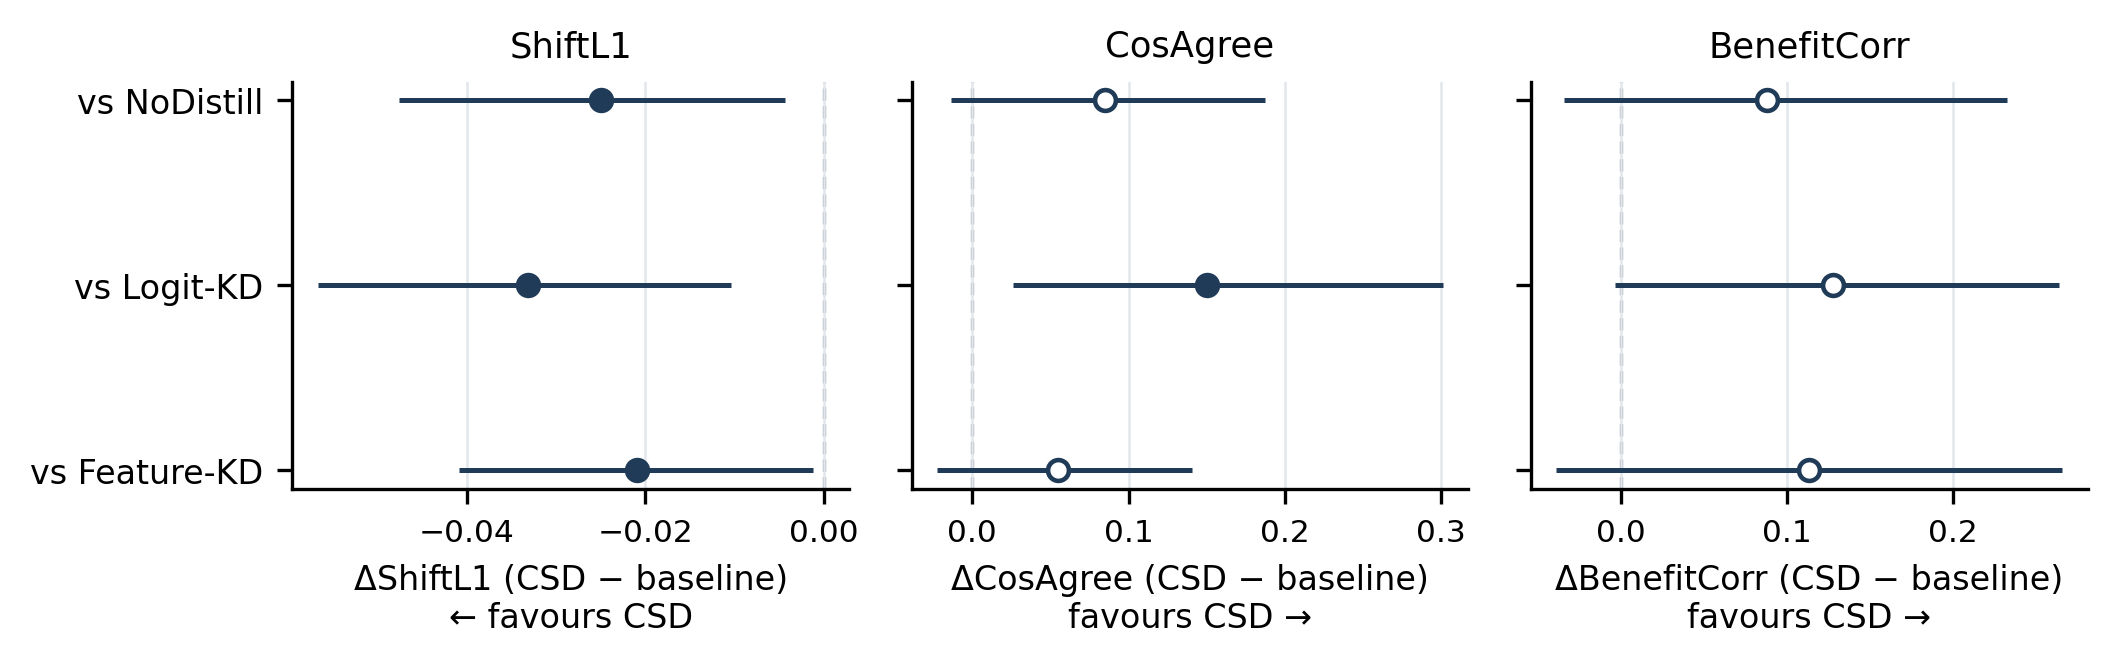

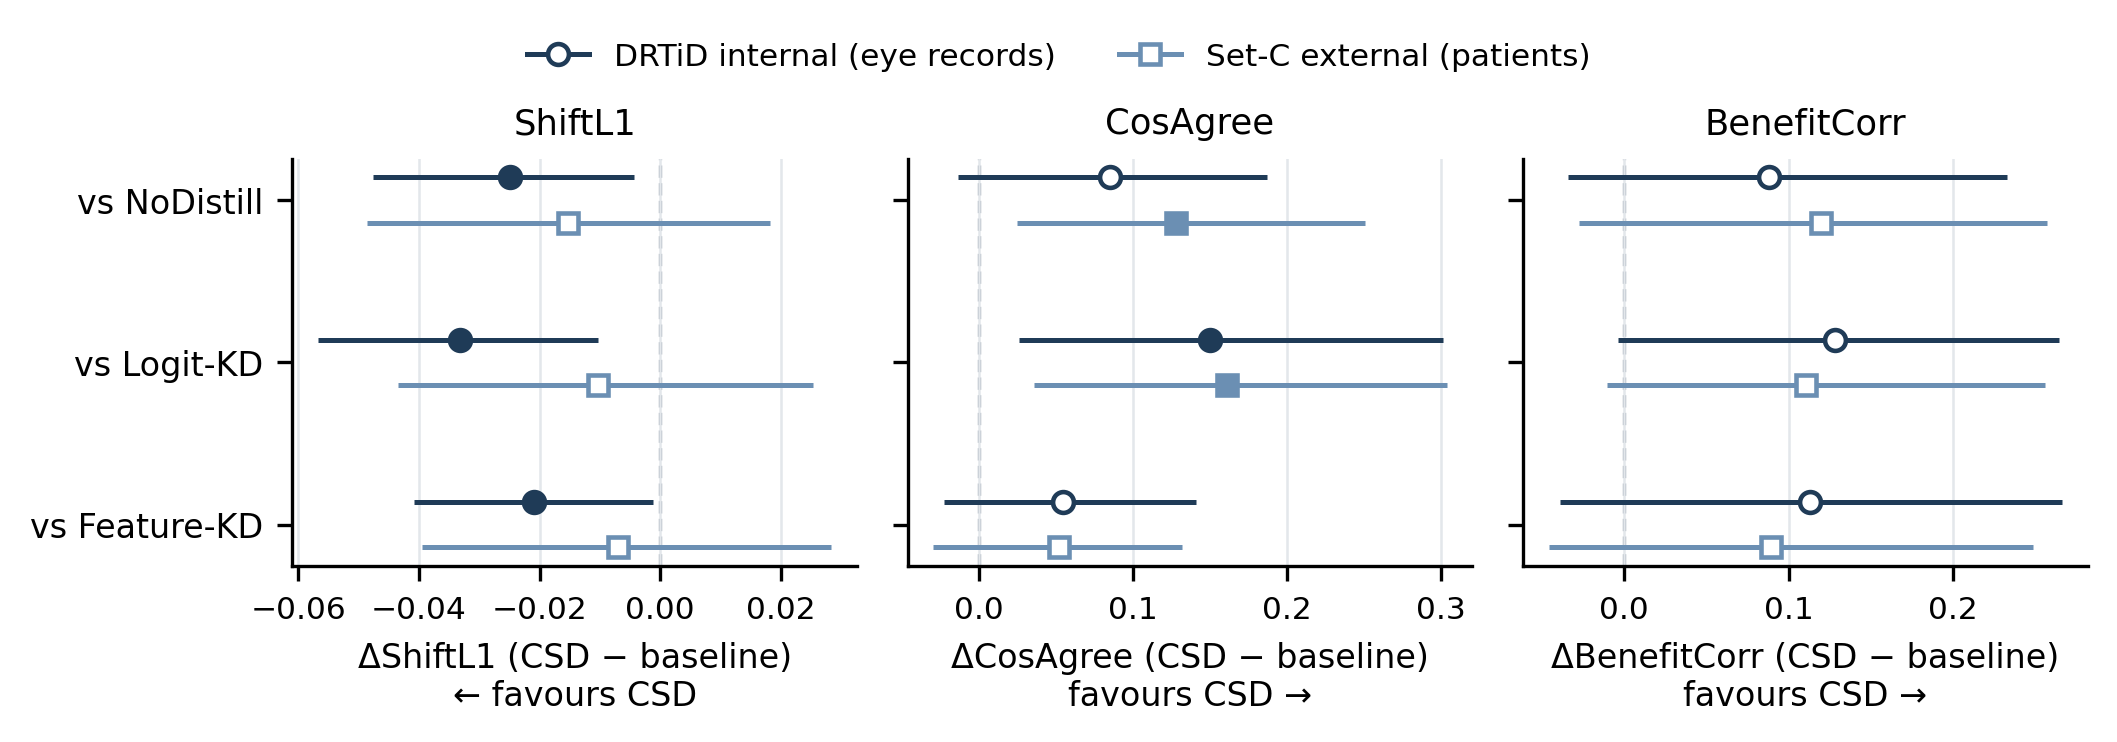

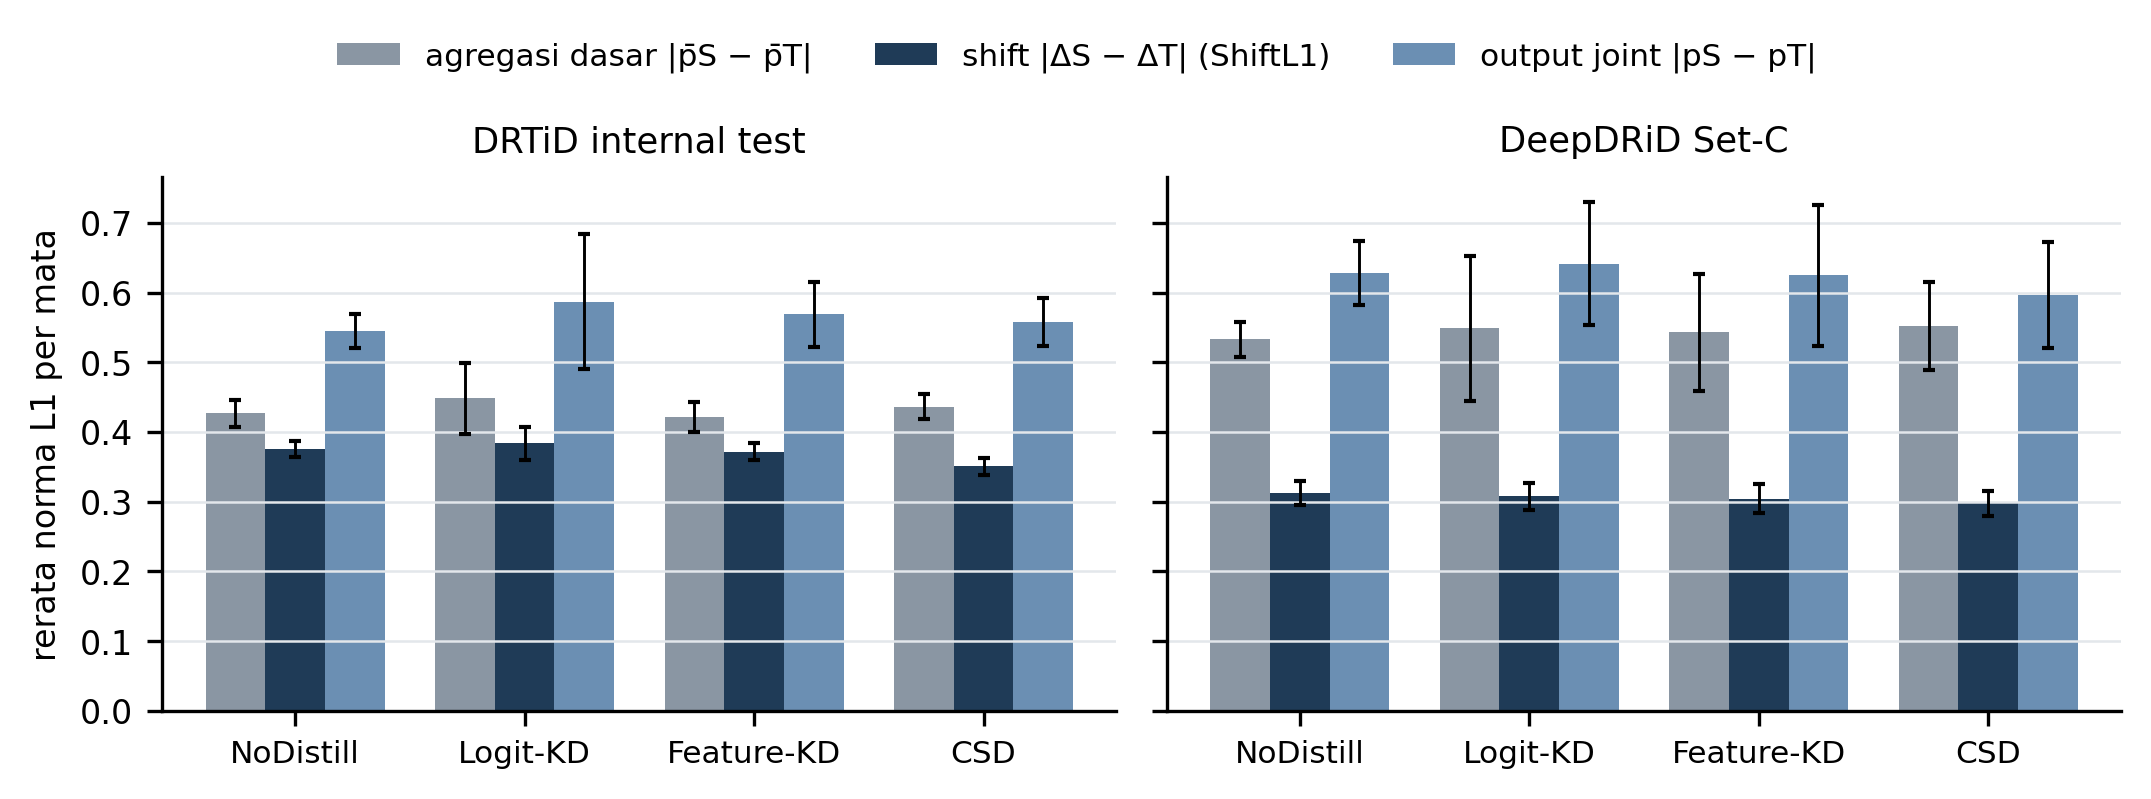

In [20]:
print("=" * 100)
print(verdict_rows().to_string(index=False))
print("\nINTERNAL — CSD minus baseline, 95% hierarchical CI")
print(STATS_INT[_show].round(4).to_string(index=False))
if STATS_EXT is not None:
    print("\nEXTERNAL (Set-C, exploratory, patient-clustered)")
    print(STATS_EXT[_show].round(4).to_string(index=False))
print("\nRuntime profile (s):")
print(pd.DataFrame(RUNTIME).to_string(index=False))
print("\nOutputs:", SUPP_ART)
for d in (PAPER, TABLES, FIGS, REPORTS):
    print(" ", os.path.relpath(d, SUPP_ART) + "/", sorted(os.listdir(d)))
try:
    from IPython.display import Image as _Img, display as _display
    for _f in ("fig_mechanism_effect_forest.png", "fig_internal_external_mechanism.png", "fig_mechanism_decomposition.png"):
        if os.path.exists(f"{FIGS}/{_f}"): _display(_Img(filename=f"{FIGS}/{_f}", width=900))
except Exception as _e:
    print("(figures saved; inline preview unavailable:", _e, ")")